In [ ]:
# Manipulación de datos
import pandas as pd
import numpy as np
import kagglehub

# Visualización
import matplotlib.pyplot as plt

# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Evaluación
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score
)

# Álgebra lineal
from scipy.linalg import cho_factor, cho_solve

# Utilidades
from pathlib import Path
from time import perf_counter
from math import comb

# Configuración
PERCENTILES = [50, 75, 90, 95, 99]

DATA_DIR = Path("data")
RESULTS_DIR = Path("resultados")

RESULTS_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)

print("Librerías importadas correctamente")

Librerías importadas correctamente


In [4]:
# Download latest version
path = Path(
    kagglehub.dataset_download(
        "mohankrishnathalla/credit-card-fraud-detection-dataset-2026"
    )
)

print("Path to dataset files:", path)

# Load dataset
df = pd.read_csv(
    path / "credit_card_fraud_detection_2026.csv"
)

display(df.head())

Path to dataset files: C:\Users\ivans\.cache\kagglehub\datasets\mohankrishnathalla\credit-card-fraud-detection-dataset-2026\versions\46


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,6630.0,742,2,1,2,3,88.91,209.94,0.9,13.0,0.3,0,0,0.398,0,0,Online,Mobile,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,4350.0,602,1,6,6,23,1290.10,1093.31,6.6,5311.8,17.0,1,0,0.278,1,1,In-store,POS Terminal,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,3950.0,605,4,1,1,3,36.27,46.54,4.2,14164.5,53.2,1,0,0.925,0,0,Online,Desktop,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.0
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,0,51,Female,OH,582,13870.0,675,5,0,2,3,0.00,134.35,3.0,1119.1,3.6,1,1,0.718,0,1,ATM,ATM,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.0
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,6570.0,743,2,1,2,2,38.37,117.74,0.9,6564.5,22.4,1,0,1.317,1,0,In-store,POS Terminal,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.0


### Fase 3. Adquisición y preparación de los datos

In [5]:
n, d = df.shape

print(f"Número de observaciones (n): {n:,}")
print(f"Número de columnas (d): {d}")
print(f"Registros duplicados: {df.duplicated().sum():,}")

Número de observaciones (n): 100,000
Número de columnas (d): 43
Registros duplicados: 0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  object 
 1   customer_id                  100000 non-null  object 
 2   card_id                      100000 non-null  object 
 3   merchant_id                  100000 non-null  object 
 4   transaction_datetime         100000 non-null  object 
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  object 
 7   merchant_country             100000 non-null  object 
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  object 
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  object 
 13  

In [7]:
df_diagnostico = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "valores_nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean() * 100
})

display(df_diagnostico)

,tipo_dato,valores_unicos,valores_nulos,porcentaje_nulos
transaction_id,object,100000,0,0.000
customer_id,object,8000,0,0.000
card_id,object,8000,0,0.000
merchant_id,object,3000,0,0.000
transaction_datetime,object,99762,0,0.000
transaction_amount,float64,30862,0,0.000
merchant_category,object,15,0,0.000
merchant_country,object,20,0,0.000
transaction_hour,int64,24,0,0.000
transaction_day_of_week,object,7,0,0.000


#### Solo hay una columna con valores nulos y es 'browser'; es decir, de qué navegador se hizo la consulta. Es una variable categórica

In [8]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
transaction_amount,100000.0,126.871977,276.180425,0.500,21.2800,52.260,129.72000,15000.000
transaction_hour,100000.0,14.393860,5.018253,0.000,11.0000,14.000,19.00000,23.000
card_present,100000.0,0.357770,0.479346,0.000,0.0000,0.000,1.00000,1.000
customer_age,100000.0,42.223670,14.246361,18.000,32.0000,42.000,52.00000,85.000
account_age_days,100000.0,785.451240,747.492434,1.000,233.0000,554.000,1103.00000,3650.000
credit_limit,100000.0,10083.182000,6510.646682,500.000,5000.0000,8500.000,13650.00000,36670.000
credit_score,100000.0,682.329280,92.122179,328.000,620.0000,683.000,748.00000,850.000
num_cards_held,100000.0,2.198830,1.163491,1.000,1.0000,2.000,3.00000,5.000
transactions_last_1h,100000.0,0.783890,1.348801,0.000,0.0000,0.000,1.00000,8.000
transactions_last_24h,100000.0,2.951760,2.382417,0.000,1.0000,2.000,4.00000,18.000


In [9]:
# Seleccionar solo México de la lista de países
df["merchant_country"].value_counts()

merchant_country
USA             44515
UK               8349
Canada           7238
Germany          5651
Australia        5423
France           4521
Italy            3344
Netherlands      3039
Spain            2849
Brazil           2354
India            2175
Mexico           1921
China            1682
Nigeria          1261
South Africa     1140
Russia           1046
Romania           943
UAE               940
Japan             821
South Korea       788
Name: count, dtype: int64

In [10]:
df_mx = df[df["merchant_country"] == "Mexico"].copy()

n, d = df_mx.shape

print(f"Transacciones en México: {n:,}")
print(f"Número de columnas: {d}")
print(f"Porcentaje del dataset original: {n / len(df):.2%}")

Transacciones en México: 1,921
Número de columnas: 43
Porcentaje del dataset original: 1.92%


,cantidad,porcentaje
is_fraud,,
0,1869,97.293077
1,52,2.706923


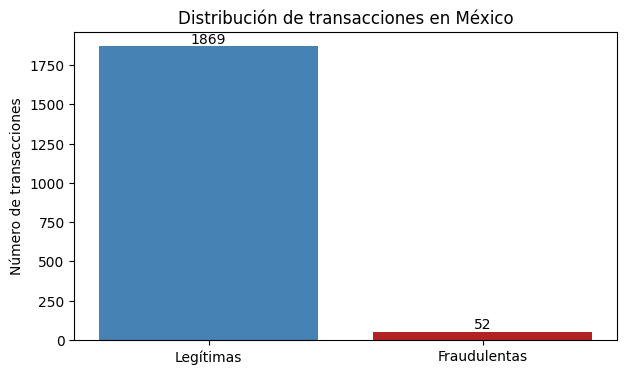

In [11]:
df_distribucion = pd.DataFrame({
    "cantidad": df_mx["is_fraud"].value_counts(),
    "porcentaje": df_mx["is_fraud"].value_counts(normalize=True) * 100
}).sort_index()

display(df_distribucion)

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ["Legítimas", "Fraudulentas"],
    df_distribucion.loc[[0, 1], "cantidad"],
    color=["steelblue", "firebrick"]
)

ax.set_title("Distribución de transacciones en México")
ax.set_ylabel("Número de transacciones")

ax.bar_label(ax.containers[0])

plt.show()

---

### Fase 4. Procesamiento de los datos

In [12]:
display(
    df_mx.groupby("is_fraud")["fraud_amount_lost"]
    .agg(["count", "min", "max", "mean", "std"])
)

,count,min,max,mean,std
is_fraud,,,,,
0,1869,0.00,0.00,0.000000,0.000000
1,52,3.64,1781.88,200.687692,306.026875


In [13]:
y = df_mx["is_fraud"].copy()

X = df_mx.select_dtypes(include='number').copy()

# Excluir columnas que no se usarán como features
columnas_excluir = ["is_fraud", "fraud_amount_lost"]
X = X.drop(columns=columnas_excluir)

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

Dimensiones de X: (1921, 26)
Dimensiones de y: (1921,)


In [14]:
# Una característica constante tiene una varianza igual a cero; por lo tanto, no aporta información para distinguir una transacción de otra.
columnas_constantes = X.columns[X.nunique() <= 1].tolist()
print("Columnas constantes:", columnas_constantes)

Columnas constantes: ['international_transaction', 'high_risk_country']


In [15]:
X = X.drop(columns=columnas_constantes)
print(f"Dimensiones finales de X: {X.shape}")

Dimensiones finales de X: (1921, 24)


In [16]:
# Validación de las estructuras
assert X.shape[0] == y.shape[0]
assert X.index.equals(y.index)
assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()
assert set(y.unique()) == {0, 1}

print("Validaciones exitosas.")

print(f"Número de observaciones: {X.shape[0]:,}")
print(f"Número de características: {X.shape[1]}")
print(f"Número de etiquetas: {len(y):,}")

display(X.head())

Validaciones exitosas.
Número de observaciones: 1,921
Número de características: 24
Número de etiquetas: 1,921


,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever
26,827.60,8,1,26,188,15400.0,769,1,2,2,7,147.82,166.74,1.3,6061.2,6.2,9.194,0,0,0,90.02,65.89,0,0
54,62.19,9,1,52,2129,14520.0,734,4,1,1,1,81.43,89.41,10.1,12923.8,6.3,0.616,1,0,0,100.98,46.77,0,0
61,71.10,10,0,52,143,4730.0,561,2,1,5,8,68.33,431.55,4.0,6275.5,31.3,0.895,0,0,0,79.40,58.88,0,0
74,13.63,11,0,46,387,4300.0,593,2,0,0,0,0.00,0.00,1.0,11521.2,6064.6,0.418,0,0,0,32.58,13.23,2,0
80,103.65,11,0,31,379,10650.0,671,2,0,3,3,0.00,410.89,2.3,3960.3,23.4,0.899,0,0,0,115.25,83.16,0,0


#### 4.2. División de los datos

In [17]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y # Preserva aproximadamente la proporción de ambas clases en los conjuntos de entrenamiento y prueba
)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

X_train: (1536, 24)
X_test:  (385, 24)
y_train: (1536,)
y_test:  (385,)


In [18]:
df_particiones = pd.DataFrame({
    "Total": y.value_counts(),
    "Entrenamiento": y_train.value_counts(),
    "Prueba": y_test.value_counts()
}).sort_index()

df_particiones.index = ["Legítimas", "Fraudulentas"]

display(df_particiones)

df_proporciones = (
    df_particiones / df_particiones.sum()
) * 100

display(df_proporciones.round(2))

,Total,Entrenamiento,Prueba
Legítimas,1869,1494,375
Fraudulentas,52,42,10


,Total,Entrenamiento,Prueba
Legítimas,97.29,97.27,97.4
Fraudulentas,2.71,2.73,2.6


In [19]:
assert len(X_train) + len(X_test) == len(X)

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

assert X_train.index.intersection(X_test.index).empty

print("División de datos validada correctamente.")

División de datos validada correctamente.


#### 4.3. Estandarización de los datos

In [20]:
scaler = StandardScaler()

# Ajustar y transformar el conjunto de entrenamiento: fit() calcula las medias y desviación estándar, transform() aplica la transformación a los datos y fit_transform() hace ambas
X_train_scaled = scaler.fit_transform(X_train)

# Transformar el conjunto de prueba
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}")

X_train_scaled: (1536, 24)
X_test_scaled:  (385, 24)


In [21]:
df_scaler = pd.DataFrame({
    "caracteristica": X_train.columns,
    "media": scaler.mean_,
    "desviacion_estandar": scaler.scale_,
    "varianza": scaler.var_
})
print("Distribución de los datos antes de la escala:")
display(df_scaler.round(4))

Distribución de los datos antes de la escala:


,caracteristica,media,desviacion_estandar,varianza
0,transaction_amount,157.2592,342.5759,1.173582e+05
1,transaction_hour,14.5742,4.9317,2.432130e+01
2,card_present,0.3607,0.4802,2.306000e-01
3,customer_age,42.5091,14.7738,2.182642e+02
4,account_age_days,795.2409,761.5321,5.799311e+05
5,credit_limit,10134.5052,6518.2369,4.248741e+07
6,credit_score,683.8652,92.8787,8.626460e+03
7,num_cards_held,2.2031,1.1672,1.362400e+00
8,transactions_last_1h,0.8047,1.4044,1.972300e+00
9,transactions_last_24h,3.0039,2.4466,5.985700e+00


In [22]:
df_validacion_scaler = pd.DataFrame({
    "caracteristica": X_train.columns,
    "media_train": X_train_scaled.mean(axis=0),
    "std_train": X_train_scaled.std(axis=0),
    "media_test": X_test_scaled.mean(axis=0),
    "std_test": X_test_scaled.std(axis=0)
})
print("Distribución de los datos después de la escala:")
display(df_validacion_scaler.round(6))

Distribución de los datos después de la escala:


,caracteristica,media_train,std_train,media_test,std_test
0,transaction_amount,0.0,1.0,-0.036669,0.620794
1,transaction_hour,-0.0,1.0,-0.108008,1.005837
2,card_present,0.0,1.0,0.060253,1.015546
3,customer_age,-0.0,1.0,-0.002463,0.972723
4,account_age_days,0.0,1.0,-0.004819,0.970671
5,credit_limit,-0.0,1.0,0.014332,1.012189
6,credit_score,0.0,1.0,0.047286,1.023958
7,num_cards_held,0.0,1.0,-0.056085,0.956326
8,transactions_last_1h,-0.0,1.0,0.011458,0.971483
9,transactions_last_24h,-0.0,1.0,-0.032385,0.997901


In [23]:
# Parámetros calculados exclusivamente sobre entrenamiento
mu = X_train.to_numpy().mean(axis=0)
sigma = X_train.to_numpy().std(axis=0, ddof=0)

# Estandarización manual
X_train_manual = (X_train.to_numpy() - mu) / sigma
X_test_manual = (X_test.to_numpy() - mu) / sigma

# Comparación con Scikit-learn
print(
    "Entrenamiento:",
    np.allclose(X_train_manual, X_train_scaled)
)

print(
    "Prueba:",
    np.allclose(X_test_manual, X_test_scaled)
)

Entrenamiento: True
Prueba: True


#### 4.4. Análisis de componentes principales (PCA), pasando de R^24 a R^10

In [24]:
N_COMPONENTS = 10

pca = PCA(n_components=N_COMPONENTS, svd_solver="full") # Para analizar Singular Value Decomposition (SVD)

# Ajustar y proyectar los datos de entrenamiento
X_train_pca = pca.fit_transform(X_train_scaled)

# Proyectar los datos de prueba
X_test_pca = pca.transform(X_test_scaled)

print(f"X_train_pca: {X_train_pca.shape}")
print(f"X_test_pca:  {X_test_pca.shape}")

X_train_pca: (1536, 10)
X_test_pca:  (385, 10)


In [25]:
df_varianza = pd.DataFrame({
    "componente": [
        f"PC{i+1}" for i in range(N_COMPONENTS)
    ],
    "valor_singular": pca.singular_values_,
    "valor_propio": pca.explained_variance_,
    "varianza_explicada_pct": (
        pca.explained_variance_ratio_ * 100
    ),
    "varianza_acumulada_pct": (
        np.cumsum(pca.explained_variance_ratio_) * 100
    )
})

display(df_varianza.round(4))

,componente,valor_singular,valor_propio,varianza_explicada_pct,varianza_acumulada_pct
0,PC1,70.4520,3.2335,13.4643,13.4643
1,PC2,56.1616,2.0548,8.5561,22.0204
2,PC3,55.2398,1.9879,8.2776,30.2980
3,PC4,52.3394,1.7846,7.4311,37.7291
4,PC5,50.2551,1.6453,6.8511,44.5802
5,PC6,41.5147,1.1228,4.6752,49.2554
6,PC7,40.8692,1.0881,4.5310,53.7863
7,PC8,40.7707,1.0829,4.5091,58.2955
8,PC9,40.1196,1.0486,4.3663,62.6617
9,PC10,39.6342,1.0234,4.2613,66.9230


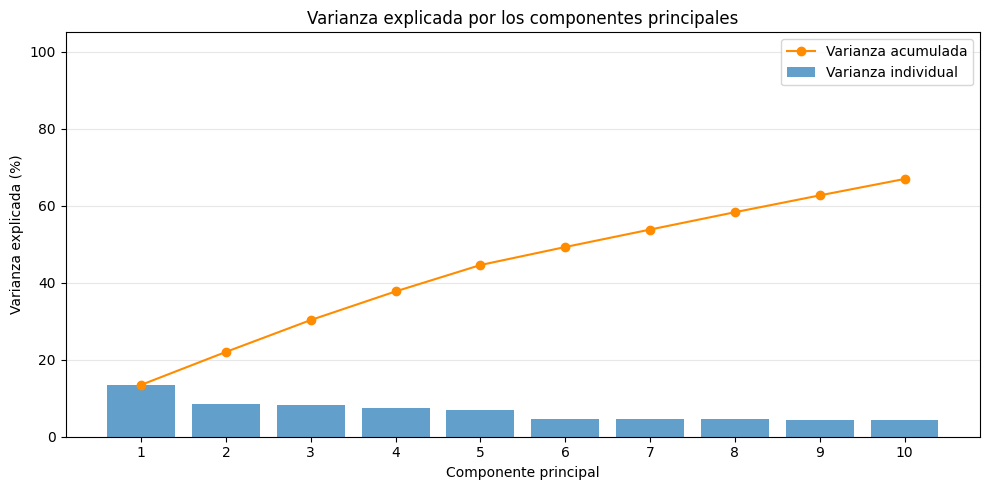

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))

componentes = np.arange(1, N_COMPONENTS + 1)

ax.bar(
    componentes,
    df_varianza["varianza_explicada_pct"],
    alpha=0.7,
    label="Varianza individual"
)

ax.plot(
    componentes,
    df_varianza["varianza_acumulada_pct"],
    marker="o",
    color="darkorange",
    label="Varianza acumulada"
)

ax.set_title("Varianza explicada por los componentes principales")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax.set_xticks(componentes)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
def varianza_explicada(k):
    return pca.explained_variance_ratio_[:k].sum() * 100


for k in [2, 5, 7, 10]:
    print(
        f"{k:2} componentes: "
        f"{varianza_explicada(k):.2f}% de varianza explicada"
    )

 2 componentes: 22.02% de varianza explicada
 5 componentes: 44.58% de varianza explicada
 7 componentes: 53.79% de varianza explicada
10 componentes: 66.92% de varianza explicada


### 4.5. Fundamento matemático de PCA mediante SVD
#### 4.5.1. Descomposición en valores singulares

In [28]:
# Centrar la matriz estandarizada
Z = X_train_scaled - X_train_scaled.mean(axis=0)

# Descomposición en valores singulares reducida
U, s, Vt = np.linalg.svd(
    Z,
    full_matrices=False
)

# Construcción de la matriz diagonal
Sigma = np.diag(s)

print(f"Dimensiones de Z:     {Z.shape}")
print(f"Dimensiones de U:     {U.shape}")
print(f"Dimensiones de Sigma: {Sigma.shape}")
print(f"Dimensiones de Vt:    {Vt.shape}")

Dimensiones de Z:     (1536, 24)
Dimensiones de U:     (1536, 24)
Dimensiones de Sigma: (24, 24)
Dimensiones de Vt:    (24, 24)


In [29]:
# Verificar la descomposición
Z_reconstruida = U @ Sigma @ Vt

print(
    "Reconstrucción correcta:",
    np.allclose(Z, Z_reconstruida)
)

Reconstrucción correcta: True


In [30]:
print("Columnas ortonormales de U:", np.allclose(U.T @ U, np.eye(U.shape[1])))

print("Columnas ortonormales de V:", np.allclose(Vt @ Vt.T, np.eye(Vt.shape[0])))

Columnas ortonormales de U: True
Columnas ortonormales de V: True


#### 4.5.2. Relación entre SVD y la matriz de covarianza

In [31]:
n = Z.shape[0]

valores_propios = s**2 / (n - 1)

df_svd = pd.DataFrame({
    "componente": [
        f"PC{i+1}" for i in range(len(s))
    ],
    "valor_singular": s,
    "valor_propio": valores_propios,
    "varianza_explicada_pct": (
        valores_propios / valores_propios.sum()
    ) * 100
})

display(df_svd.round(4))

,componente,valor_singular,valor_propio,varianza_explicada_pct
0,PC1,70.4520,3.2335,13.4643
1,PC2,56.1616,2.0548,8.5561
2,PC3,55.2398,1.9879,8.2776
3,PC4,52.3394,1.7846,7.4311
4,PC5,50.2551,1.6453,6.8511
5,PC6,41.5147,1.1228,4.6752
6,PC7,40.8692,1.0881,4.5310
7,PC8,40.7707,1.0829,4.5091
8,PC9,40.1196,1.0486,4.3663
9,PC10,39.6342,1.0234,4.2613


In [32]:
print(
    "Coincidencia de valores singulares:",
    np.allclose(
        s[:10],
        pca.singular_values_
    )
)

print(
    "Coincidencia de valores propios:",
    np.allclose(
        valores_propios[:10],
        pca.explained_variance_
    )
)

print(
    "Coincidencia de varianza explicada:",
    np.allclose(
        valores_propios[:10] / valores_propios.sum(),
        pca.explained_variance_ratio_
    )
)

Coincidencia de valores singulares: True
Coincidencia de valores propios: True
Coincidencia de varianza explicada: True


In [33]:
print(f"Suma de valores propios: {valores_propios.sum():.6f}")

Suma de valores propios: 24.015635


#### 4.5.3. Reducción dimensional y proyección mediante SVD

In [34]:
k = 10

U_k = U[:, :k]
Sigma_k = np.diag(s[:k])
V_k = Vt[:k, :].T

print(f"Dimensiones de U_k:     {U_k.shape}")
print(f"Dimensiones de Sigma_k: {Sigma_k.shape}")
print(f"Dimensiones de V_k:     {V_k.shape}")

Dimensiones de U_k:     (1536, 10)
Dimensiones de Sigma_k: (10, 10)
Dimensiones de V_k:     (24, 10)


In [35]:
# Proyección mediante los vectores singulares derechos
T_train_1 = Z @ V_k

# Proyección mediante los vectores singulares izquierdos
T_train_2 = U_k @ Sigma_k

print(f"Dimensiones de T_train_1: {T_train_1.shape}")
print(f"Dimensiones de T_train_2: {T_train_2.shape}")

print(
    "Equivalencia matemática:",
    np.allclose(T_train_1, T_train_2)
)

Dimensiones de T_train_1: (1536, 10)
Dimensiones de T_train_2: (1536, 10)
Equivalencia matemática: True


In [36]:
# Vectores singulares derechos utilizados por Scikit-learn
V_sklearn = pca.components_.T

# Identificar diferencias de signo
signos = np.sign(
    np.sum(V_k * V_sklearn, axis=0)
)

# Alinear los signos
V_k_alineado = V_k * signos

print(
    "Coincidencia de componentes principales:",
    np.allclose(V_k_alineado, V_sklearn)
)

Coincidencia de componentes principales: True


In [37]:
T_train_manual = Z @ V_k_alineado

print(
    "Coincidencia de proyección de entrenamiento:",
    np.allclose(T_train_manual, X_train_pca)
)

Coincidencia de proyección de entrenamiento: True


In [38]:
# Centrar los datos de prueba con la media de entrenamiento
Z_test_centrado = (
    X_test_scaled - X_train_scaled.mean(axis=0)
)

# Proyectar utilizando la base obtenida en entrenamiento
T_test_manual = Z_test_centrado @ V_k_alineado

print(f"Dimensiones originales: {X_test_scaled.shape}")
print(f"Dimensiones reducidas:  {T_test_manual.shape}")

print(
    "Coincidencia de proyección de prueba:",
    np.allclose(T_test_manual, X_test_pca)
)

Dimensiones originales: (385, 24)
Dimensiones reducidas:  (385, 10)
Coincidencia de proyección de prueba: True


In [39]:
print(
    "Base ortonormal:",
    np.allclose(
        V_k_alineado.T @ V_k_alineado,
        np.eye(k)
    )
)

Base ortonormal: True


---
## 5. Detección de fraude mediante la distancia de Mahalanobis
### 5.1. Preparación de los datos en dos dimensiones

In [40]:
# Máscaras booleanas
mask_legit = y_train.to_numpy() == 0
mask_fraud = y_train.to_numpy() == 1

# Separación de las transacciones de entrenamiento
X_train_legit = X_train_pca[mask_legit]
X_train_fraud = X_train_pca[mask_fraud]

print(f"Transacciones legítimas:    {X_train_legit.shape}")
print(f"Transacciones fraudulentas: {X_train_fraud.shape}")

Transacciones legítimas:    (1494, 10)
Transacciones fraudulentas: (42, 10)


In [41]:
k = 2 # Seleccionar los primeros dos componentes

X_legit_2d = X_train_legit[:, :k]
X_fraud_2d = X_train_fraud[:, :k]

print(f"X_legit_2d: {X_legit_2d.shape}")
print(f"X_fraud_2d: {X_fraud_2d.shape}")

print(f"Varianza explicada: {varianza_explicada(k):.4f}%")

X_legit_2d: (1494, 2)
X_fraud_2d: (42, 2)
Varianza explicada: 22.0204%


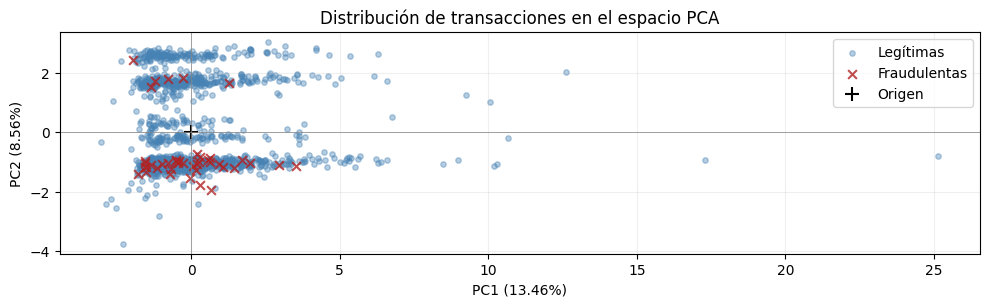

In [42]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.4,
    s=15,
    label="Legítimas"
)

ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    alpha=0.8,
    s=40,
    marker="x",
    label="Fraudulentas"
)

# Origen del espacio PCA
ax.scatter(
    0, 0,
    color="black",
    marker="+",
    s=100,
    label="Origen"
)

ax.set_title("Distribución de transacciones en el espacio PCA")
ax.set_xlabel(f"PC1 ({varianza_explicada(1):.2f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

- Solapamiento entre clases: una cantidad considerable de transacciones fraudulentas se encuentra dentro de regiones densamente pobladas por transacciones legítimas.
- Concentración del fraude: visualmente, la mayoría de las transacciones fraudulentas se concentra alrededor de PC2 = −1.
- Valores extremos legítimos: existen transacciones legítimas considerablemente alejadas del origen, particularmente sobre el eje PC1, donde una observación alcanza aproximadamente 25.
- Estructura no elíptica: las observaciones parecen distribuirse en bandas horizontales. Esto podría estar relacionado con la influencia de las variables binarias originales sobre los componentes principales, aunque todavía no lo hemos comprobado.

#### 5.2. Construcción de la matriz de covarianza

In [43]:
# Media de las transacciones legítimas
mu_legit_2d = X_legit_2d.mean(axis=0)

# Matriz de covarianza muestral
Sigma_2d = np.cov(X_legit_2d,rowvar=False, ddof=1)

print("Vector de medias:")
print(mu_legit_2d)

print("\nMatriz de covarianza:")
print(Sigma_2d)

print(f"\nDimensiones: {Sigma_2d.shape}")

Vector de medias:
[0.00270276 0.01997564]

Matriz de covarianza:
[[3.28077337 0.00536361]
 [0.00536361 2.06622386]]

Dimensiones: (2, 2)


In [44]:
# Propiedades algebraicas
es_simetrica = np.allclose(Sigma_2d, Sigma_2d.T) # Permite una descomposición espectral, es decir, puede ser diagonalizada por una matriz ortogonal
rango = np.linalg.matrix_rank(Sigma_2d)
determinante = np.linalg.det(Sigma_2d)
valores_propios_maha, vectores_propios_maha = (np.linalg.eigh(Sigma_2d))
es_definida_positiva = np.all(valores_propios_maha > 0)
numero_condicion = np.linalg.cond(Sigma_2d) # Evalía la estabilidad numérica de la matriz, valores grandes indican problemas de estabilidad

print(f"Es simétrica: {es_simetrica}")
print(f"Rango: {rango}")
print(f"Determinante: {determinante:.6f}")
print(f"Valores propios: {valores_propios_maha}")
print(f"Es definida positiva: {es_definida_positiva}")
print(f"Número de condición: {numero_condicion:.6f}")

Es simétrica: True
Rango: 2
Determinante: 6.778783
Valores propios: [2.06620017 3.28079705]
Es definida positiva: True
Número de condición: 1.587841


#### 5.2.1. Interpretación geométria de la matriz de covarianza

In [45]:
Q = vectores_propios_maha
Lambda = np.diag(valores_propios_maha)

Sigma_reconstruida = Q @ Lambda @ Q.T

print(
    "Reconstrucción espectral:",
    np.allclose(Sigma_2d, Sigma_reconstruida)
)

print(
    "Base ortonormal:",
    np.allclose(Q.T @ Q, np.eye(2))
)

Reconstrucción espectral: True
Base ortonormal: True


#### 5.3. Implementación de la distancia de Mahalanobis

In [46]:
# Inversa de la matriz de covarianza
Sigma_inv_2d = np.linalg.inv(Sigma_2d)

print("Matriz de covarianza inversa:")
print(Sigma_inv_2d)

print(
    "\nValidación de la matriz inversa:",
    np.allclose(
        Sigma_2d @ Sigma_inv_2d,
        np.eye(2)
    )
)

Matriz de covarianza inversa:
[[ 0.30480747 -0.00079123]
 [-0.00079123  0.48397672]]

Validación de la matriz inversa: True


In [47]:
def distancia_mahalanobis_individual(x, Sigma_inv):
    return np.sqrt(x.T @ Sigma_inv @ x)

In [48]:
# Prueba de la función con un vector de ejemplo
x = X_legit_2d[0]

distancia = distancia_mahalanobis_individual(
    x,
    Sigma_inv_2d
)

print(f"Transacción: {x}")
print(f"Distancia de Mahalanobis: {distancia:.6f}")

Transacción: [-0.70483785 -0.90982363]
Distancia de Mahalanobis: 0.742319


In [49]:
def distancia_mahalanobis(X, Sigma):
    X = np.atleast_2d(X)

    # Resolver Sigma @ W.T = X.T
    W = np.linalg.solve(Sigma, X.T).T

    # Calcular la forma cuadrática por observación
    distancias_cuadradas = np.sum(X * W, axis=1)

    # Evitar valores negativos por redondeo numérico
    return np.sqrt(np.maximum(distancias_cuadradas, 0))

In [50]:
distancia_vectorizada = distancia_mahalanobis(
    X_legit_2d[:1],
    Sigma_2d
)[0]

print(
    "Coincidencia entre implementaciones:",
    np.isclose(distancia, distancia_vectorizada)
)

Coincidencia entre implementaciones: True


In [51]:
distancias_legit_2d = distancia_mahalanobis(
    X_legit_2d,
    Sigma_2d
)

distancias_fraud_2d = distancia_mahalanobis(
    X_fraud_2d,
    Sigma_2d
)

print(f"Distancias legítimas: {distancias_legit_2d.shape}")
print(f"Distancias fraudulentas: {distancias_fraud_2d.shape}")

Distancias legítimas: (1494,)
Distancias fraudulentas: (42,)


In [52]:
df_distancias_2d = pd.DataFrame({
    "Legítimas": pd.Series(distancias_legit_2d),
    "Fraudulentas": pd.Series(distancias_fraud_2d)
})

display(df_distancias_2d.describe().round(4))

,Legítimas,Fraudulentas
count,1494.0000,42.0000
mean,1.2035,1.0697
std,0.7421,0.3519
min,0.1039,0.5218
25%,0.8241,0.7703
50%,1.0235,1.0619
75%,1.3805,1.2748
max,13.8939,2.0943


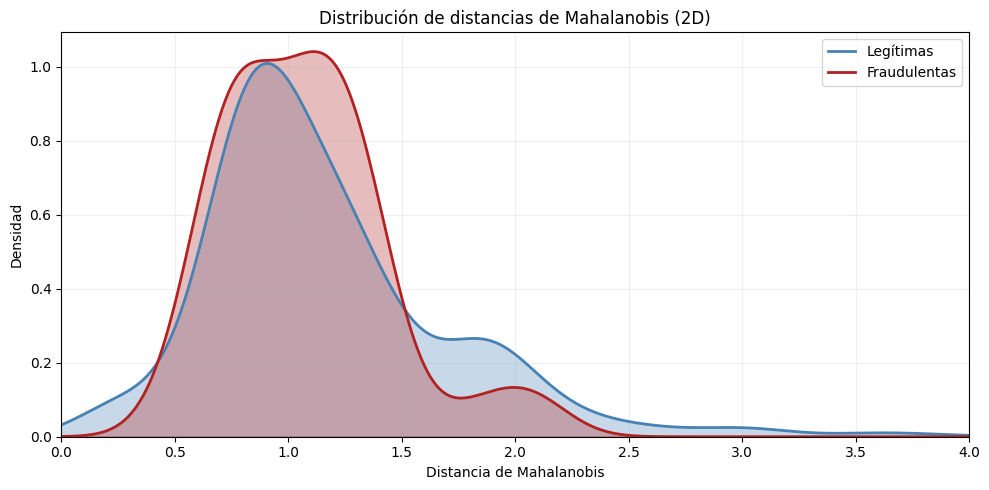

In [53]:
from scipy.stats import gaussian_kde

# Estimación de densidad para cada clase
kde_legit = gaussian_kde(distancias_legit_2d)
kde_fraud = gaussian_kde(distancias_fraud_2d)

# Dominio de evaluación
x = np.linspace(
    0,
    max(distancias_legit_2d.max(), distancias_fraud_2d.max()),
    1000
)

# Evaluación de las funciones de densidad
densidad_legit = kde_legit(x)
densidad_fraud = kde_fraud(x)

# Visualización
fig, ax = plt.subplots(figsize=(10, 5))

# Transacciones legítimas
ax.plot(
    x, densidad_legit,
    color="steelblue",
    linewidth=2,
    label="Legítimas"
)

ax.fill_between(
    x, densidad_legit,
    color="steelblue",
    alpha=0.3
)

# Transacciones fraudulentas
ax.plot(
    x, densidad_fraud,
    color="firebrick",
    linewidth=2,
    label="Fraudulentas"
)

ax.fill_between(
    x, densidad_fraud,
    color="firebrick",
    alpha=0.3
)

ax.set_title("Distribución de distancias de Mahalanobis (2D)")
ax.set_xlabel("Distancia de Mahalanobis")
ax.set_ylabel("Densidad")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.2)
ax.set_xlim(0,4)

plt.tight_layout()
plt.show()

Las transacciones fraudulentas no presentan sistemáticamente distancias mayores que las legítimas. De hecho, las transacciones legítimas presentan una media superior y una cola derecha considerablemente más extensa.

#### 5.4. Construcción de radios mediante percentiles empíricos

In [54]:
# Determinar el número de observaciones necesarias para cada percentil
PERCENTILES = [50, 75, 90, 95, 99]

N = len(distancias_legit_2d)

df_objetivos = pd.DataFrame({
    "percentil": PERCENTILES,
    "observaciones_minimas": [
        int(np.ceil(p * N / 100))
        for p in PERCENTILES
    ]
})

display(df_objetivos)

,percentil,observaciones_minimas
0,50,747
1,75,1121
2,90,1345
3,95,1420
4,99,1480


In [55]:
# Calcular los radios de Mahalanobis para los percentiles especificados
def calcular_radios(scores, percentiles=PERCENTILES):
    scores_ordenados = np.sort(scores)
    N = len(scores_ordenados)

    radios = {}

    for p in percentiles:
        m = int(np.ceil(p * N / 100))

        # Python comienza a indexar desde cero
        radios[p] = scores_ordenados[m - 1]

    return radios

In [56]:
radios_maha_2d = calcular_radios(distancias_legit_2d)

for p, radio in radios_maha_2d.items():
    print(f"Radio {p}%: {radio:.6f}")

Radio 50%: 1.022705
Radio 75%: 1.380520
Radio 90%: 1.921903
Radio 95%: 2.175282
Radio 99%: 3.637514


In [57]:
# Cobertura de las regiones
resultados_cobertura = []

for p, radio in radios_maha_2d.items():

    dentro = np.sum(distancias_legit_2d <= radio)
    fuera = np.sum(distancias_legit_2d > radio)

    cobertura = dentro / N * 100

    resultados_cobertura.append({
        "percentil": p,
        "radio": radio,
        "legitimas_dentro": dentro,
        "legitimas_fuera": fuera,
        "cobertura_pct": cobertura,
        "cumple_condicion": p <= cobertura < p + 1
    })

df_cobertura_maha_2d = pd.DataFrame(
    resultados_cobertura
)

display(df_cobertura_maha_2d.round(4))

,percentil,radio,legitimas_dentro,legitimas_fuera,cobertura_pct,cumple_condicion
0,50,1.0227,747,747,50.0000,True
1,75,1.3805,1121,373,75.0335,True
2,90,1.9219,1345,149,90.0268,True
3,95,2.1753,1420,74,95.0469,True
4,99,3.6375,1480,14,99.0629,True


In [58]:
# Cobertura de las regiones para transacciones fraudulentas
resultados_fraude = []

N_fraud = len(distancias_fraud_2d)

for p, radio in radios_maha_2d.items():

    dentro = np.sum(distancias_fraud_2d <= radio)
    fuera = np.sum(distancias_fraud_2d > radio)

    resultados_fraude.append({
        "percentil": p,
        "radio": radio,
        "fraudes_dentro": dentro,
        "fraudes_fuera": fuera,
        "fraudes_dentro_pct": dentro / N_fraud * 100,
        "fraudes_fuera_pct": fuera / N_fraud * 100
    })

df_cobertura_fraud_2d = pd.DataFrame(
    resultados_fraude
)

display(df_cobertura_fraud_2d.round(4))

,percentil,radio,fraudes_dentro,fraudes_fuera,fraudes_dentro_pct,fraudes_fuera_pct
0,50,1.0227,19,23,45.2381,54.7619
1,75,1.3805,37,5,88.0952,11.9048
2,90,1.9219,40,2,95.2381,4.7619
3,95,2.1753,42,0,100.0000,0.0000
4,99,3.6375,42,0,100.0000,0.0000


#### 5.5. Visualización de las elipses de Mahalanobis

In [59]:
def generar_elipse_mahalanobis(
    Sigma,
    radio,
    n_puntos=360
):
    # Descomposición espectral
    valores, vectores = np.linalg.eigh(Sigma)

    # Parametrización de la circunferencia unitaria
    theta = np.linspace(0, 2 * np.pi, n_puntos)

    circulo = np.array([
        np.cos(theta),
        np.sin(theta)
    ])

    # Escalamiento mediante los valores propios
    Lambda_sqrt = np.diag(np.sqrt(valores))

    # Transformación de la circunferencia en elipse
    elipse = radio * vectores @ Lambda_sqrt @ circulo

    return elipse.T

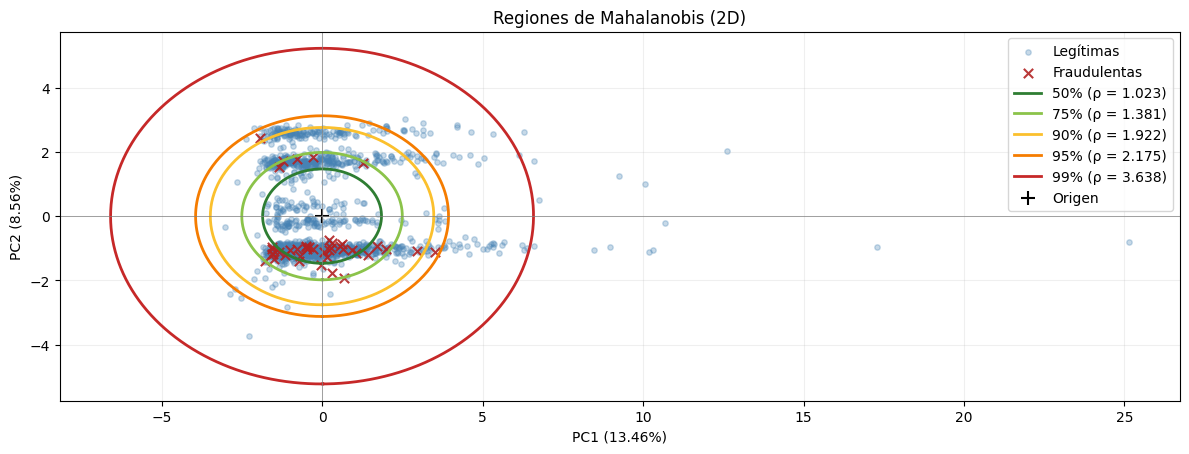

In [60]:
colores_percentiles = {
    50: "#2E7D32",
    75: "#8BC34A",
    90: "#FBC02D",
    95: "#F57C00",
    99: "#C62828"
}

fig, ax = plt.subplots(figsize=(12, 8))

# Transacciones legítimas
ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.3,
    s=15,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    alpha=0.9,
    s=45,
    marker="x",
    label="Fraudulentas"
)

# Fronteras de Mahalanobis
for p, radio in radios_maha_2d.items():

    elipse = generar_elipse_mahalanobis(
        Sigma_2d,
        radio
    )

    ax.plot(
        elipse[:, 0],
        elipse[:, 1],
        color=colores_percentiles[p],
        linewidth=2,
        label=f"{p}% (ρ = {radio:.3f})"
    )

# Origen
ax.scatter(
    0, 0,
    color="black",
    marker="+",
    s=100,
    label="Origen"
)

# Configuración de la gráfica
ax.set_title("Regiones de Mahalanobis (2D)")
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)"
)

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

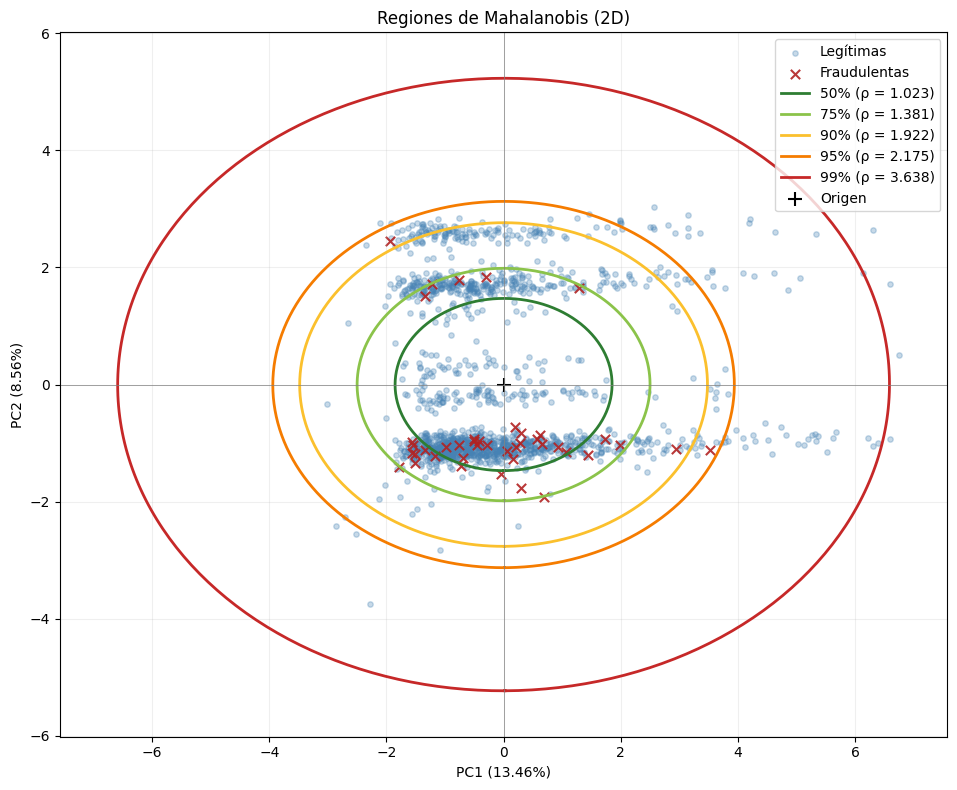

In [61]:
colores_percentiles = {
    50: "#2E7D32",
    75: "#8BC34A",
    90: "#FBC02D",
    95: "#F57C00",
    99: "#C62828"
}

fig, ax = plt.subplots(figsize=(12, 8))

# Transacciones legítimas
ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.3,
    s=15,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    alpha=0.9,
    s=45,
    marker="x",
    label="Fraudulentas"
)

# Fronteras de Mahalanobis
for p, radio in radios_maha_2d.items():

    elipse = generar_elipse_mahalanobis(
        Sigma_2d,
        radio
    )

    ax.plot(
        elipse[:, 0],
        elipse[:, 1],
        color=colores_percentiles[p],
        linewidth=2,
        label=f"{p}% (ρ = {radio:.3f})"
    )

# Origen
ax.scatter(
    0, 0,
    color="black",
    marker="+",
    s=100,
    label="Origen"
)

# Configuración de la gráfica
ax.set_title("Regiones de Mahalanobis (2D)")
ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)"
)

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")
ax.grid(alpha=0.2)

# Acercamiento basado en la elipse del 99%
elipse_99 = generar_elipse_mahalanobis(
    Sigma_2d,
    radios_maha_2d[99]
)

limite_x = np.abs(elipse_99[:, 0]).max() * 1.15
limite_y = np.abs(elipse_99[:, 1]).max() * 1.15

ax.set_xlim(-limite_x, limite_x)
ax.set_ylim(-limite_y, limite_y)

plt.tight_layout()
plt.show()


In [62]:
# Calcular las dimensiones de las elipses
resultados_elipses = []

for p, radio in radios_maha_2d.items():

    semiejes = radio * np.sqrt(valores_propios_maha)

    area = np.pi * np.prod(semiejes)

    resultados_elipses.append({
        "percentil": p,
        "radio": radio,
        "semieje_menor": semiejes.min(),
        "semieje_mayor": semiejes.max(),
        "area": area
    })

df_elipses_maha_2d = pd.DataFrame(
    resultados_elipses
)

display(df_elipses_maha_2d.round(4))

,percentil,radio,semieje_menor,semieje_mayor,area
0,50,1.0227,1.4701,1.8524,8.5551
1,75,1.3805,1.9844,2.5005,15.5887
2,90,1.9219,2.7626,3.4811,30.2126
3,95,2.1753,3.1268,3.9401,38.7041
4,99,3.6375,5.2287,6.5886,108.2269


Una transacción alejada del origen no necesariamente tiene una mayor probabilidad de ser fraudulenta. Esta es una limitación de Mahalanobis.

#### 5.6. Determinación de las regiones de seguridad y peligro

In [63]:
def asignar_regiones(scores, radios):

    limites = np.array([
        radios[p] for p in sorted(radios)
    ])

    regiones = np.searchsorted(
        limites,
        scores,
        side="left"
    )

    return regiones + 1

In [64]:
regiones_legit_2d = asignar_regiones(
    distancias_legit_2d,
    radios_maha_2d
)

regiones_fraud_2d = asignar_regiones(
    distancias_fraud_2d,
    radios_maha_2d
)

print(f"Legítimas: {regiones_legit_2d.shape}")
print(f"Fraudulentas: {regiones_fraud_2d.shape}")

Legítimas: (1494,)
Fraudulentas: (42,)


In [65]:
# Calcular el riesgo empírico para cada región de Mahalanobis
nombres_regiones = {
    1: "0% - 50%",
    2: "50% - 75%",
    3: "75% - 90%",
    4: "90% - 95%",
    5: "95% - 99%",
    6: "Exterior 99%"
}

resultados_regiones = []

for i, nombre in nombres_regiones.items():

    n_legit = np.sum(regiones_legit_2d == i)
    n_fraud = np.sum(regiones_fraud_2d == i)

    total = n_legit + n_fraud

    riesgo = n_fraud / total if total > 0 else np.nan

    resultados_regiones.append({
        "region": i,
        "intervalo": nombre,
        "legitimas": n_legit,
        "fraudulentas": n_fraud,
        "total": total,
        "riesgo_pct": riesgo * 100
    })

df_regiones_maha_2d = pd.DataFrame(
    resultados_regiones
)

display(df_regiones_maha_2d.round(4))

,region,intervalo,legitimas,fraudulentas,total,riesgo_pct
0,1,0% - 50%,747,19,766,2.4804
1,2,50% - 75%,374,18,392,4.5918
2,3,75% - 90%,224,3,227,1.3216
3,4,90% - 95%,75,2,77,2.5974
4,5,95% - 99%,60,0,60,0.0000
5,6,Exterior 99%,14,0,14,0.0000


In [66]:
# Comparar con el riesgo global
riesgo_global = y_train.mean() * 100

df_regiones_maha_2d["riesgo_relativo"] = (
    df_regiones_maha_2d["riesgo_pct"] / riesgo_global
)

print(f"Riesgo global: {riesgo_global:.4f}%")

display(df_regiones_maha_2d.round(4))

Riesgo global: 2.7344%


,region,intervalo,legitimas,fraudulentas,total,riesgo_pct,riesgo_relativo
0,1,0% - 50%,747,19,766,2.4804,0.9071
1,2,50% - 75%,374,18,392,4.5918,1.6793
2,3,75% - 90%,224,3,227,1.3216,0.4833
3,4,90% - 95%,75,2,77,2.5974,0.9499
4,5,95% - 99%,60,0,60,0.0000,0.0000
5,6,Exterior 99%,14,0,14,0.0000,0.0000


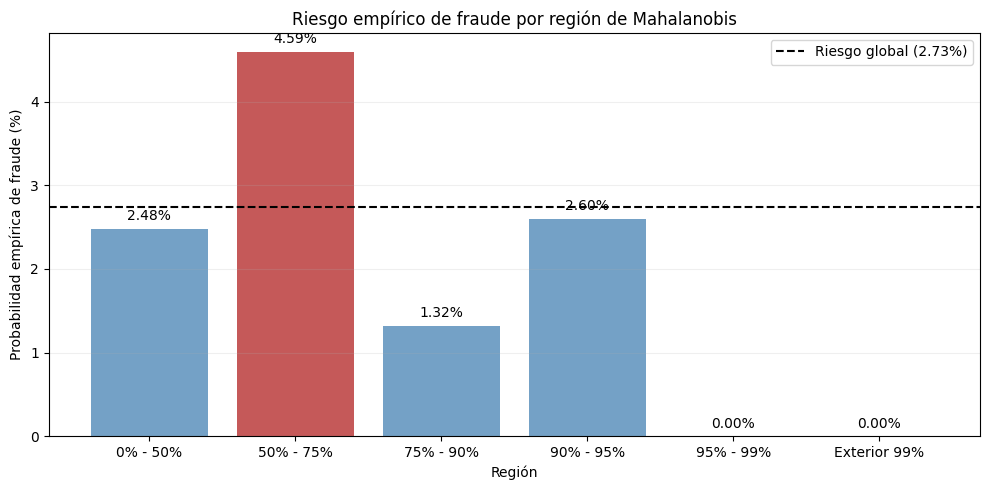

In [67]:
fig, ax = plt.subplots(figsize=(10, 5))

colores = np.where(
    df_regiones_maha_2d["riesgo_pct"] > riesgo_global,
    "firebrick",
    "steelblue"
)

barras = ax.bar(
    df_regiones_maha_2d["intervalo"],
    df_regiones_maha_2d["riesgo_pct"],
    color=colores,
    alpha=0.75
)

ax.axhline(
    riesgo_global,
    color="black",
    linestyle="--",
    label=f"Riesgo global ({riesgo_global:.2f}%)"
)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=4
)

ax.set_title("Riesgo empírico de fraude por región de Mahalanobis")
ax.set_xlabel("Región")
ax.set_ylabel("Probabilidad empírica de fraude (%)")
ax.set_ylim(bottom=0)
ax.margins(y=0.15)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

El riesgo de fraude no aumenta conforme aumenta la distancia de Mahalanobis en dos dimensiones

#### 5.7. Calibración del umbral de detección

In [68]:
def evaluar_umbral(y_real, scores, umbral):

    # Regla de clasificación
    y_pred = (scores > umbral).astype(int)

    # Matriz de confusión
    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "fpr": fp / (fp + tn),
        "specificity": tn / (tn + fp),
        "balanced_accuracy": balanced_accuracy_score(
            y_real, y_pred
        )
    }

In [69]:
scores_train_maha_2d = distancia_mahalanobis(
    X_train_pca[:, :2],
    Sigma_2d
)

resultados_umbral = []

for p, radio in radios_maha_2d.items():

    metricas = evaluar_umbral(
        y_train,
        scores_train_maha_2d,
        radio
    )

    resultados_umbral.append({
        "percentil": p,
        "radio": radio,
        **metricas
    })

df_evaluacion_maha_2d = pd.DataFrame(
    resultados_umbral
)

display(df_evaluacion_maha_2d.round(4))

,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,50,1.0227,747,747,19,23,0.0299,0.5476,0.0567,0.5000,0.5000,0.5238
1,75,1.3805,1121,373,37,5,0.0132,0.1190,0.0238,0.2497,0.7503,0.4347
2,90,1.9219,1345,149,40,2,0.0132,0.0476,0.0207,0.0997,0.9003,0.4739
3,95,2.1753,1420,74,42,0,0.0000,0.0000,0.0000,0.0495,0.9505,0.4752
4,99,3.6375,1480,14,42,0,0.0000,0.0000,0.0000,0.0094,0.9906,0.4953


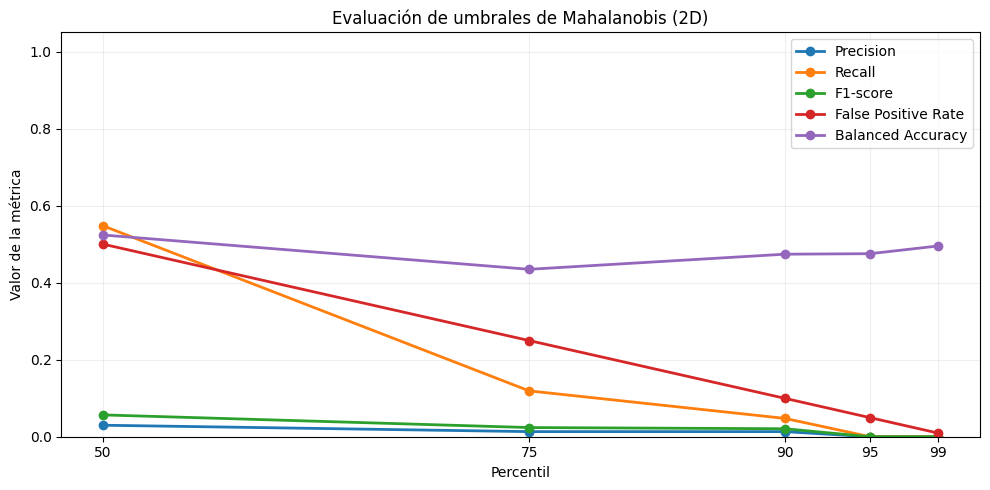

In [70]:
fig, ax = plt.subplots(figsize=(10, 5))

metricas = {
    "precision": "Precision",
    "recall": "Recall",
    "f1_score": "F1-score",
    "fpr": "False Positive Rate",
    "balanced_accuracy": "Balanced Accuracy"
}

for columna, nombre in metricas.items():

    ax.plot(
        df_evaluacion_maha_2d["percentil"],
        df_evaluacion_maha_2d[columna],
        marker="o",
        linewidth=2,
        label=nombre
    )

ax.set_title("Evaluación de umbrales de Mahalanobis (2D)")
ax.set_xlabel("Percentil")
ax.set_ylabel("Valor de la métrica")
ax.set_xticks(PERCENTILES)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [71]:
def seleccionar_umbral(df_evaluacion):

    return df_evaluacion.sort_values(
        by=["f1_score", "recall", "fpr"],
        ascending=[False, False, True]
    ).iloc[0]


mejor_maha_2d = seleccionar_umbral(
    df_evaluacion_maha_2d
)

umbral_maha_2d = mejor_maha_2d["radio"]

print(
    f"Percentil seleccionado: "
    f"{mejor_maha_2d['percentil']:.0f}%"
)

print(f"Radio seleccionado: {umbral_maha_2d:.6f}")
print(f"Precision: {mejor_maha_2d['precision']:.4f}")
print(f"Recall: {mejor_maha_2d['recall']:.4f}")
print(f"F1-score: {mejor_maha_2d['f1_score']:.4f}")
print(f"FPR: {mejor_maha_2d['fpr']:.4f}")

Percentil seleccionado: 50%
Radio seleccionado: 1.022705
Precision: 0.0299
Recall: 0.5476
F1-score: 0.0567
FPR: 0.5000


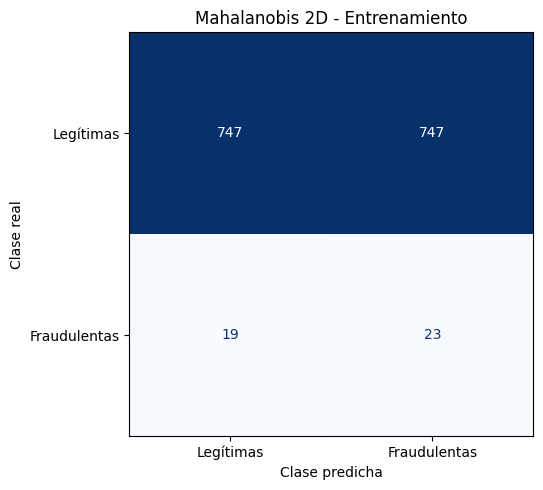

In [72]:
from sklearn.metrics import ConfusionMatrixDisplay

y_pred_train_maha_2d = (
    scores_train_maha_2d > umbral_maha_2d
).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train_maha_2d,
    labels=[0, 1],
    display_labels=["Legítimas", "Fraudulentas"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Mahalanobis 2D - Entrenamiento")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

#### 5.8. Evaluación sobre el conjunto de prueba

In [73]:
from time import perf_counter

# Seleccionar los primeros dos componentes
X_test_2d = X_test_pca[:, :2]

# Inicio de inferencia
inicio = perf_counter()

scores_test_maha_2d = distancia_mahalanobis(
    X_test_2d,
    Sigma_2d
)

# Clasificación con el umbral de entrenamiento
y_pred_test_maha_2d = (
    scores_test_maha_2d > umbral_maha_2d
).astype(int)

# Fin de inferencia
tiempo_inferencia_maha_2d = perf_counter() - inicio

print(f"Dimensiones de prueba: {X_test_2d.shape}")
print(f"Distancias calculadas: {scores_test_maha_2d.shape}")
print(f"Predicciones: {y_pred_test_maha_2d.shape}")

print(
    f"Tiempo de inferencia: "
    f"{tiempo_inferencia_maha_2d:.6f} segundos"
)

Dimensiones de prueba: (385, 2)
Distancias calculadas: (385,)
Predicciones: (385,)
Tiempo de inferencia: 0.000237 segundos


In [74]:
# Evaluación de desempeño en el conjunto de prueba
metricas_test_maha_2d = evaluar_umbral(
    y_test,
    scores_test_maha_2d,
    umbral_maha_2d
)

df_test_maha_2d = pd.DataFrame([{
    "metodo": "Mahalanobis",
    "componentes": 2,
    "varianza_explicada_pct": (
        pca.explained_variance_ratio_[:2].sum() * 100
    ),
    "percentil": mejor_maha_2d["percentil"],
    "radio": umbral_maha_2d,
    "tiempo_inferencia_s": tiempo_inferencia_maha_2d,
    **metricas_test_maha_2d
}])

display(df_test_maha_2d.round(6))

,metodo,componentes,varianza_explicada_pct,percentil,radio,tiempo_inferencia_s,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,Mahalanobis,2,22.020426,50.0,1.022705,0.000237,174,201,6,4,0.019512,0.4,0.037209,0.536,0.464,0.432


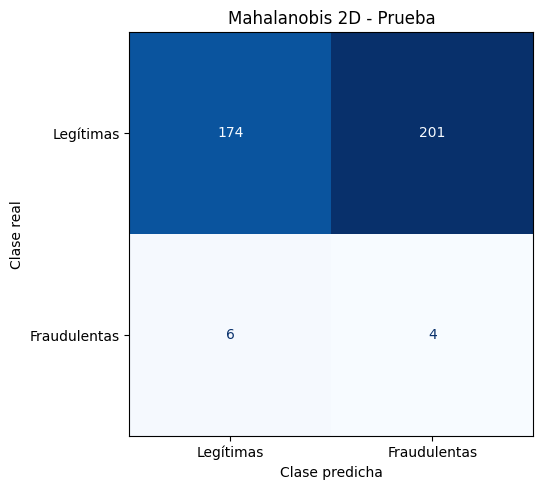

In [75]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test_maha_2d,
    labels=[0, 1],
    display_labels=["Legítimas", "Fraudulentas"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Mahalanobis 2D - Prueba")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

In [76]:
columnas_metricas = [
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "specificity",
    "balanced_accuracy"
]

df_comparacion_maha_2d = pd.DataFrame({
    "Entrenamiento": mejor_maha_2d[columnas_metricas],
    "Prueba": pd.Series(metricas_test_maha_2d)[columnas_metricas]
}).astype(float)

df_comparacion_maha_2d["Diferencia"] = (
    df_comparacion_maha_2d["Prueba"]
    - df_comparacion_maha_2d["Entrenamiento"]
)

display(df_comparacion_maha_2d.round(4))

,Entrenamiento,Prueba,Diferencia
precision,0.0299,0.0195,-0.0104
recall,0.5476,0.4000,-0.1476
f1_score,0.0567,0.0372,-0.0194
fpr,0.5000,0.5360,0.0360
specificity,0.5000,0.4640,-0.0360
balanced_accuracy,0.5238,0.4320,-0.0918


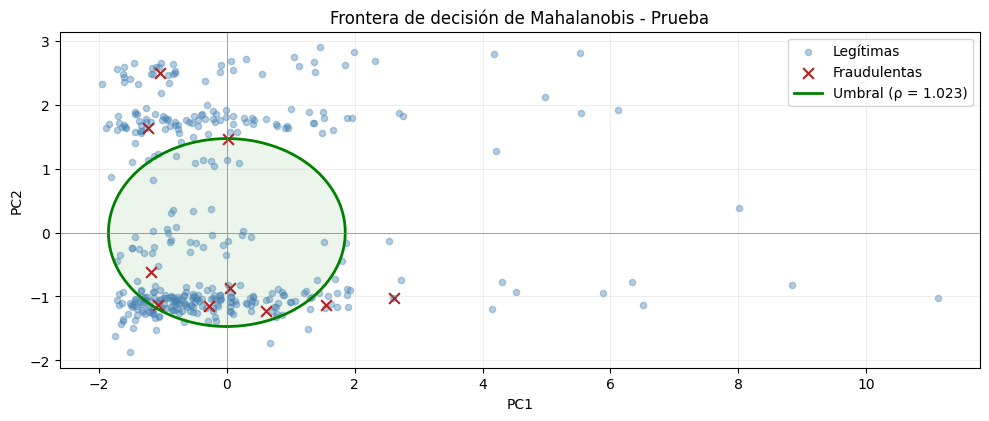

In [77]:
mask_test_legit = np.asarray(y_test) == 0
mask_test_fraud = np.asarray(y_test) == 1

X_test_legit_2d = X_test_2d[mask_test_legit]
X_test_fraud_2d = X_test_2d[mask_test_fraud]

elipse_umbral = generar_elipse_mahalanobis(
    Sigma_2d,
    umbral_maha_2d
)

fig, ax = plt.subplots(figsize=(10, 7))

# Región clasificada como legítima
ax.fill(
    elipse_umbral[:, 0],
    elipse_umbral[:, 1],
    color="green",
    alpha=0.08
)

# Transacciones legítimas
ax.scatter(
    X_test_legit_2d[:, 0],
    X_test_legit_2d[:, 1],
    color="steelblue",
    alpha=0.4,
    s=20,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_test_fraud_2d[:, 0],
    X_test_fraud_2d[:, 1],
    color="firebrick",
    marker="x",
    s=60,
    label="Fraudulentas"
)

# Frontera de decisión
ax.plot(
    elipse_umbral[:, 0],
    elipse_umbral[:, 1],
    color="green",
    linewidth=2,
    label=f"Umbral (ρ = {umbral_maha_2d:.3f})"
)

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)

ax.set_title("Frontera de decisión de Mahalanobis - Prueba")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### 5.9. Generalización de Mahalanobis a 10 dimensiones

In [78]:
k = 10

X_legit_10d = X_train_legit[:, :k]
X_fraud_10d = X_train_fraud[:, :k]
X_test_10d = X_test_pca[:, :k]

varianza_10d = (
    pca.explained_variance_ratio_[:k].sum() * 100
)

print(f"Legítimas: {X_legit_10d.shape}")
print(f"Fraudulentas: {X_fraud_10d.shape}")
print(f"Prueba: {X_test_10d.shape}")
print(f"Varianza explicada: {varianza_10d:.4f}%")

Legítimas: (1494, 10)
Fraudulentas: (42, 10)
Prueba: (385, 10)
Varianza explicada: 66.9230%


In [79]:
# Construir y validar la matriz de covarianza
Sigma_10d = np.cov(
    X_legit_10d,
    rowvar=False,
    ddof=1
)

valores_propios_10d = np.linalg.eigvalsh(Sigma_10d)

print(f"Dimensiones: {Sigma_10d.shape}")

print(
    "Es simétrica:",
    np.allclose(Sigma_10d, Sigma_10d.T)
)

print(f"Rango: {np.linalg.matrix_rank(Sigma_10d)}")

print(
    f"Determinante: "
    f"{np.linalg.det(Sigma_10d):.6f}"
)

print(f"Valores propios:\n{valores_propios_10d}")

print(
    "Es definida positiva:",
    np.all(valores_propios_10d > 0)
)

print(
    f"Número de condición: "
    f"{np.linalg.cond(Sigma_10d):.6f}"
)

assert np.all(valores_propios_10d > 0), (
    "La matriz no es definida positiva."
)

Dimensiones: (10, 10)
Es simétrica: True
Rango: 10
Determinante: 54.864811
Valores propios:
[0.99994256 1.04567206 1.07889519 1.08913481 1.11900365 1.64108818
 1.80560623 1.98621411 2.06655479 3.28097542]
Es definida positiva: True
Número de condición: 3.281164


In [80]:
# Distancias de entrenamiento
distancias_legit_10d = distancia_mahalanobis(
    X_legit_10d,
    Sigma_10d
)

distancias_fraud_10d = distancia_mahalanobis(
    X_fraud_10d,
    Sigma_10d
)

scores_train_maha_10d = distancia_mahalanobis(
    X_train_pca[:, :10],
    Sigma_10d
)

df_distancias_10d = pd.DataFrame({
    "Legítimas": pd.Series(distancias_legit_10d),
    "Fraudulentas": pd.Series(distancias_fraud_10d)
})

display(df_distancias_10d.describe().round(4))

,Legítimas,Fraudulentas
count,1494.0000,42.0000
mean,2.9515,3.0496
std,1.1328,0.9373
min,0.8830,1.4890
25%,2.2721,2.5155
50%,2.7282,2.9220
75%,3.3895,3.6337
max,16.3707,5.3918


In [81]:
# Comparar las distribuciones de densidad
def graficar_densidades(
    scores_legit,
    scores_fraud,
    titulo,
    limite_x=None
):
    kde_legit = gaussian_kde(scores_legit)
    kde_fraud = gaussian_kde(scores_fraud)

    x = np.linspace(
        0,
        max(scores_legit.max(), scores_fraud.max()),
        1000
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    for kde, color, nombre in [
        (kde_legit, "steelblue", "Legítimas"),
        (kde_fraud, "firebrick", "Fraudulentas")
    ]:
        densidad = kde(x)

        ax.plot(
            x, densidad,
            color=color,
            linewidth=2,
            label=nombre
        )

        ax.fill_between(
            x, densidad,
            color=color,
            alpha=0.3
        )

    ax.set_title(titulo)
    ax.set_xlabel("Puntuación de anomalía")
    ax.set_ylabel("Densidad")

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    if limite_x is not None:
        ax.set_xlim(0, limite_x)

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

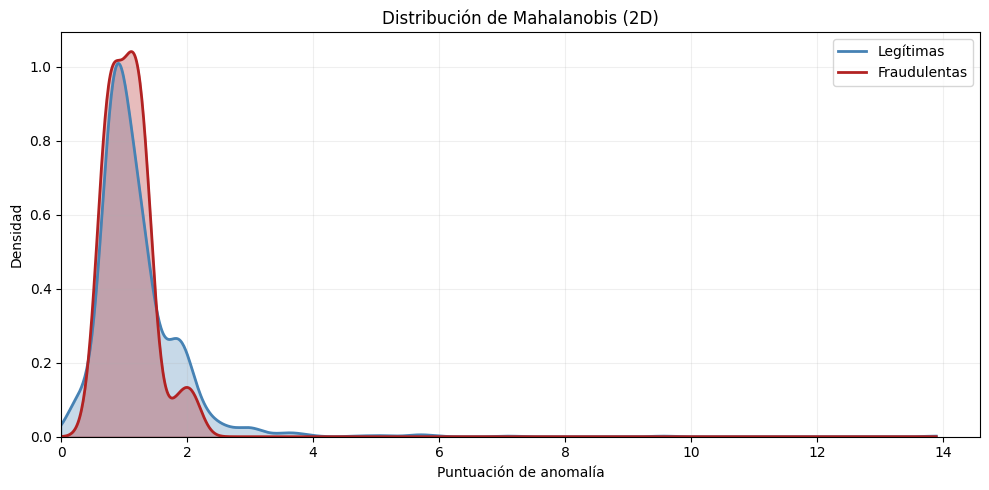

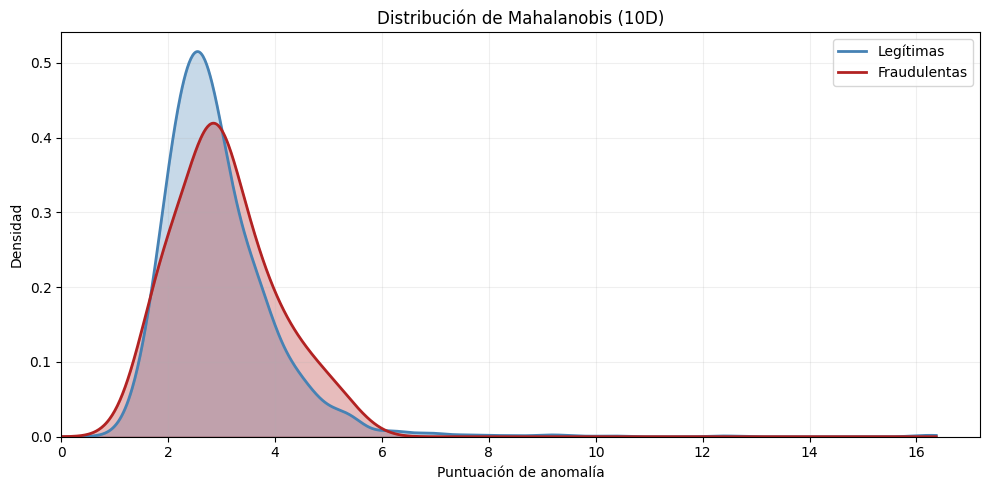

In [82]:
graficar_densidades(
    distancias_legit_2d,
    distancias_fraud_2d,
    "Distribución de Mahalanobis (2D)"
)

graficar_densidades(
    distancias_legit_10d,
    distancias_fraud_10d,
    "Distribución de Mahalanobis (10D)"
)

In [83]:
# Radios empíricos
radios_maha_10d = calcular_radios(
    distancias_legit_10d
)

resultados_cobertura_10d = []

for p, radio in radios_maha_10d.items():

    cobertura = (
        np.mean(distancias_legit_10d <= radio) * 100
    )

    resultados_cobertura_10d.append({
        "percentil": p,
        "radio": radio,
        "cobertura_legit_pct": cobertura,
        "cumple_condicion": p <= cobertura < p + 1,
        "fraudes_dentro": np.sum(
            distancias_fraud_10d <= radio
        ),
        "fraudes_fuera": np.sum(
            distancias_fraud_10d > radio
        )
    })

df_cobertura_maha_10d = pd.DataFrame(
    resultados_cobertura_10d
)

display(df_cobertura_maha_10d.round(4))

,percentil,radio,cobertura_legit_pct,cumple_condicion,fraudes_dentro,fraudes_fuera
0,50,2.7273,50.0000,True,17,25
1,75,3.3913,75.0335,True,29,13
2,90,4.1374,90.0268,True,36,6
3,95,4.7353,95.0469,True,39,3
4,99,6.7600,99.0629,True,42,0


In [84]:
# Calibrar el umbral
resultados_umbral_10d = []

for p, radio in radios_maha_10d.items():

    metricas = evaluar_umbral(
        y_train,
        scores_train_maha_10d,
        radio
    )

    resultados_umbral_10d.append({
        "percentil": p,
        "radio": radio,
        **metricas
    })

df_evaluacion_maha_10d = pd.DataFrame(
    resultados_umbral_10d
)

display(df_evaluacion_maha_10d.round(4))

,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,50,2.7273,746,748,17,25,0.0323,0.5952,0.0613,0.5007,0.4993,0.5473
1,75,3.3913,1121,373,29,13,0.0337,0.3095,0.0607,0.2497,0.7503,0.5299
2,90,4.1374,1345,149,36,6,0.0387,0.1429,0.0609,0.0997,0.9003,0.5216
3,95,4.7353,1420,74,39,3,0.0390,0.0714,0.0504,0.0495,0.9505,0.5109
4,99,6.7600,1480,14,42,0,0.0000,0.0000,0.0000,0.0094,0.9906,0.4953


In [85]:
# Seleccionar el mejor
mejor_maha_10d = seleccionar_umbral(
    df_evaluacion_maha_10d
)

umbral_maha_10d = mejor_maha_10d["radio"]

print(
    f"Percentil seleccionado: "
    f"{mejor_maha_10d['percentil']:.0f}%"
)

print(f"Radio seleccionado: {umbral_maha_10d:.6f}")
print(f"Precision: {mejor_maha_10d['precision']:.4f}")
print(f"Recall: {mejor_maha_10d['recall']:.4f}")
print(f"F1-score: {mejor_maha_10d['f1_score']:.4f}")
print(f"FPR: {mejor_maha_10d['fpr']:.4f}")

Percentil seleccionado: 50%
Radio seleccionado: 2.727340
Precision: 0.0323
Recall: 0.5952
F1-score: 0.0613
FPR: 0.5007


In [86]:
# Evaluación en el conjunto de prueba
inicio = perf_counter()

scores_test_maha_10d = distancia_mahalanobis(
    X_test_10d,
    Sigma_10d
)

y_pred_test_maha_10d = (
    scores_test_maha_10d > umbral_maha_10d
).astype(int)

tiempo_inferencia_maha_10d = perf_counter() - inicio

metricas_test_maha_10d = evaluar_umbral(
    y_test,
    scores_test_maha_10d,
    umbral_maha_10d
)

df_test_maha_10d = pd.DataFrame([{
    "metodo": "Mahalanobis",
    "componentes": 10,
    "varianza_explicada_pct": varianza_10d,
    "percentil": mejor_maha_10d["percentil"],
    "radio": umbral_maha_10d,
    "tiempo_inferencia_s": tiempo_inferencia_maha_10d,
    **metricas_test_maha_10d
}])

display(df_test_maha_10d.round(6))

,metodo,componentes,varianza_explicada_pct,percentil,radio,tiempo_inferencia_s,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,Mahalanobis,10,66.923009,50.0,2.72734,0.000293,196,179,3,7,0.037634,0.7,0.071429,0.477333,0.522667,0.611333


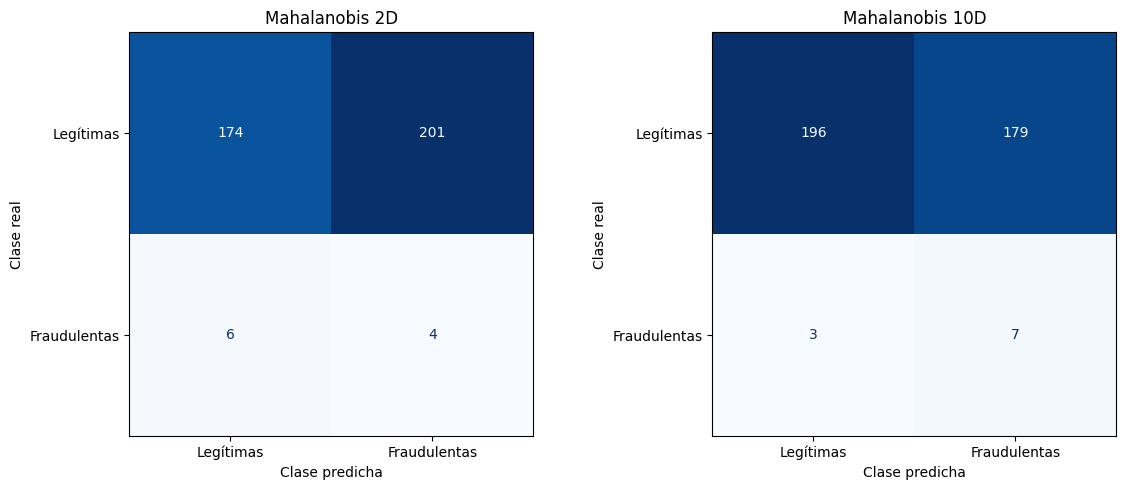

In [87]:
# Comparar matrices de confusión
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

configuraciones = [
    (y_pred_test_maha_2d, "Mahalanobis 2D"),
    (y_pred_test_maha_10d, "Mahalanobis 10D")
]

for ax, (predicciones, titulo) in zip(
    axes, configuraciones
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        labels=[0, 1],
        display_labels=["Legítimas", "Fraudulentas"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

In [88]:
# Tabla comparativa
df_comparativa_maha = pd.concat(
    [
        df_test_maha_2d,
        df_test_maha_10d
    ],
    ignore_index=True
)

columnas_reporte = [
    "componentes",
    "varianza_explicada_pct",
    "percentil",
    "radio",
    "TN",
    "FP",
    "FN",
    "TP",
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "balanced_accuracy",
    "tiempo_inferencia_s"
]

display(
    df_comparativa_maha[columnas_reporte].round(6)
)

,componentes,varianza_explicada_pct,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,balanced_accuracy,tiempo_inferencia_s
0,2,22.020426,50.0,1.022705,174,201,6,4,0.019512,0.4,0.037209,0.536000,0.432000,0.000237
1,10,66.923009,50.0,2.727340,196,179,3,7,0.037634,0.7,0.071429,0.477333,0.611333,0.000293


Los resultados muestran que Mahalanobis mejora su capacidad de detección al incrementar la dimensionalidad de 2 a 10 componentes principales, aunque su desempeño todavía es insuficiente para un sistema de detección de fraude

### Conclusiones de Mahalanobis

El incremento de 2 a 10 componentes principales permitió
aumentar la varianza explicada del 22.02% al 66.92%.

Sobre el conjunto de prueba, el Recall aumentó del 40%
al 70%, mientras que la tasa de falsos positivos disminuyó
del 53.60% al 47.73%.

El F1-score aumentó de 0.0372 a 0.0714 y la Balanced
Accuracy pasó del 43.20% al 61.13%.

Estos resultados sugieren que los componentes principales
adicionales contienen información relevante para la
detección de fraude.

Sin embargo, ambos modelos presentan una baja precisión
y una elevada tasa de falsos positivos.

La naturaleza elipsoidal de las regiones de Mahalanobis
limita su capacidad para representar distribuciones
con estructuras geométricas complejas.

Esto motiva la implementación del kernel de
Christoffel-Darboux como método alternativo de detección
de anomalías.

#### 5.10. Clasificación de regiones de seguridad y peligro
Se clasifican las regiones de Mahalanobis en cuatro
categorías de seguridad mediante el riesgo relativo
de fraude observado en el conjunto de entrenamiento.

La clasificación no depende exclusivamente de la
distancia respecto al origen, sino de la concentración
relativa de transacciones fraudulentas en cada región.

Los niveles de seguridad obtenidos se validan
posteriormente sobre el conjunto de prueba.

In [89]:
# Función de análisis de regiones
def analizar_regiones(scores_legit, scores_fraud, radios):

    regiones_legit = asignar_regiones(
        scores_legit, radios
    )

    regiones_fraud = asignar_regiones(
        scores_fraud, radios
    )

    riesgo_global = (
        len(scores_fraud)
        / (len(scores_legit) + len(scores_fraud))
    )

    resultados = []

    for i, nombre in nombres_regiones.items():

        n_legit = np.sum(regiones_legit == i)
        n_fraud = np.sum(regiones_fraud == i)

        total = n_legit + n_fraud

        riesgo = (
            n_fraud / total
            if total > 0 else np.nan
        )

        resultados.append({
            "region": i,
            "intervalo": nombre,
            "legitimas": n_legit,
            "fraudulentas": n_fraud,
            "total": total,
            "riesgo_pct": riesgo * 100,
            "riesgo_relativo": riesgo / riesgo_global
        })

    return pd.DataFrame(resultados)

In [90]:
# Implementar niveles de seguridad
def clasificar_seguridad(rr):

    if pd.isna(rr):
        return "Sin evidencia"

    elif rr < 0.5:
        return "Seguridad extrema"

    elif rr < 1:
        return "Seguridad alta"

    elif rr < 1.5:
        return "Seguridad baja"

    else:
        return "Peligro"

In [91]:
# Aplicación a ambos modelos de Mahalanobis
df_seguridad_maha_2d = analizar_regiones(
    distancias_legit_2d,
    distancias_fraud_2d,
    radios_maha_2d
)

df_seguridad_maha_10d = analizar_regiones(
    distancias_legit_10d,
    distancias_fraud_10d,
    radios_maha_10d
)

for tabla in [
    df_seguridad_maha_2d,
    df_seguridad_maha_10d
]:
    tabla["nivel_seguridad"] = (
        tabla["riesgo_relativo"]
        .apply(clasificar_seguridad)
    )

print("Mahalanobis 2D")
display(df_seguridad_maha_2d.round(4))

print("Mahalanobis 10D")
display(df_seguridad_maha_10d.round(4))

Mahalanobis 2D


,region,intervalo,legitimas,fraudulentas,total,riesgo_pct,riesgo_relativo,nivel_seguridad
0,1,0% - 50%,747,19,766,2.4804,0.9071,Seguridad alta
1,2,50% - 75%,374,18,392,4.5918,1.6793,Peligro
2,3,75% - 90%,224,3,227,1.3216,0.4833,Seguridad extrema
3,4,90% - 95%,75,2,77,2.5974,0.9499,Seguridad alta
4,5,95% - 99%,60,0,60,0.0000,0.0000,Seguridad extrema
5,6,Exterior 99%,14,0,14,0.0000,0.0000,Seguridad extrema


Mahalanobis 10D


,region,intervalo,legitimas,fraudulentas,total,riesgo_pct,riesgo_relativo,nivel_seguridad
0,1,0% - 50%,747,17,764,2.2251,0.8138,Seguridad alta
1,2,50% - 75%,374,12,386,3.1088,1.1369,Seguridad baja
2,3,75% - 90%,224,7,231,3.0303,1.1082,Seguridad baja
3,4,90% - 95%,75,3,78,3.8462,1.4066,Seguridad baja
4,5,95% - 99%,60,3,63,4.7619,1.7415,Peligro
5,6,Exterior 99%,14,0,14,0.0000,0.0000,Seguridad extrema


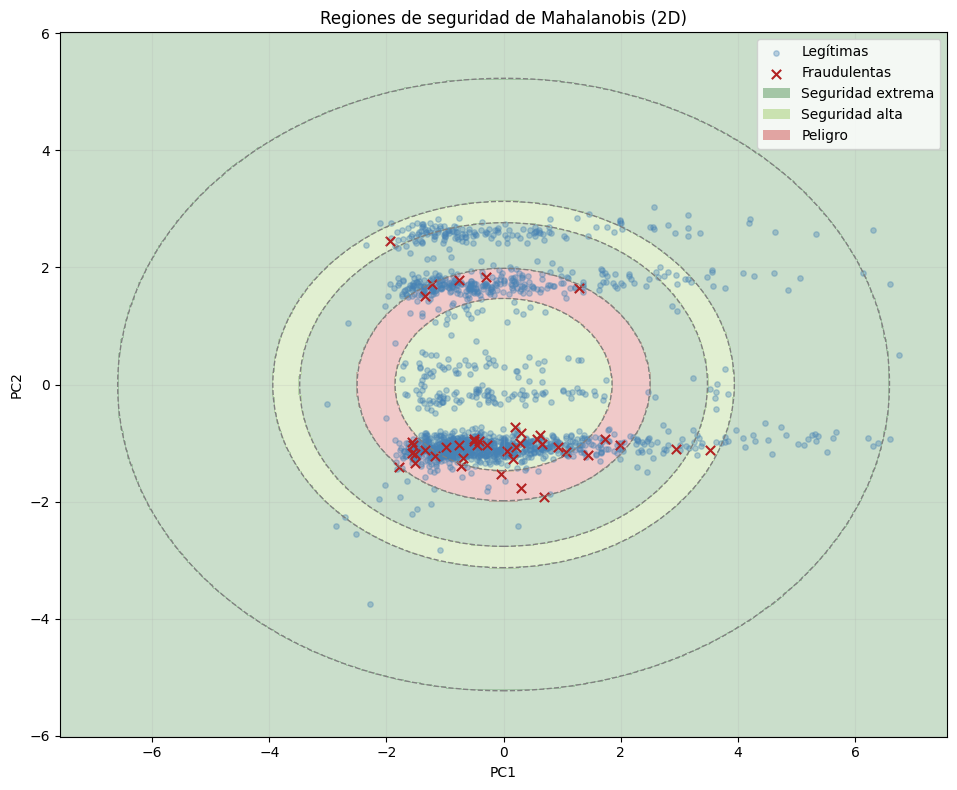

In [94]:
# Visualizar las regiones de seguridad
colores_seguridad = {
    "Seguridad extrema": "#2E7D32",
    "Seguridad alta": "#8BC34A",
    "Seguridad baja": "#FBC02D",
    "Peligro": "#C62828",
    "Sin evidencia": "#808080"
}

elipse_99 = generar_elipse_mahalanobis(
    Sigma_2d,
    radios_maha_2d[99]
)

limite_x = np.abs(elipse_99[:, 0]).max() * 1.15
limite_y = np.abs(elipse_99[:, 1]).max() * 1.15

xx, yy = np.meshgrid(
    np.linspace(-limite_x, limite_x, 400),
    np.linspace(-limite_y, limite_y, 400)
)

puntos_malla = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

scores_malla = distancia_mahalanobis(
    puntos_malla,
    Sigma_2d
)

regiones_malla = asignar_regiones(
    scores_malla,
    radios_maha_2d
).reshape(xx.shape)

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

colores_regiones = [
    colores_seguridad[nivel]
    for nivel in df_seguridad_maha_2d["nivel_seguridad"]
]

cmap_regiones = ListedColormap(colores_regiones)

fig, ax = plt.subplots(figsize=(12, 8))

# Colorear las seis regiones
ax.contourf(
    xx,
    yy,
    regiones_malla,
    levels=np.arange(0.5, 7, 1),
    cmap=cmap_regiones,
    alpha=0.25
)

# Transacciones legítimas
ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.35,
    s=15,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    marker="x",
    s=45,
    label="Fraudulentas"
)

# Fronteras de las regiones
for p, radio in radios_maha_2d.items():

    elipse = generar_elipse_mahalanobis(
        Sigma_2d, radio
    )

    ax.plot(
        elipse[:, 0],
        elipse[:, 1],
        color="gray",
        linewidth=1,
        linestyle="--"
    )

# Leyenda
handles, labels = ax.get_legend_handles_labels()

for nivel, color in colores_seguridad.items():

    if nivel in df_seguridad_maha_2d["nivel_seguridad"].values:

        handles.append(
            Patch(
                facecolor=color,
                alpha=0.4,
                label=nivel
            )
        )

ax.legend(handles=handles, loc="upper right")

ax.set_title("Regiones de seguridad de Mahalanobis (2D)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")

ax.set_xlim(-limite_x, limite_x)
ax.set_ylim(-limite_y, limite_y)

ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [95]:
def validar_seguridad(y_real, scores, radios, tabla_seguridad):

    regiones = asignar_regiones(scores, radios)

    mapa_seguridad = (
        tabla_seguridad
        .set_index("region")["nivel_seguridad"]
        .to_dict()
    )

    df_validacion = pd.DataFrame({
        "is_fraud": np.asarray(y_real),
        "region": regiones
    })

    df_validacion["nivel_seguridad"] = (
        df_validacion["region"].map(mapa_seguridad)
    )

    resumen = (
        df_validacion
        .groupby("nivel_seguridad")
        .agg(
            total=("is_fraud", "size"),
            fraudulentas=("is_fraud", "sum")
        )
    )

    resumen["legitimas"] = (
        resumen["total"] - resumen["fraudulentas"]
    )

    resumen["riesgo_pct"] = (
        resumen["fraudulentas"]
        / resumen["total"] * 100
    )

    orden = [
        "Seguridad extrema",
        "Seguridad alta",
        "Seguridad baja",
        "Peligro"
    ]

    return resumen.reindex(orden)

In [96]:
df_validacion_seguridad_2d = validar_seguridad(
    y_test,
    scores_test_maha_2d,
    radios_maha_2d,
    df_seguridad_maha_2d
)

df_validacion_seguridad_10d = validar_seguridad(
    y_test,
    scores_test_maha_10d,
    radios_maha_10d,
    df_seguridad_maha_10d
)

print("Mahalanobis 2D - Prueba")
display(df_validacion_seguridad_2d.round(4))

print("Mahalanobis 10D - Prueba")
display(df_validacion_seguridad_10d.round(4))

Mahalanobis 2D - Prueba


,total,fraudulentas,legitimas,riesgo_pct
nivel_seguridad,,,,
Seguridad extrema,78.0,2.0,76.0,2.5641
Seguridad alta,192.0,6.0,186.0,3.1250
Seguridad baja,NaN,NaN,NaN,NaN
Peligro,115.0,2.0,113.0,1.7391


Mahalanobis 10D - Prueba


,total,fraudulentas,legitimas,riesgo_pct
nivel_seguridad,,,,
Seguridad extrema,1,0,1,0.0000
Seguridad alta,199,3,196,1.5075
Seguridad baja,170,6,164,3.5294
Peligro,15,1,14,6.6667


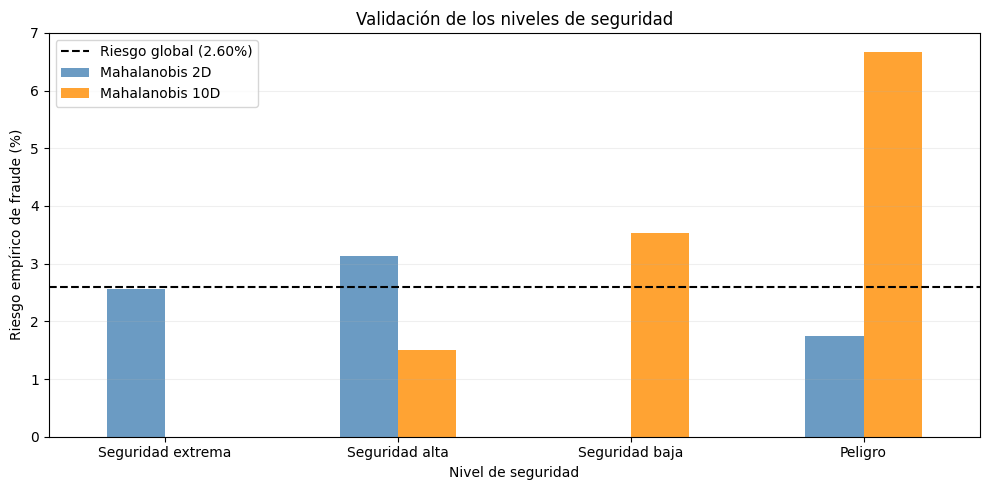

In [97]:
fig, ax = plt.subplots(figsize=(10, 5))

df_comparacion_seguridad = pd.DataFrame({
    "Mahalanobis 2D": (
        df_validacion_seguridad_2d["riesgo_pct"]
    ),
    "Mahalanobis 10D": (
        df_validacion_seguridad_10d["riesgo_pct"]
    )
})

df_comparacion_seguridad.plot(
    kind="bar",
    ax=ax,
    color=["steelblue", "darkorange"],
    alpha=0.8,
    rot=0
)

riesgo_global_test = np.mean(y_test) * 100

ax.axhline(
    riesgo_global_test,
    color="black",
    linestyle="--",
    label=f"Riesgo global ({riesgo_global_test:.2f}%)"
)

ax.set_title("Validación de los niveles de seguridad")
ax.set_xlabel("Nivel de seguridad")
ax.set_ylabel("Riesgo empírico de fraude (%)")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

---

### 6. Detección de fraude mediante el kernel de Christoffel-Darboux
#### 6.1. Construcción de monomios de grado 2
Se construye una transformación polinomial que incorpora
todos los monomios de grado total menor o igual a dos.

Cada observación del espacio PCA bidimensional se
transforma en un vector de seis características.

Esta representación permite incorporar términos
cuadráticos e interacciones entre componentes principales
para construir regiones de detección no necesariamente
elipsoidales.

In [98]:
def phi_grado_2(X):

    x1 = X[:, 0]
    x2 = X[:, 1]

    return np.column_stack([
        np.ones(X.shape[0]),
        x1,
        x2,
        x1**2,
        x1 * x2,
        x2**2
    ])

x_ejemplo = np.array([[2, 3]])

phi_ejemplo = phi_grado_2(x_ejemplo)

print("Observación original:")
print(x_ejemplo)

print("\nTransformación polinomial:")
print(phi_ejemplo)

print(f"\nDimensiones originales: {x_ejemplo.shape}")
print(f"Dimensiones transformadas: {phi_ejemplo.shape}")

Observación original:
[[2 3]]

Transformación polinomial:
[[1. 2. 3. 4. 6. 9.]]

Dimensiones originales: (1, 2)
Dimensiones transformadas: (1, 6)


In [99]:
# Implementación mediante scikit learn
from sklearn.preprocessing import PolynomialFeatures

poly_2d = PolynomialFeatures(
    degree=2,
    include_bias=True,
    interaction_only=False
)

phi_sklearn = poly_2d.fit_transform(x_ejemplo)

print("Transformación mediante Scikit-learn:")
print(phi_sklearn)

print("\nMonomios generados:")
print(
    poly_2d.get_feature_names_out(["x1", "x2"])
)

print(
    "\nCoincidencia con implementación manual:",
    np.allclose(phi_ejemplo, phi_sklearn)
)

Transformación mediante Scikit-learn:
[[1. 2. 3. 4. 6. 9.]]

Monomios generados:
['1' 'x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']

Coincidencia con implementación manual: True


In [ ]:
# Transformación de las legítimas de entrenamiento
D_legit_2d = poly_2d.fit_transform(
    X_legit_2d
)

# Transformación de las fraudulentas de entrenamiento
D_fraud_2d = poly_2d.transform(
    X_fraud_2d
)

# Transformación del conjunto de prueba
D_test_2d = poly_2d.transform(
    X_test_2d
)

print(f"Legítimas: {D_legit_2d.shape}")
print(f"Fraudulentas: {D_fraud_2d.shape}")
print(f"Prueba: {D_test_2d.shape}")

Legítimas: (1494, 6)
Fraudulentas: (42, 6)
Prueba: (385, 6)


In [ ]:
# Inspeccionar la matriz de diseño
nombres_monomios = poly_2d.get_feature_names_out(
    ["PC1", "PC2"]
)

df_monomios_2d = pd.DataFrame(
    D_legit_2d,
    columns=nombres_monomios
)

display(df_monomios_2d.head(10).round(4))

,1,PC1,PC2,PC1^2,PC1 PC2,PC2^2
0,1.0,-0.7048,-0.9098,0.4968,0.6413,0.8278
1,1.0,-1.0213,1.7109,1.0430,-1.7472,2.9271
2,1.0,1.6640,-1.1609,2.7689,-1.9318,1.3477
3,1.0,0.0962,-1.2079,0.0092,-0.1162,1.4590
4,1.0,0.2753,-1.1915,0.0758,-0.3280,1.4196
5,1.0,-0.8970,1.7487,0.8046,-1.5686,3.0580
6,1.0,-1.2322,-1.2297,1.5184,1.5153,1.5123
7,1.0,2.5733,3.0273,6.6217,7.7900,9.1644
8,1.0,1.3239,-1.1516,1.7527,-1.5246,1.3263
9,1.0,-0.2812,-1.1579,0.0791,0.3256,1.3408


In [102]:
# Generalización del número de monómios
from math import comb

def numero_monomios(k, grado):
    return comb(k + grado, grado)


resultados_monomios = []

for k in [2, 5, 7, 10]:

    for grado in [2, 4]:

        m = numero_monomios(k, grado)

        resultados_monomios.append({
            "componentes": k,
            "grado": grado,
            "monomios": m,
            "dimensiones_D": f"1494 x {m}",
            "dimensiones_M": f"{m} x {m}"
        })

df_dimensiones_cd = pd.DataFrame(
    resultados_monomios
)

display(df_dimensiones_cd)

,componentes,grado,monomios,dimensiones_D,dimensiones_M
0,2,2,6,1494 x 6,6 x 6
1,2,4,15,1494 x 15,15 x 15
2,5,2,21,1494 x 21,21 x 21
3,5,4,126,1494 x 126,126 x 126
4,7,2,36,1494 x 36,36 x 36
5,7,4,330,1494 x 330,330 x 330
6,10,2,66,1494 x 66,66 x 66
7,10,4,1001,1494 x 1001,1001 x 1001


#### 6.2. Construcción de la matriz de momentos

In [103]:
N, m = D_legit_2d.shape

# Matriz de momentos empírica
M_2d = (D_legit_2d.T @ D_legit_2d) / N

print(f"Número de observaciones: {N}")
print(f"Número de monomios: {m}")
print(f"Dimensiones de D: {D_legit_2d.shape}")
print(f"Dimensiones de M: {M_2d.shape}")

df_momentos_2d = pd.DataFrame(
    M_2d,
    index=nombres_monomios,
    columns=nombres_monomios
)

display(df_momentos_2d.round(4))

Número de observaciones: 1494
Número de monomios: 6
Dimensiones de D: (1494, 6)
Dimensiones de M: (6, 6)


,1,PC1,PC2,PC1^2,PC1 PC2,PC2^2
1,1.0000,0.0027,0.0200,3.2786,0.0054,2.0652
PC1,0.0027,3.2786,0.0054,24.4014,-0.1520,-0.1375
PC2,0.0200,0.0054,2.0652,-0.1520,-0.1375,2.0568
PC1^2,3.2786,24.4014,-0.1520,413.8979,-9.7454,5.9730
PC1 PC2,0.0054,-0.1520,-0.1375,-9.7454,5.9730,0.3086
PC2^2,2.0652,-0.1375,2.0568,5.9730,0.3086,7.9128


In [104]:
# Validación de momentos empíricos
x1 = X_legit_2d[:, 0]
x2 = X_legit_2d[:, 1]

validaciones_momentos = [
    ("1", M_2d[0, 0], 1),
    ("E[x1]", M_2d[0, 1], np.mean(x1)),
    ("E[x2]", M_2d[0, 2], np.mean(x2)),
    ("E[x1²]", M_2d[1, 1], np.mean(x1**2)),
    ("E[x1*x2]", M_2d[1, 2], np.mean(x1*x2)),
    ("E[x2²]", M_2d[2, 2], np.mean(x2**2)),
    ("E[x1⁴]", M_2d[3, 3], np.mean(x1**4)),
    ("E[x1²*x2²]", M_2d[3, 5], np.mean(x1**2*x2**2)),
    ("E[x2⁴]", M_2d[5, 5], np.mean(x2**4))
]

df_validacion_momentos = pd.DataFrame(
    validaciones_momentos,
    columns=[
        "momento",
        "valor_matriz",
        "valor_empirico"
    ]
)

df_validacion_momentos["coincidencia"] = np.isclose(
    df_validacion_momentos["valor_matriz"],
    df_validacion_momentos["valor_empirico"]
)

display(df_validacion_momentos.round(6))

,momento,valor_matriz,valor_empirico,coincidencia
0,1,1.000000,1.000000,True
1,E[x1],0.002703,0.002703,True
2,E[x2],0.019976,0.019976,True
3,E[x1²],3.278585,3.278585,True
4,E[x1*x2],0.005414,0.005414,True
5,E[x2²],2.065240,2.065240,True
6,E[x1⁴],413.897889,413.897889,True
7,E[x1²*x2²],5.973000,5.973000,True
8,E[x2⁴],7.912789,7.912789,True


In [105]:
# Validaciones algebráicas
valores_propios_M_2d = np.linalg.eigvalsh(M_2d)

rango_D = np.linalg.matrix_rank(D_legit_2d)
rango_M = np.linalg.matrix_rank(M_2d)

determinante_M = np.linalg.det(M_2d)
condicion_M = np.linalg.cond(M_2d)

print("Propiedades de la matriz de momentos\n")

print(
    "Es simétrica:",
    np.allclose(M_2d, M_2d.T)
)

print(f"Rango de D: {rango_D}")
print(f"Rango de M: {rango_M}")
print(f"Coincidencia de rangos: {rango_D == rango_M}")

print(f"\nDeterminante: {determinante_M:.6e}")

print("\nValores propios:")
print(valores_propios_M_2d)

print(
    "\nEs semidefinida positiva:",
    np.all(valores_propios_M_2d >= -1e-10)
)

print(
    "Es definida positiva (criterio numérico):",
    np.all(valores_propios_M_2d > 1e-10)
)

print(f"\nNúmero de condición: {condicion_M:.6f}")

Propiedades de la matriz de momentos

Es simétrica: True
Rango de D: 6
Rango de M: 6
Coincidencia de rangos: True

Determinante: 1.380251e+04

Valores propios:
[2.20588289e-01 1.51252462e+00 1.91169127e+00 5.76448383e+00
 9.03084279e+00 4.15687372e+02]

Es semidefinida positiva: True
Es definida positiva (criterio numérico): True

Número de condición: 1884.448965


In [106]:
# Validación mediante SVD
U_D, S_D, Vt_D = np.linalg.svd(
    D_legit_2d,
    full_matrices=False
)

# Valores propios obtenidos mediante SVD
lambda_svd = S_D**2 / N

# Reconstrucción de la matriz de momentos
M_svd = (
    Vt_D.T
    @ np.diag(lambda_svd)
    @ Vt_D
)

df_espectro_M = pd.DataFrame({
    "valor_singular_D": S_D,
    "valor_propio_SVD": lambda_svd,
    "valor_propio_M": valores_propios_M_2d[::-1]
})

display(df_espectro_M.round(6))

print(
    "Coincidencia de valores propios:",
    np.allclose(
        lambda_svd,
        valores_propios_M_2d[::-1]
    )
)

print(
    "Coincidencia de matrices:",
    np.allclose(M_2d, M_svd)
)

,valor_singular_D,valor_propio_SVD,valor_propio_M
0,788.058966,415.687372,415.687372
1,116.155409,9.030843,9.030843
2,92.801610,5.764484,5.764484
3,53.442181,1.911691,1.911691
4,47.536426,1.512525,1.512525
5,18.153757,0.220588,0.220588


Coincidencia de valores propios: True
Coincidencia de matrices: True


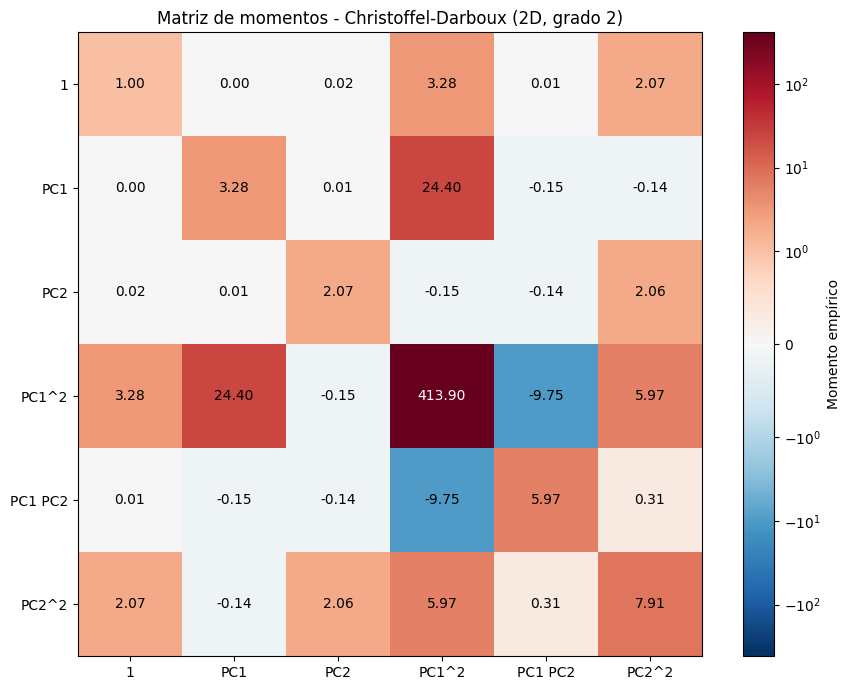

In [107]:
# Visualización de la matriz de momentos
from matplotlib.colors import SymLogNorm

fig, ax = plt.subplots(figsize=(9, 7))

limite = np.abs(M_2d).max()

im = ax.imshow(
    M_2d,
    cmap="RdBu_r",
    norm=SymLogNorm(
        linthresh=1,
        vmin=-limite,
        vmax=limite
    )
)

ax.set_xticks(np.arange(m))
ax.set_yticks(np.arange(m))

ax.set_xticklabels(nombres_monomios)
ax.set_yticklabels(nombres_monomios)

for i in range(m):
    for j in range(m):

        valor = M_2d[i, j]

        color_texto = (
            "white"
            if abs(im.norm(valor) - 0.5) > 0.35
            else "black"
        )

        ax.text(
            j, i,
            f"{valor:.2f}",
            ha="center",
            va="center",
            color=color_texto
        )

fig.colorbar(
    im,
    ax=ax,
    label="Momento empírico"
)

ax.set_title("Matriz de momentos - Christoffel-Darboux (2D, grado 2)")

plt.tight_layout()
plt.show()

#### 6.3. Regularización de Tikhonov
Se aplica una regularización de Tikhonov sobre la
matriz de momentos empírica para garantizar su
invertibilidad y mejorar su estabilidad numérica.

$$
M_{\text{reg}} = M_N + \varepsilon I_m
$$

Se utiliza un parámetro de regularización de
$\varepsilon = 10^{-6}$.

Se analiza el efecto de la regularización sobre
los valores propios, el rango, el determinante
y el número de condición de la matriz.

In [108]:
EPSILON = 1e-6

# Número de monomios
m = M_2d.shape[0]

# Matriz identidad
I_m = np.eye(m)

# Regularización de Tikhonov
M_reg_2d = M_2d + EPSILON * I_m

df_momentos_reg_2d = pd.DataFrame(
    M_reg_2d,
    index=nombres_monomios,
    columns=nombres_monomios
)

print(f"Epsilon: {EPSILON}")
print(f"Dimensiones de I: {I_m.shape}")
print(f"Dimensiones de M_reg: {M_reg_2d.shape}")

display(df_momentos_reg_2d.round(8))

Epsilon: 1e-06
Dimensiones de I: (6, 6)
Dimensiones de M_reg: (6, 6)


,1,PC1,PC2,PC1^2,PC1 PC2,PC2^2
1,1.000001,0.002703,0.019976,3.278585,0.005414,2.065240
PC1,0.002703,3.278586,0.005414,24.401367,-0.152016,-0.137469
PC2,0.019976,0.005414,2.065241,-0.152016,-0.137469,2.056760
PC1^2,3.278585,24.401367,-0.152016,413.897890,-9.745410,5.973000
PC1 PC2,0.005414,-0.152016,-0.137469,-9.745410,5.973001,0.308581
PC2^2,2.065240,-0.137469,2.056760,5.973000,0.308581,7.912790


In [109]:
# Valores propios originales
lambda_original = np.linalg.eigvalsh(M_2d)

# Valores propios regularizados
lambda_reg = np.linalg.eigvalsh(M_reg_2d)

# Valores propios esperados teóricamente
lambda_esperado = lambda_original + EPSILON

df_espectro_reg = pd.DataFrame({
    "valor_propio_original": lambda_original,
    "valor_propio_regularizado": lambda_reg,
    "valor_propio_esperado": lambda_esperado,
    "diferencia": lambda_reg - lambda_original
})

display(df_espectro_reg.round(10))

print(
    "Coincidencia con la expresión teórica:",
    np.allclose(
        lambda_reg,
        lambda_esperado,
        rtol=0,
        atol=1e-10
    )
)

print(
    "Desplazamiento igual a epsilon:",
    np.allclose(
        lambda_reg - lambda_original,
        EPSILON,
        rtol=0,
        atol=1e-10
    )
)

print(
    "Todos los valores propios son positivos:",
    np.all(lambda_reg > 0)
)

,valor_propio_original,valor_propio_regularizado,valor_propio_esperado,diferencia
0,0.220588,0.220589,0.220589,0.000001
1,1.512525,1.512526,1.512526,0.000001
2,1.911691,1.911692,1.911692,0.000001
3,5.764484,5.764485,5.764485,0.000001
4,9.030843,9.030844,9.030844,0.000001
5,415.687372,415.687373,415.687373,0.000001


Coincidencia con la expresión teórica: True
Desplazamiento igual a epsilon: True
Todos los valores propios son positivos: True


In [110]:
def diagnosticar_matriz(M):

    eigenvalues = np.linalg.eigvalsh(M)

    return {
        "dimension": M.shape[0],
        "rango": np.linalg.matrix_rank(M),
        "determinante": np.linalg.det(M),
        "valor_propio_min": eigenvalues.min(),
        "valor_propio_max": eigenvalues.max(),
        "numero_condicion": np.linalg.cond(M),
        "simetrica": np.allclose(M, M.T),
        "definida_positiva": np.all(eigenvalues > 0)
    }


df_diagnostico_reg = pd.DataFrame({
    "Matriz original": diagnosticar_matriz(M_2d),
    "Matriz regularizada": diagnosticar_matriz(M_reg_2d)
})

display(df_diagnostico_reg)

,Matriz original,Matriz regularizada
dimension,6,6
rango,6,6
determinante,13802.514077,13802.59695
valor_propio_min,0.220588,0.220589
valor_propio_max,415.687372,415.687373
numero_condicion,1884.448965,1884.440426
simetrica,True,True
definida_positiva,True,True


In [111]:
cond_original = np.linalg.cond(M_2d)
cond_reg = np.linalg.cond(M_reg_2d)

print(f"Condición original: {cond_original:.8f}")
print(f"Condición regularizada: {cond_reg:.8f}")

if np.isfinite(cond_original):

    reduccion_condicion = (
        1 - cond_reg / cond_original
    ) * 100

    print(
        f"Reducción del número de condición: "
        f"{reduccion_condicion:.8f}%"
    )

else:
    print("La matriz original presenta condición infinita.")

Condición original: 1884.44896455
Condición regularizada: 1884.44042629
Reducción del número de condición: 0.00045309%


In [112]:
# Factorización de Cholesky
L_2d = np.linalg.cholesky(M_reg_2d)

# Reconstrucción de la matriz regularizada
M_reconstruida = L_2d @ L_2d.T

print("Factorización de Cholesky:\n")
print(L_2d.round(6))

print(
    "\nEs triangular inferior:",
    np.allclose(L_2d, np.tril(L_2d))
)

print(
    "Diagonal estrictamente positiva:",
    np.all(np.diag(L_2d) > 0)
)

print(
    "Reconstrucción correcta:",
    np.allclose(M_reg_2d, M_reconstruida)
)

print(
    "Error de reconstrucción:",
    f"{np.linalg.norm(M_reg_2d - M_reconstruida):.6e}"
)

Factorización de Cholesky:

[[ 1.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   0.0000000e+00  0.0000000e+00]
 [ 2.7030000e-03  1.8106850e+00  0.0000000e+00  0.0000000e+00
   0.0000000e+00  0.0000000e+00]
 [ 1.9976000e-02  2.9600000e-03  1.4369530e+00  0.0000000e+00
   0.0000000e+00  0.0000000e+00]
 [ 3.2785830e+00  1.3471428e+01 -1.7912000e-01  1.4887489e+01
   0.0000000e+00  0.0000000e+00]
 [ 5.4140000e-03 -8.3963000e-02 -9.5569000e-02 -5.8096900e-01
   2.3704980e+00  0.0000000e+00]
 [ 2.0652390e+00 -7.9004000e-02  1.4027880e+00  3.4761000e-02
   1.8773400e-01  1.2794810e+00]]

Es triangular inferior: True
Diagonal estrictamente positiva: True
Reconstrucción correcta: True
Error de reconstrucción: 1.021315e-15


#### 6.4. Implementación del kernel de Christoffel-Darboux
Se calcula la puntuación de anomalía de cada
observación mediante la expresión:

$$
p_{CD}(x)=\Phi(x)^TM_{\text{reg}}^{-1}\Phi(x)
$$

Se utiliza la factorización de Cholesky para evitar
el cálculo explícito de la matriz inversa.

Posteriormente, se analiza la distribución de las
puntuaciones de anomalía de las transacciones
legítimas y fraudulentas de entrenamiento.

In [114]:
# Validación con una observación
from scipy.linalg import solve_triangular

# Primera observación en el espacio de monomios
phi_x = D_legit_2d[0]

# Método 1: inversa explícita
M_inv_2d = np.linalg.inv(M_reg_2d)

score_inversa = phi_x.T @ M_inv_2d @ phi_x

# Método 2: factorización de Cholesky
z = solve_triangular(
    L_2d,
    phi_x,
    lower=True
)

score_cholesky = z.T @ z

print(f"Vector de monomios: {phi_x.round(4)}")

print(f"\nScore mediante inversa: {score_inversa:.10f}")
print(f"Score mediante Cholesky: {score_cholesky:.10f}")

print(
    "\nCoincidencia:",
    np.isclose(score_inversa, score_cholesky)
)

print(
    "Diferencia absoluta:",
    f"{abs(score_inversa - score_cholesky):.6e}"
)

Vector de monomios: [ 1.     -0.7048 -0.9098  0.4968  0.6413  0.8278]

Score mediante inversa: 1.7735228131
Score mediante Cholesky: 1.7735228131

Coincidencia: True
Diferencia absoluta: 8.881784e-16


In [115]:
# Función general de puntuación
def calcular_score_cd(X, poly, L):
    """
    Calcula las puntuaciones de anomalía mediante
    el kernel de Christoffel-Darboux regularizado.

    Parameters
    ----------
    X : np.ndarray
        Observaciones en el espacio PCA.

    poly : PolynomialFeatures
        Transformación polinomial previamente ajustada.

    L : np.ndarray
        Factor triangular inferior de Cholesky
        de la matriz de momentos regularizada.

    Returns
    -------
    np.ndarray
        Puntuación de anomalía de cada observación.
    """

    # Transformación al espacio de monomios
    D_X = poly.transform(X)

    # Resolver LZ = D_X.T
    Z = solve_triangular(
        L,
        D_X.T,
        lower=True
    )

    # Norma euclidiana al cuadrado por observación
    scores = np.sum(Z**2, axis=0)

    return scores

In [116]:
# Puntuaciones de anomalía
from time import perf_counter

inicio = perf_counter()

scores_cd_legit_2d = calcular_score_cd(
    X_legit_2d,
    poly_2d,
    L_2d
)

scores_cd_fraud_2d = calcular_score_cd(
    X_fraud_2d,
    poly_2d,
    L_2d
)

tiempo_cd_train_2d = perf_counter() - inicio

print("Christoffel-Darboux (2D, grado 2)\n")

print(
    "Dimensiones legítimas:",
    scores_cd_legit_2d.shape
)

print(
    "Dimensiones fraudulentas:",
    scores_cd_fraud_2d.shape
)

print(
    f"\nTiempo de cálculo: "
    f"{tiempo_cd_train_2d:.6f} segundos"
)

Christoffel-Darboux (2D, grado 2)

Dimensiones legítimas: (1494,)
Dimensiones fraudulentas: (42,)

Tiempo de cálculo: 0.000841 segundos


In [117]:
# Validaciones de las puntuaciones
media_empirica = scores_cd_legit_2d.mean()

media_teorica = np.sum(
    lambda_original / (lambda_original + EPSILON)
)

print("Validaciones del kernel Christoffel-Darboux\n")

print(
    "Scores legítimos finitos:",
    np.all(np.isfinite(scores_cd_legit_2d))
)

print(
    "Scores fraudulentos finitos:",
    np.all(np.isfinite(scores_cd_fraud_2d))
)

print(
    "Scores legítimos positivos:",
    np.all(scores_cd_legit_2d > 0)
)

print(
    "Scores fraudulentos positivos:",
    np.all(scores_cd_fraud_2d > 0)
)

print(f"\nNúmero de monomios: {m}")
print(f"Media empírica: {media_empirica:.10f}")
print(f"Media teórica: {media_teorica:.10f}")

print(
    "Coincidencia de medias:",
    np.isclose(media_empirica, media_teorica)
)

print(
    "Diferencia absoluta:",
    f"{abs(media_empirica - media_teorica):.6e}"
)

Validaciones del kernel Christoffel-Darboux

Scores legítimos finitos: True
Scores fraudulentos finitos: True
Scores legítimos positivos: True
Scores fraudulentos positivos: True

Número de monomios: 6
Media empírica: 5.9999939958
Media teórica: 5.9999939958
Coincidencia de medias: True
Diferencia absoluta: 8.881784e-16


In [118]:
df_descriptivo_cd_2d = pd.DataFrame({
    "Legítimas": pd.Series(scores_cd_legit_2d).describe(),
    "Fraudulentas": pd.Series(scores_cd_fraud_2d).describe()
})

display(df_descriptivo_cd_2d.round(4))

,Legítimas,Fraudulentas
count,1494.0000,42.0000
mean,6.0000,3.7449
std,29.6916,2.6550
min,1.5136,1.5690
25%,2.2163,1.8873
50%,3.1756,3.0438
75%,4.8485,4.2981
max,1075.3500,12.3690


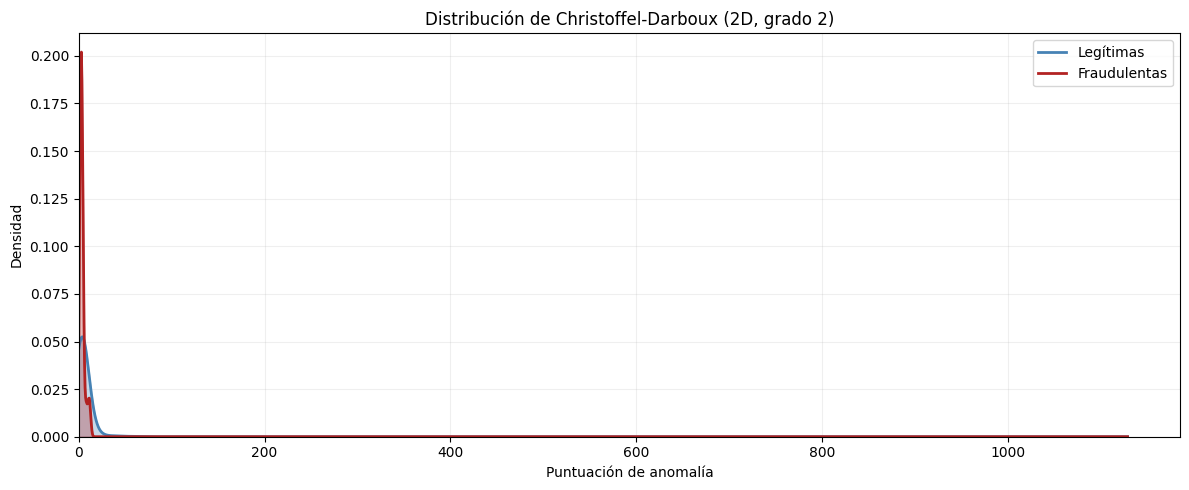

In [119]:
# Visualización de las distribuciones
from scipy.stats import gaussian_kde

kde_legit_cd = gaussian_kde(scores_cd_legit_2d)
kde_fraud_cd = gaussian_kde(scores_cd_fraud_2d)

limite_superior = max(
    scores_cd_legit_2d.max(),
    scores_cd_fraud_2d.max()
)

eje_x = np.linspace(
    0,
    limite_superior * 1.05,
    2000
)

densidad_legit = kde_legit_cd(eje_x)
densidad_fraud = kde_fraud_cd(eje_x)

fig, ax = plt.subplots(figsize=(12, 5))

# Transacciones legítimas
ax.plot(
    eje_x,
    densidad_legit,
    color="steelblue",
    linewidth=2,
    label="Legítimas"
)

ax.fill_between(
    eje_x,
    densidad_legit,
    color="steelblue",
    alpha=0.30
)

# Transacciones fraudulentas
ax.plot(
    eje_x,
    densidad_fraud,
    color="firebrick",
    linewidth=2,
    label="Fraudulentas"
)

ax.fill_between(
    eje_x,
    densidad_fraud,
    color="firebrick",
    alpha=0.30
)

ax.set_title(
    "Distribución de Christoffel-Darboux (2D, grado 2)"
)

ax.set_xlabel("Puntuación de anomalía")
ax.set_ylabel("Densidad")

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

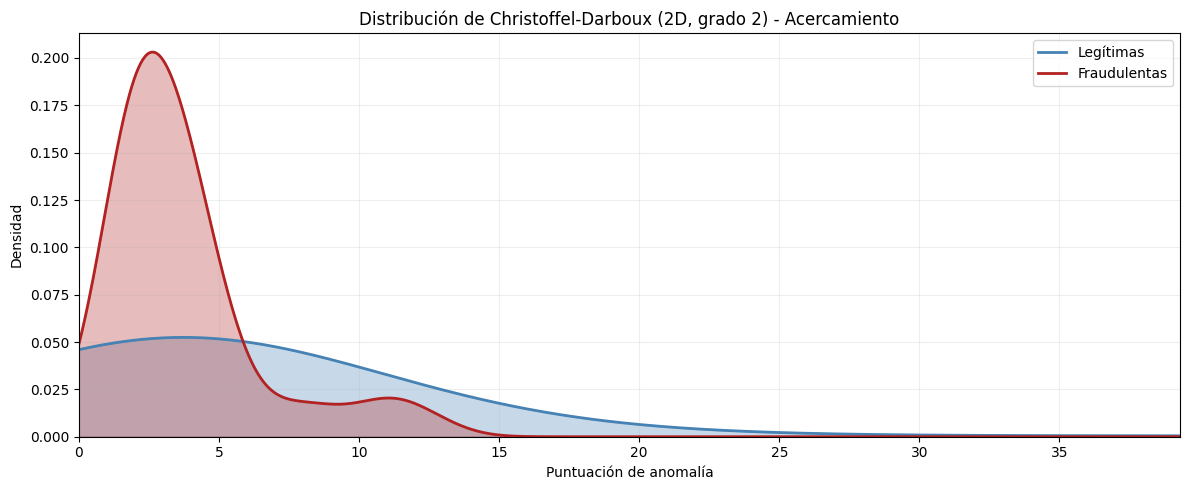

Límite de visualización: 39.3019
Legítimas fuera de la visualización: 15
Fraudulentas fuera de la visualización: 0


In [120]:
# Visualización con p99
limite_zoom = np.percentile(
    scores_cd_legit_2d,
    99
)

eje_x_zoom = np.linspace(
    0,
    limite_zoom,
    1000
)

fig, ax = plt.subplots(figsize=(12, 5))

for kde, color, etiqueta in [
    (kde_legit_cd, "steelblue", "Legítimas"),
    (kde_fraud_cd, "firebrick", "Fraudulentas")
]:

    densidad = kde(eje_x_zoom)

    ax.plot(
        eje_x_zoom,
        densidad,
        color=color,
        linewidth=2,
        label=etiqueta
    )

    ax.fill_between(
        eje_x_zoom,
        densidad,
        color=color,
        alpha=0.30
    )

ax.set_title(
    "Distribución de Christoffel-Darboux "
    "(2D, grado 2) - Acercamiento"
)

ax.set_xlabel("Puntuación de anomalía")
ax.set_ylabel("Densidad")

ax.set_xlim(0, limite_zoom)
ax.set_ylim(bottom=0)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Límite de visualización: {limite_zoom:.4f}")

print(
    "Legítimas fuera de la visualización:",
    np.sum(scores_cd_legit_2d > limite_zoom)
)

print(
    "Fraudulentas fuera de la visualización:",
    np.sum(scores_cd_fraud_2d > limite_zoom)
)

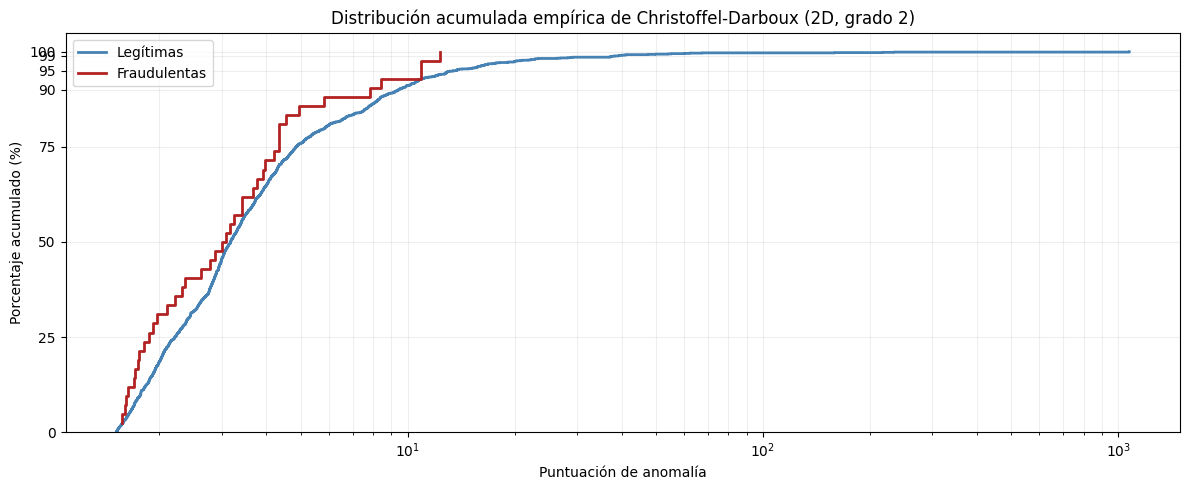

In [121]:
fig, ax = plt.subplots(figsize=(12, 5))

for scores, color, etiqueta in [
    (scores_cd_legit_2d, "steelblue", "Legítimas"),
    (scores_cd_fraud_2d, "firebrick", "Fraudulentas")
]:

    scores_ordenados = np.sort(scores)

    proporcion_acumulada = (
        np.arange(1, len(scores_ordenados) + 1)
        / len(scores_ordenados)
    )

    ax.step(
        scores_ordenados,
        proporcion_acumulada * 100,
        where="post",
        color=color,
        linewidth=2,
        label=etiqueta
    )

ax.set_title(
    "Distribución acumulada empírica de Christoffel-Darboux "
    "(2D, grado 2)"
)

ax.set_xlabel("Puntuación de anomalía")
ax.set_ylabel("Porcentaje acumulado (%)")

ax.set_xscale("log")
ax.set_ylim(0, 105)

ax.set_yticks([0, 25, 50, 75, 90, 95, 99, 100])

ax.legend()
ax.grid(alpha=0.2, which="both")

plt.tight_layout()
plt.show()

#### Conclusiones preliminares

La implementación del kernel de Christoffel-Darboux
mediante la factorización de Cholesky fue validada
numérica y algebraicamente.

Para dos componentes principales y una base
polinomial de grado dos, las transacciones
legítimas presentan una mayor dispersión y
puntuaciones extremas considerablemente superiores
a las transacciones fraudulentas.

Existe un solapamiento importante entre las
distribuciones de ambas clases, lo que sugiere
que una puntuación elevada de anomalía no
necesariamente implica la presencia de fraude.

Será necesario evaluar los conjuntos de subnivel
y sus correspondientes umbrales para determinar
la capacidad discriminativa del método.

### 6.5. Determinación de los umbrales de Christoffel-Darboux

Se determinan los umbrales empíricos correspondientes
a los percentiles 50, 75, 90, 95 y 99 de las
puntuaciones de anomalía de las transacciones
legítimas de entrenamiento.

Cada umbral define un conjunto de subnivel:

$$
S_\rho = \{x \in \mathbb{R}^2 : p_{CD}(x) \leq \rho\}
$$

Se verifica la cobertura empírica de las regiones
y se analiza la cantidad de transacciones
fraudulentas contenidas dentro y fuera de ellas.

In [122]:
def calcular_umbrales_cd(
    scores_legit,
    percentiles=(50, 75, 90, 95, 99)
):
    """
    Calcula los umbrales empíricos de los conjuntos
    de subnivel de Christoffel-Darboux.
    """

    scores_ordenados = np.sort(scores_legit)

    N = len(scores_ordenados)

    umbrales = {}

    for n in percentiles:

        k = int(np.ceil(n * N / 100))

        rho = scores_ordenados[k - 1]

        umbrales[n] = rho

    return umbrales

In [123]:
umbrales_cd_2d = calcular_umbrales_cd(
    scores_cd_legit_2d
)

print("Umbrales de Christoffel-Darboux\n")

for n, rho in umbrales_cd_2d.items():

    print(f"Percentil {n}%: rho = {rho:.6f}")

Umbrales de Christoffel-Darboux

Percentil 50%: rho = 3.174890
Percentil 75%: rho = 4.850003
Percentil 90%: rho = 9.421648
Percentil 95%: rho = 13.431209
Percentil 99%: rho = 39.433261


In [124]:
def evaluar_cobertura_cd(
    scores_legit,
    scores_fraud,
    umbrales
):

    N = len(scores_legit)

    resultados = []

    for n, rho in umbrales.items():

        legit_dentro = np.sum(scores_legit <= rho)
        legit_fuera = np.sum(scores_legit > rho)

        fraud_dentro = np.sum(scores_fraud <= rho)
        fraud_fuera = np.sum(scores_fraud > rho)

        cobertura = legit_dentro / N * 100

        cumple = n <= cobertura < n + 1

        resultados.append({
            "percentil": n,
            "umbral": rho,
            "legitimas_dentro": legit_dentro,
            "legitimas_fuera": legit_fuera,
            "cobertura_legit_pct": cobertura,
            "cumple_condicion": cumple,
            "fraudes_dentro": fraud_dentro,
            "fraudes_fuera": fraud_fuera
        })

    return pd.DataFrame(resultados)

In [125]:
df_cobertura_cd_2d = evaluar_cobertura_cd(
    scores_cd_legit_2d,
    scores_cd_fraud_2d,
    umbrales_cd_2d
)

display(df_cobertura_cd_2d.round(4))

,percentil,umbral,legitimas_dentro,legitimas_fuera,cobertura_legit_pct,cumple_condicion,fraudes_dentro,fraudes_fuera
0,50,3.1749,747,747,50.0000,True,23,19
1,75,4.8500,1121,373,75.0335,True,35,7
2,90,9.4216,1345,149,90.0268,True,39,3
3,95,13.4312,1420,74,95.0469,True,42,0
4,99,39.4333,1480,14,99.0629,True,42,0


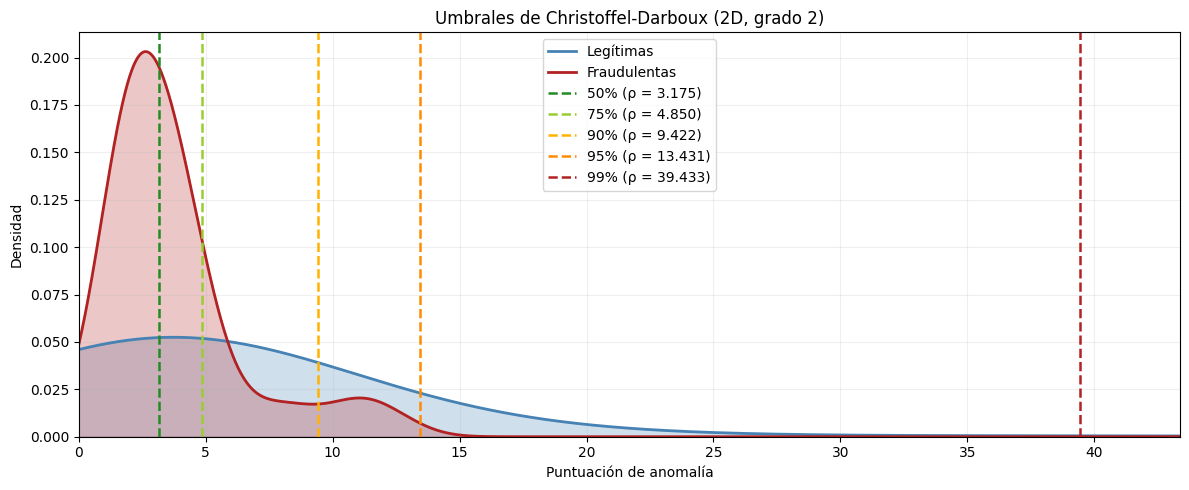

In [126]:
# Visualización de los umbrales
colores_percentiles = {
    50: "forestgreen",
    75: "yellowgreen",
    90: "#FFB300",
    95: "darkorange",
    99: "firebrick"
}

limite_x = umbrales_cd_2d[99] * 1.10

eje_x_cd = np.linspace(
    0,
    limite_x,
    2000
)

fig, ax = plt.subplots(figsize=(12, 5))

# Distribuciones de puntuaciones
for kde, color, etiqueta in [
    (kde_legit_cd, "steelblue", "Legítimas"),
    (kde_fraud_cd, "firebrick", "Fraudulentas")
]:

    densidad = kde(eje_x_cd)

    ax.plot(
        eje_x_cd,
        densidad,
        color=color,
        linewidth=2,
        label=etiqueta
    )

    ax.fill_between(
        eje_x_cd,
        densidad,
        color=color,
        alpha=0.25
    )

# Umbrales empíricos
for n, rho in umbrales_cd_2d.items():

    ax.axvline(
        rho,
        color=colores_percentiles[n],
        linestyle="--",
        linewidth=1.8,
        label=f"{n}% (ρ = {rho:.3f})"
    )

ax.set_title(
    "Umbrales de Christoffel-Darboux (2D, grado 2)"
)

ax.set_xlabel("Puntuación de anomalía")
ax.set_ylabel("Densidad")

ax.set_xlim(0, limite_x)
ax.set_ylim(bottom=0)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [127]:
# Tasas de detección y falsas alarmas
df_deteccion_cd_2d = df_cobertura_cd_2d.copy()

df_deteccion_cd_2d["tpr_pct"] = (
    df_deteccion_cd_2d["fraudes_fuera"]
    / len(scores_cd_fraud_2d)
    * 100
)

df_deteccion_cd_2d["fpr_pct"] = (
    df_deteccion_cd_2d["legitimas_fuera"]
    / len(scores_cd_legit_2d)
    * 100
)

df_deteccion_cd_2d["ventaja_deteccion_pp"] = (
    df_deteccion_cd_2d["tpr_pct"]
    - df_deteccion_cd_2d["fpr_pct"]
)

display(
    df_deteccion_cd_2d[
        [
            "percentil",
            "umbral",
            "fraudes_fuera",
            "tpr_pct",
            "fpr_pct",
            "ventaja_deteccion_pp"
        ]
    ].round(4)
)

,percentil,umbral,fraudes_fuera,tpr_pct,fpr_pct,ventaja_deteccion_pp
0,50,3.1749,19,45.2381,50.0000,-4.7619
1,75,4.8500,7,16.6667,24.9665,-8.2999
2,90,9.4216,3,7.1429,9.9732,-2.8304
3,95,13.4312,0,0.0000,4.9531,-4.9531
4,99,39.4333,0,0.0000,0.9371,-0.9371


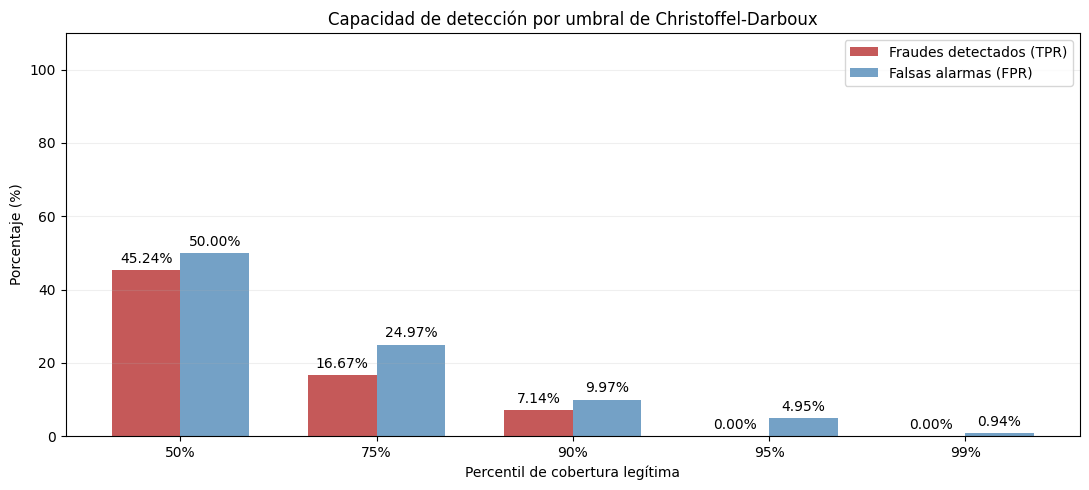

In [128]:
fig, ax = plt.subplots(figsize=(11, 5))

posiciones = np.arange(len(df_deteccion_cd_2d))
ancho = 0.35

barras_tpr = ax.bar(
    posiciones - ancho / 2,
    df_deteccion_cd_2d["tpr_pct"],
    width=ancho,
    color="firebrick",
    alpha=0.75,
    label="Fraudes detectados (TPR)"
)

barras_fpr = ax.bar(
    posiciones + ancho / 2,
    df_deteccion_cd_2d["fpr_pct"],
    width=ancho,
    color="steelblue",
    alpha=0.75,
    label="Falsas alarmas (FPR)"
)

ax.bar_label(
    barras_tpr,
    fmt="%.2f%%",
    padding=3
)

ax.bar_label(
    barras_fpr,
    fmt="%.2f%%",
    padding=3
)

ax.set_xticks(posiciones)

ax.set_xticklabels([
    f"{n}%"
    for n in df_deteccion_cd_2d["percentil"]
])

ax.set_title(
    "Capacidad de detección por umbral de Christoffel-Darboux"
)

ax.set_xlabel("Percentil de cobertura legítima")
ax.set_ylabel("Porcentaje (%)")

ax.set_ylim(0, 110)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

#### 6.6. Visualización de los conjuntos de subnivel

Se construye una malla bidimensional sobre el
espacio de las componentes principales PC1 y PC2.

Para cada punto de la malla se calcula la puntuación
del kernel de Christoffel-Darboux.

Posteriormente, se representan las curvas de nivel
correspondientes a los umbrales empíricos del
50%, 75%, 90%, 95% y 99%.

El objetivo es analizar la geometría de las regiones
y compararla con las fronteras elípticas obtenidas
mediante la distancia de Mahalanobis.

In [129]:
# Generación de la malla
# Resolución de la malla
resolucion = 500

# Límites del espacio PCA
x_min, x_max = -7.5, 7.5
y_min, y_max = -6, 6

# Coordenadas de cada eje
eje_pc1 = np.linspace(x_min, x_max, resolucion)
eje_pc2 = np.linspace(y_min, y_max, resolucion)

# Construcción de la malla
XX_cd, YY_cd = np.meshgrid(
    eje_pc1,
    eje_pc2
)

# Convertir la malla en una matriz de observaciones
X_grid_cd = np.column_stack([
    XX_cd.ravel(),
    YY_cd.ravel()
])

print("Dimensiones de XX:", XX_cd.shape)
print("Dimensiones de YY:", YY_cd.shape)
print("Dimensiones de la malla:", X_grid_cd.shape)

print(
    f"Puntos por evaluar: {len(X_grid_cd):,}"
)

Dimensiones de XX: (500, 500)
Dimensiones de YY: (500, 500)
Dimensiones de la malla: (250000, 2)
Puntos por evaluar: 250,000


In [130]:
inicio = perf_counter()

# Evaluar el kernel sobre cada punto
scores_grid_cd = calcular_score_cd(
    X_grid_cd,
    poly_2d,
    L_2d
)

# Recuperar la estructura bidimensional
ZZ_cd = scores_grid_cd.reshape(XX_cd.shape)

tiempo_grid_cd = perf_counter() - inicio

print("Dimensiones de ZZ:", ZZ_cd.shape)

print(f"Score mínimo: {ZZ_cd.min():.6f}")
print(f"Score máximo: {ZZ_cd.max():.6f}")

print(
    "Todos los scores son finitos:",
    np.isfinite(ZZ_cd).all()
)

print(
    "Todos los scores son positivos:",
    np.all(ZZ_cd > 0)
)

print(
    f"Tiempo de evaluación: {tiempo_grid_cd:.6f} s"
)

Dimensiones de ZZ: (500, 500)
Score mínimo: 1.512152
Score máximo: 1567.953120
Todos los scores son finitos: True
Todos los scores son positivos: True
Tiempo de evaluación: 0.017630 s


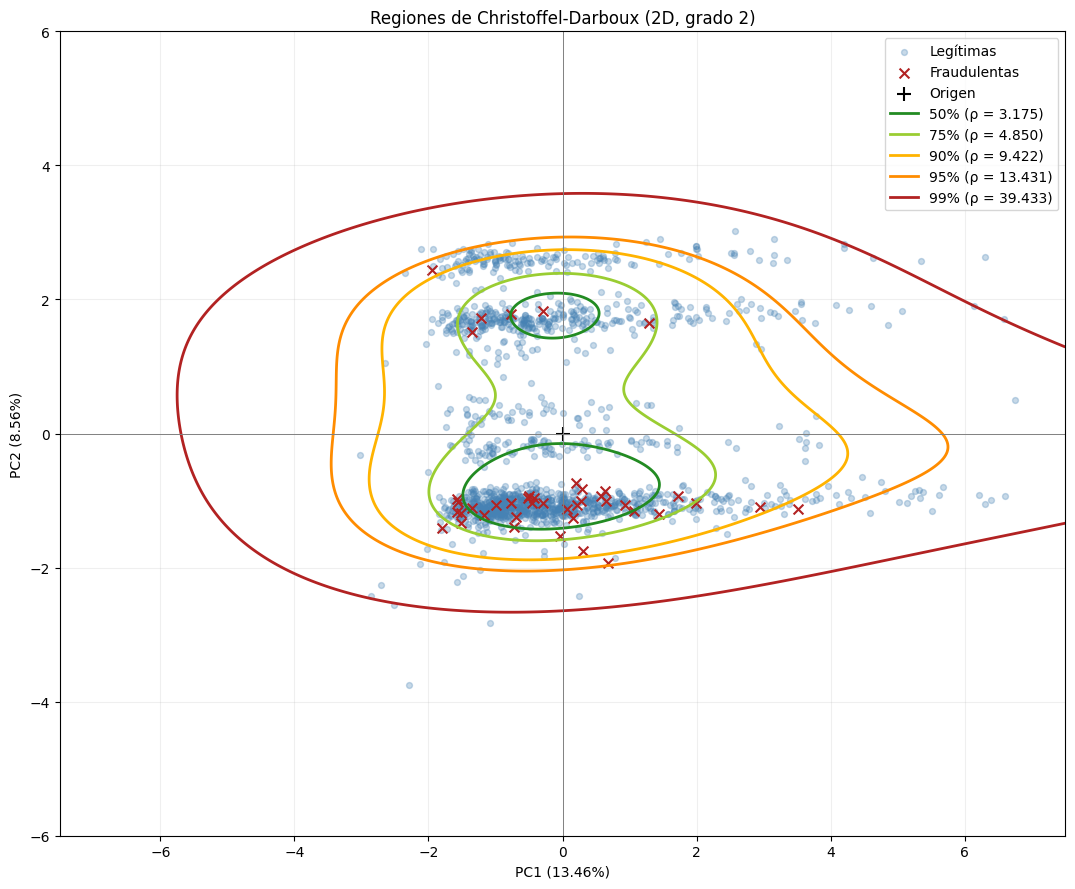

In [131]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(12, 9))

# Transacciones legítimas
ax.scatter(
    X_legit_2d[:, 0],
    X_legit_2d[:, 1],
    color="steelblue",
    alpha=0.30,
    s=18,
    label="Legítimas"
)

# Transacciones fraudulentas
ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="firebrick",
    marker="x",
    s=50,
    linewidths=1.5,
    label="Fraudulentas"
)

# Elementos adicionales de la leyenda
leyenda_umbrales = []

# Curvas de nivel
for n, rho in umbrales_cd_2d.items():

    color = colores_percentiles[n]

    ax.contour(
        XX_cd,
        YY_cd,
        ZZ_cd,
        levels=[rho],
        colors=[color],
        linewidths=2
    )

    leyenda_umbrales.append(
        Line2D(
            [0], [0],
            color=color,
            linewidth=2,
            label=f"{n}% (ρ = {rho:.3f})"
        )
    )

# Origen
ax.scatter(
    0, 0,
    color="black",
    marker="+",
    s=100,
    label="Origen"
)

# Ejes de referencia
ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="gray", linewidth=0.7)

# Configuración
ax.set_title(
    "Regiones de Christoffel-Darboux (2D, grado 2)"
)

ax.set_xlabel("PC1 (13.46%)")
ax.set_ylabel("PC2 (8.56%)")

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

ax.set_aspect("equal")
ax.grid(alpha=0.2)

# Construcción de la leyenda
handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles=handles + leyenda_umbrales,
    loc="upper right"
)

plt.tight_layout()
plt.show()

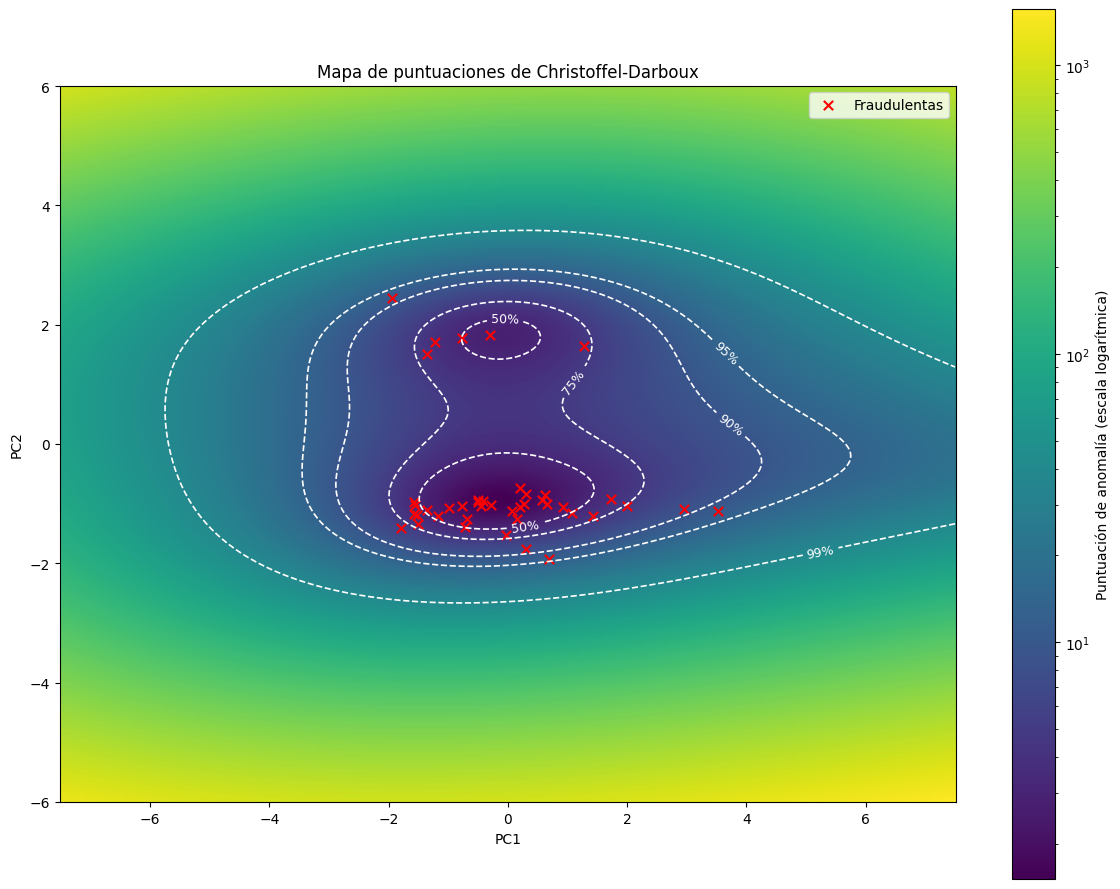

In [132]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(12, 9))

# Mapa continuo de puntuaciones
mapa = ax.pcolormesh(
    XX_cd,
    YY_cd,
    ZZ_cd,
    shading="auto",
    cmap="viridis",
    norm=LogNorm(
        vmin=ZZ_cd.min(),
        vmax=ZZ_cd.max()
    )
)

# Fronteras de los conjuntos de subnivel
contornos = ax.contour(
    XX_cd,
    YY_cd,
    ZZ_cd,
    levels=list(umbrales_cd_2d.values()),
    colors="white",
    linewidths=1.2,
    linestyles="--"
)

# Etiquetas de los percentiles
etiquetas = {
    rho: f"{n}%"
    for n, rho in umbrales_cd_2d.items()
}

ax.clabel(
    contornos,
    fmt=etiquetas,
    fontsize=9
)

# Transacciones fraudulentas
ax.scatter(
    X_fraud_2d[:, 0],
    X_fraud_2d[:, 1],
    color="red",
    marker="x",
    s=45,
    linewidths=1.5,
    label="Fraudulentas"
)

# Barra de color
cbar = fig.colorbar(mapa, ax=ax)

cbar.set_label(
    "Puntuación de anomalía (escala logarítmica)"
)

ax.set_title(
    "Mapa de puntuaciones de Christoffel-Darboux"
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")

ax.set_aspect("equal")
ax.legend()

plt.tight_layout()
plt.show()

Regiones disconexas: el conjunto de subnivel del 50% presenta dos regiones separadas, algo que no era posible con Mahalanobis.



Ausencia de simetría respecto al origen: las fronteras se extienden principalmente hacia los valores positivos de PC1.



Regiones no convexas: la frontera del 75% presenta concavidades claramente identificables.



Adaptación a la distribución: el kernel consigue representar parcialmente las bandas horizontales que observamos desde la primera visualización del espacio PCA.

Modelar correctamente la geometría de las transacciones legítimas no implica necesariamente distinguirlas de las fraudulentas.

#### 6.7. Análisis del riesgo empírico por región

Se divide el espacio de Christoffel-Darboux en seis
regiones mutuamente excluyentes, utilizando los
umbrales empíricos previamente calculados.

Para cada región se estima la probabilidad
empírica de fraude:

$$
\widehat{P}(F \mid R_i) =
\frac{N_{\text{fraud},i}}
{N_{\text{legit},i}+N_{\text{fraud},i}}
$$

Se compara el riesgo de cada región con el riesgo
global del conjunto de entrenamiento para
identificar zonas con mayor concentración de fraude.

In [133]:
def asignar_regiones_cd(scores, umbrales):
    """
    Asigna cada puntuación de Christoffel-Darboux
    a una región mutuamente excluyente.
    """

    limites = [
        -np.inf,
        umbrales[50],
        umbrales[75],
        umbrales[90],
        umbrales[95],
        umbrales[99],
        np.inf
    ]

    etiquetas = [
        "0% - 50%",
        "50% - 75%",
        "75% - 90%",
        "90% - 95%",
        "95% - 99%",
        "Exterior 99%"
    ]

    return pd.cut(
        scores,
        bins=limites,
        labels=etiquetas,
        right=True
    )

In [134]:
regiones_cd_legit_2d = asignar_regiones_cd(
    scores_cd_legit_2d,
    umbrales_cd_2d
)

regiones_cd_fraud_2d = asignar_regiones_cd(
    scores_cd_fraud_2d,
    umbrales_cd_2d
)

print(
    "Legítimas clasificadas:",
    len(regiones_cd_legit_2d)
)

print(
    "Fraudulentas clasificadas:",
    len(regiones_cd_fraud_2d)
)

print(
    "Legítimas sin región:",
    pd.isna(regiones_cd_legit_2d).sum()
)

print(
    "Fraudulentas sin región:",
    pd.isna(regiones_cd_fraud_2d).sum()
)

Legítimas clasificadas: 1494
Fraudulentas clasificadas: 42
Legítimas sin región: 0
Fraudulentas sin región: 0


In [135]:
def calcular_riesgo_regiones_cd(
    scores_legit,
    scores_fraud,
    umbrales
):

    regiones_legit = asignar_regiones_cd(
        scores_legit,
        umbrales
    )

    regiones_fraud = asignar_regiones_cd(
        scores_fraud,
        umbrales
    )

    conteo_legit = (
        pd.Series(regiones_legit)
        .value_counts(sort=False)
    )

    conteo_fraud = (
        pd.Series(regiones_fraud)
        .value_counts(sort=False)
    )

    df_riesgo = pd.DataFrame({
        "legitimas": conteo_legit,
        "fraudulentas": conteo_fraud
    })

    df_riesgo.index.name = "region"

    df_riesgo["total"] = (
        df_riesgo["legitimas"]
        + df_riesgo["fraudulentas"]
    )

    df_riesgo["riesgo_pct"] = (
        df_riesgo["fraudulentas"]
        / df_riesgo["total"].replace(0, np.nan)
        * 100
    )

    riesgo_global = (
        len(scores_fraud)
        / (len(scores_legit) + len(scores_fraud))
        * 100
    )

    df_riesgo["lift"] = (
        df_riesgo["riesgo_pct"] / riesgo_global
    )

    df_riesgo["concentracion_fraudes_pct"] = (
        df_riesgo["fraudulentas"]
        / len(scores_fraud)
        * 100
    )

    return df_riesgo, riesgo_global

In [136]:
df_riesgo_cd_2d, riesgo_global_cd_2d = (
    calcular_riesgo_regiones_cd(
        scores_cd_legit_2d,
        scores_cd_fraud_2d,
        umbrales_cd_2d
    )
)

print(f"Riesgo global: {riesgo_global_cd_2d:.4f}%")

display(df_riesgo_cd_2d.round(4))

Riesgo global: 2.7344%


,legitimas,fraudulentas,total,riesgo_pct,lift,concentracion_fraudes_pct
region,,,,,,
0% - 50%,747,23,770,2.9870,1.0924,54.7619
50% - 75%,374,12,386,3.1088,1.1369,28.5714
75% - 90%,224,4,228,1.7544,0.6416,9.5238
90% - 95%,75,3,78,3.8462,1.4066,7.1429
95% - 99%,60,0,60,0.0000,0.0000,0.0000
Exterior 99%,14,0,14,0.0000,0.0000,0.0000


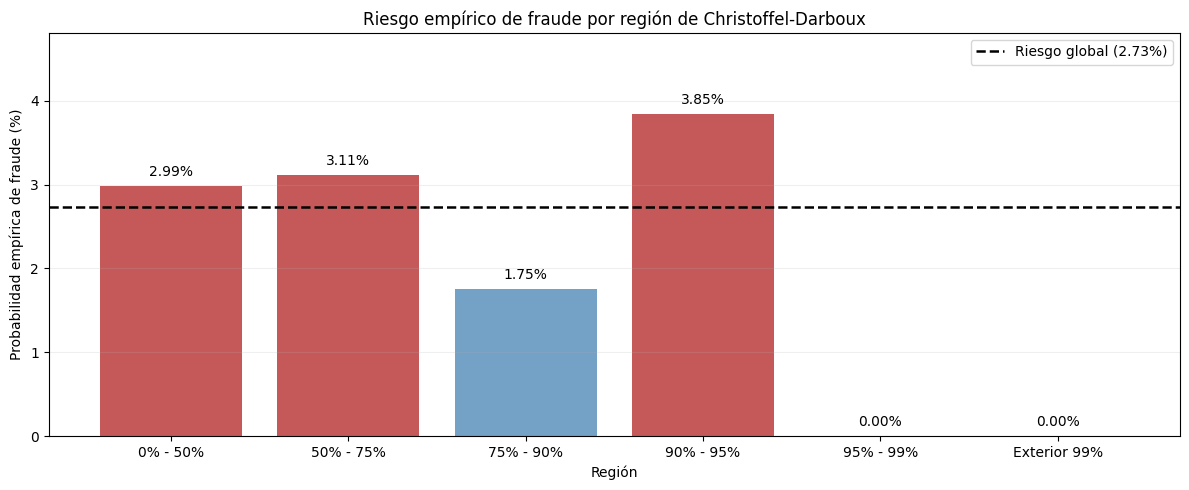

In [137]:
fig, ax = plt.subplots(figsize=(12, 5))

colores_riesgo = [
    "firebrick" if riesgo > riesgo_global_cd_2d
    else "steelblue"
    for riesgo in df_riesgo_cd_2d["riesgo_pct"]
]

barras = ax.bar(
    df_riesgo_cd_2d.index.astype(str),
    df_riesgo_cd_2d["riesgo_pct"],
    color=colores_riesgo,
    alpha=0.75
)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=5
)

# Riesgo global de referencia
ax.axhline(
    riesgo_global_cd_2d,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Riesgo global ({riesgo_global_cd_2d:.2f}%)"
)

ax.set_title(
    "Riesgo empírico de fraude por región "
    "de Christoffel-Darboux"
)

ax.set_xlabel("Región")
ax.set_ylabel("Probabilidad empírica de fraude (%)")

ax.set_ylim(
    0,
    max(
        df_riesgo_cd_2d["riesgo_pct"].max(),
        riesgo_global_cd_2d
    ) * 1.25
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

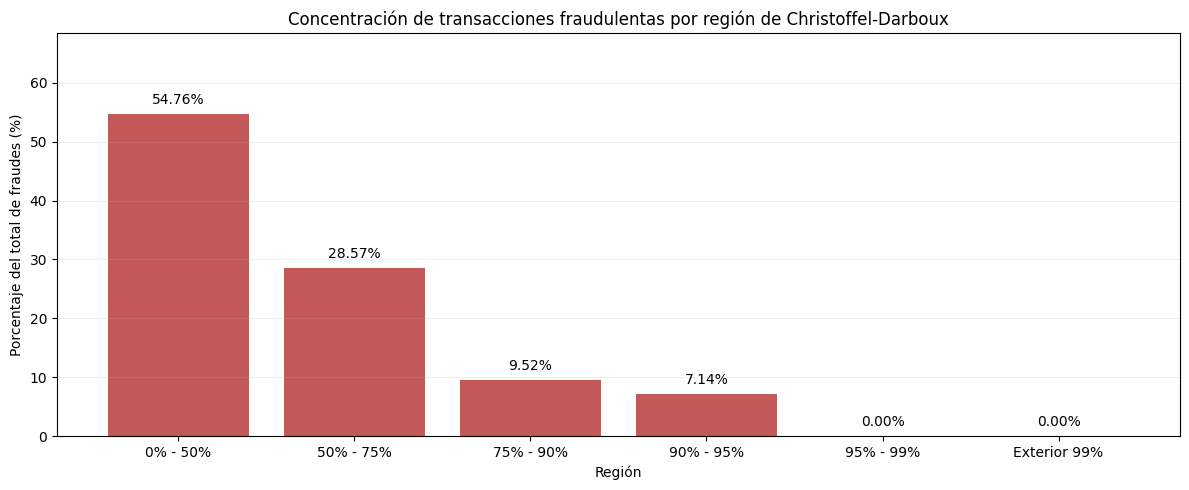

In [138]:
fig, ax = plt.subplots(figsize=(12, 5))

barras = ax.bar(
    df_riesgo_cd_2d.index.astype(str),
    df_riesgo_cd_2d["concentracion_fraudes_pct"],
    color="firebrick",
    alpha=0.75
)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=5
)

ax.set_title(
    "Concentración de transacciones fraudulentas "
    "por región de Christoffel-Darboux"
)

ax.set_xlabel("Región")
ax.set_ylabel("Porcentaje del total de fraudes (%)")

ax.set_ylim(
    0,
    df_riesgo_cd_2d[
        "concentracion_fraudes_pct"
    ].max() * 1.25
)

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### 6.8. Evaluación y validación del detector de Christoffel-Darboux

Se evalúa la capacidad de clasificación del kernel
de Christoffel-Darboux utilizando los umbrales
empíricos del 50%, 75%, 90%, 95% y 99%.

Se selecciona el umbral que maximiza el F1-score
sobre el conjunto de entrenamiento.

Posteriormente, se aplica el modelo y el umbral
seleccionado al conjunto de prueba, sin modificar
los parámetros previamente estimados.

In [139]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)


def evaluar_detector(y_real, scores, umbral):

    y_real = np.asarray(y_real)
    scores = np.asarray(scores)

    # Regla de clasificación
    y_pred = (scores > umbral).astype(int)

    # Matriz de confusión
    TN, FP, FN, TP = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    fpr = FP / (FP + TN)
    specificity = TN / (TN + FP)

    return {
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP,
        "precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "fpr": fpr,
        "specificity": specificity,
        "balanced_accuracy": balanced_accuracy_score(
            y_real, y_pred
        )
    }

In [140]:
# Concatenación de puntuaciones
scores_cd_train_2d = np.concatenate([
    scores_cd_legit_2d,
    scores_cd_fraud_2d
])

# Etiquetas correspondientes
y_cd_train_2d = np.concatenate([
    np.zeros(len(scores_cd_legit_2d), dtype=int),
    np.ones(len(scores_cd_fraud_2d), dtype=int)
])

resultados_cd_2d = []

for percentil, umbral in umbrales_cd_2d.items():

    metricas = evaluar_detector(
        y_cd_train_2d,
        scores_cd_train_2d,
        umbral
    )

    resultados_cd_2d.append({
        "percentil": percentil,
        "radio": umbral,
        **metricas
    })

df_evaluacion_cd_2d = pd.DataFrame(
    resultados_cd_2d
)

display(df_evaluacion_cd_2d.round(4))

,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,50,3.1749,747,747,23,19,0.0248,0.4524,0.0470,0.5000,0.5000,0.4762
1,75,4.8500,1121,373,35,7,0.0184,0.1667,0.0332,0.2497,0.7503,0.4585
2,90,9.4216,1345,149,39,3,0.0197,0.0714,0.0309,0.0997,0.9003,0.4858
3,95,13.4312,1420,74,42,0,0.0000,0.0000,0.0000,0.0495,0.9505,0.4752
4,99,39.4333,1480,14,42,0,0.0000,0.0000,0.0000,0.0094,0.9906,0.4953


In [141]:
# F1 score como criterio de selección
mejor_cd_2d = (
    df_evaluacion_cd_2d
    .sort_values(
        ["f1_score", "recall"],
        ascending=[False, False]
    )
    .iloc[0]
)

percentil_optimo_cd_2d = int(
    mejor_cd_2d["percentil"]
)

umbral_optimo_cd_2d = float(
    mejor_cd_2d["radio"]
)

print(
    f"Percentil seleccionado: "
    f"{percentil_optimo_cd_2d}%"
)

print(
    f"Umbral seleccionado: "
    f"{umbral_optimo_cd_2d:.6f}"
)

for metrica in [
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "balanced_accuracy"
]:
    print(
        f"{metrica}: "
        f"{mejor_cd_2d[metrica]:.4f}"
    )

Percentil seleccionado: 50%
Umbral seleccionado: 3.174890
precision: 0.0248
recall: 0.4524
f1_score: 0.0470
fpr: 0.5000
balanced_accuracy: 0.4762


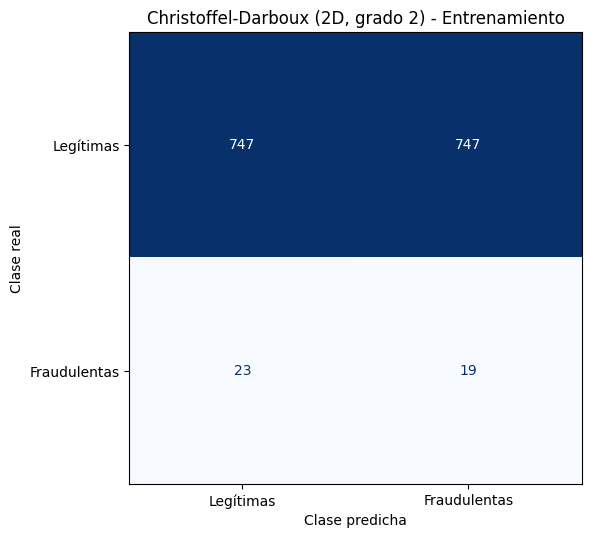

In [142]:
# Matriz de confusión sobre entrenamiento
y_pred_cd_train_2d = (
    scores_cd_train_2d > umbral_optimo_cd_2d
).astype(int)

cm_cd_train_2d = confusion_matrix(
    y_cd_train_2d,
    y_pred_cd_train_2d,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cd_train_2d,
    display_labels=[
        "Legítimas",
        "Fraudulentas"
    ]
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title(
    "Christoffel-Darboux (2D, grado 2) - Entrenamiento"
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

In [143]:
# Evaluación sobre el conjuto de pruebas
# Primeras dos componentes principales
X_test_cd_2d = X_test_pca[:, :2]

inicio = perf_counter()

# Utilizar el modelo previamente ajustado
scores_cd_test_2d = calcular_score_cd(
    X_test_cd_2d,
    poly_2d,
    L_2d
)

tiempo_inferencia_cd_2d = (
    perf_counter() - inicio
)

print("Validaciones del conjunto de prueba\n")

print(
    "Dimensiones de X:",
    X_test_cd_2d.shape
)

print(
    "Dimensiones de scores:",
    scores_cd_test_2d.shape
)

print(
    "Scores finitos:",
    np.isfinite(scores_cd_test_2d).all()
)

print(
    "Scores positivos:",
    np.all(scores_cd_test_2d > 0)
)

print(
    f"Tiempo de inferencia: "
    f"{tiempo_inferencia_cd_2d:.6f} s"
)

Validaciones del conjunto de prueba

Dimensiones de X: (385, 2)
Dimensiones de scores: (385,)
Scores finitos: True
Scores positivos: True
Tiempo de inferencia: 0.000666 s


In [144]:
metricas_cd_test_2d = evaluar_detector(
    y_test,
    scores_cd_test_2d,
    umbral_optimo_cd_2d
)

auc_cd_test_2d = roc_auc_score(
    y_test,
    scores_cd_test_2d
)

df_resultado_cd_2d = pd.DataFrame([{
    "metodo": "Christoffel-Darboux",
    "componentes": 2,
    "grado": 2,
    "monomios": 6,
    "varianza_explicada_pct": (
        pca.explained_variance_ratio_[:2].sum()
        * 100
    ),
    "percentil": percentil_optimo_cd_2d,
    "radio": umbral_optimo_cd_2d,
    **metricas_cd_test_2d,
    "roc_auc": auc_cd_test_2d,
    "tiempo_inferencia_s": tiempo_inferencia_cd_2d
}])

display(df_resultado_cd_2d.round(6))

,metodo,componentes,grado,monomios,varianza_explicada_pct,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy,roc_auc,tiempo_inferencia_s
0,Christoffel-Darboux,2,2,6,22.020426,50,3.17489,177,198,6,4,0.019802,0.4,0.037736,0.528,0.472,0.436,0.464267,0.000666


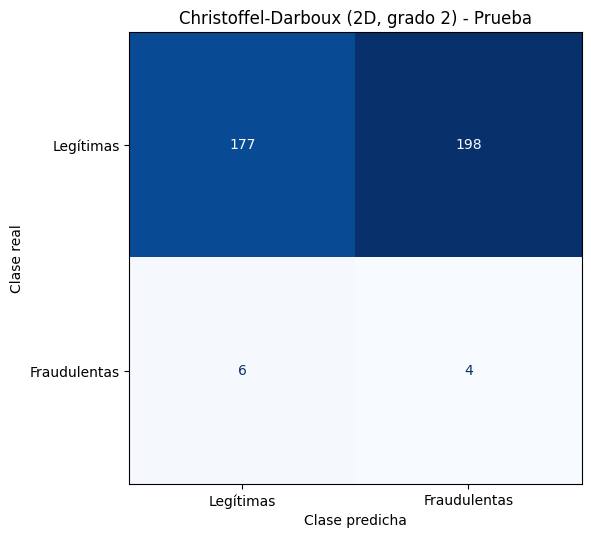

In [145]:
y_pred_cd_test_2d = (
    scores_cd_test_2d > umbral_optimo_cd_2d
).astype(int)

cm_cd_test_2d = confusion_matrix(
    y_test,
    y_pred_cd_test_2d,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_cd_test_2d,
    display_labels=[
        "Legítimas",
        "Fraudulentas"
    ]
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title(
    "Christoffel-Darboux (2D, grado 2) - Prueba"
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

#### 6.9. Christoffel-Darboux en dos dimensiones con polinomios de cuarto grado
Se incrementa el grado de la transformación
polinomial de dos a cuatro, conservando las
primeras dos componentes principales.

El espacio polinomial aumenta de 6 a 15
dimensiones, permitiendo representar fronteras
determinadas por polinomios de hasta grado ocho.

Se conserva la misma metodología de regularización,
calibración de umbrales y evaluación utilizada
en los experimentos anteriores.

In [146]:
from math import comb
from sklearn.preprocessing import PolynomialFeatures

grado_cd_2d_g4 = 4
componentes_cd_2d_g4 = 2

# Número teórico de monomios
monomios_esperados_g4 = comb(
    componentes_cd_2d_g4 + grado_cd_2d_g4,
    grado_cd_2d_g4
)

# Transformación polinomial
poly_2d_g4 = PolynomialFeatures(
    degree=grado_cd_2d_g4,
    include_bias=True
)

# Matriz de diseño
D_2d_g4 = poly_2d_g4.fit_transform(
    X_legit_2d
)

N_g4, m_g4 = D_2d_g4.shape

print("Grado polinomial:", grado_cd_2d_g4)
print("Número de observaciones:", N_g4)
print("Número de monomios:", m_g4)
print("Monomios esperados:", monomios_esperados_g4)
print("Dimensiones de D:", D_2d_g4.shape)

print(
    "Dimensión correcta:",
    m_g4 == monomios_esperados_g4
)

Grado polinomial: 4
Número de observaciones: 1494
Número de monomios: 15
Monomios esperados: 15
Dimensiones de D: (1494, 15)
Dimensión correcta: True


In [147]:
nombres_monomios_g4 = (
    poly_2d_g4.get_feature_names_out(
        ["PC1", "PC2"]
    )
)

df_monomios_g4 = pd.DataFrame(
    D_2d_g4,
    columns=nombres_monomios_g4
)

display(df_monomios_g4.head(10).round(4))

,1,PC1,PC2,PC1^2,PC1 PC2,PC2^2,PC1^3,PC1^2 PC2,PC1 PC2^2,PC2^3,PC1^4,PC1^3 PC2,PC1^2 PC2^2,PC1 PC2^3,PC2^4
0,1.0,-0.7048,-0.9098,0.4968,0.6413,0.8278,-0.3502,-0.4520,-0.5834,-0.7531,0.2468,0.3186,0.4112,0.5308,0.6852
1,1.0,-1.0213,1.7109,1.0430,-1.7472,2.9271,-1.0651,1.7844,-2.9893,5.0080,1.0878,-1.8223,3.0529,-5.1144,8.5681
2,1.0,1.6640,-1.1609,2.7689,-1.9318,1.3477,4.6076,-3.2145,2.2426,-1.5645,7.6670,-5.3489,3.7317,-2.6034,1.8163
3,1.0,0.0962,-1.2079,0.0092,-0.1162,1.4590,0.0009,-0.0112,0.1403,-1.7623,0.0001,-0.0011,0.0135,-0.1695,2.1287
4,1.0,0.2753,-1.1915,0.0758,-0.3280,1.4196,0.0209,-0.0903,0.3908,-1.6914,0.0057,-0.0249,0.1076,-0.4656,2.0153
5,1.0,-0.8970,1.7487,0.8046,-1.5686,3.0580,-0.7217,1.4070,-2.7430,5.3476,0.6474,-1.2621,2.4605,-4.7968,9.3514
6,1.0,-1.2322,-1.2297,1.5184,1.5153,1.5123,-1.8709,-1.8672,-1.8634,-1.8597,2.3054,2.3008,2.2961,2.2915,2.2869
7,1.0,2.5733,3.0273,6.6217,7.7900,9.1644,17.0392,20.0456,23.5825,27.7434,43.8463,51.5825,60.6838,71.3908,83.9871
8,1.0,1.3239,-1.1516,1.7527,-1.5246,1.3263,2.3204,-2.0184,1.7558,-1.5274,3.0719,-2.6722,2.3245,-2.0221,1.7590
9,1.0,-0.2812,-1.1579,0.0791,0.3256,1.3408,-0.0222,-0.0915,-0.3770,-1.5525,0.0062,0.0257,0.1060,0.4365,1.7977


In [148]:
inicio = perf_counter()

# Matriz de momentos
M_2d_g4 = (
    D_2d_g4.T @ D_2d_g4
) / N_g4

# Regularización de Tikhonov
epsilon_g4 = 1e-6

M_reg_2d_g4 = (
    M_2d_g4
    + epsilon_g4 * np.eye(m_g4)
)

# Factorización de Cholesky
L_2d_g4 = np.linalg.cholesky(
    M_reg_2d_g4
)

tiempo_ajuste_cd_2d_g4 = (
    perf_counter() - inicio
)

In [149]:
valores_propios_g4 = np.linalg.eigvalsh(
    M_reg_2d_g4
)

print("Validaciones de la matriz de momentos\n")

print("Dimensiones:", M_2d_g4.shape)

print(
    "Es simétrica:",
    np.allclose(M_2d_g4, M_2d_g4.T)
)

print(
    "Rango original:",
    np.linalg.matrix_rank(M_2d_g4)
)

print(
    "Rango regularizado:",
    np.linalg.matrix_rank(M_reg_2d_g4)
)

print(
    "Valor propio mínimo:",
    valores_propios_g4.min()
)

print(
    "Valor propio máximo:",
    valores_propios_g4.max()
)

print(
    "Es definida positiva:",
    np.all(valores_propios_g4 > 0)
)

print(
    "Número de condición original:",
    f"{np.linalg.cond(M_2d_g4):.6e}"
)

print(
    "Número de condición regularizado:",
    f"{np.linalg.cond(M_reg_2d_g4):.6e}"
)

print(
    "Factorización de Cholesky correcta:",
    np.allclose(
        L_2d_g4 @ L_2d_g4.T,
        M_reg_2d_g4
    )
)

print(
    f"Tiempo de ajuste: "
    f"{tiempo_ajuste_cd_2d_g4:.6f} s"
)

Validaciones de la matriz de momentos

Dimensiones: (15, 15)
Es simétrica: True
Rango original: 15
Rango regularizado: 15
Valor propio mínimo: 0.07974916259138973
Valor propio máximo: 113416612.21145815
Es definida positiva: True
Número de condición original: 1.422185e+09
Número de condición regularizado: 1.422167e+09
Factorización de Cholesky correcta: True
Tiempo de ajuste: 0.000524 s


In [151]:
media_empirica_g4 = (
    scores_cd_legit_2d_g4.mean()
)

media_teorica_g4 = np.trace(
    np.linalg.solve(
        M_reg_2d_g4,
        M_2d_g4
    )
)

print("Número de monomios:", m_g4)

print(
    f"Media empírica: "
    f"{media_empirica_g4:.10f}"
)

print(
    f"Media teórica: "
    f"{media_teorica_g4:.10f}"
)

print(
    "Coincidencia de medias:",
    np.isclose(
        media_empirica_g4,
        media_teorica_g4
    )
)

Número de monomios: 15
Media empírica: 14.9999772895
Media teórica: 14.9999772895
Coincidencia de medias: True


In [152]:
df_scores_cd_2d_g4 = pd.DataFrame({
    "Legítimas": pd.Series(
        scores_cd_legit_2d_g4
    ),
    "Fraudulentas": pd.Series(
        scores_cd_fraud_2d_g4
    )
})

display(
    df_scores_cd_2d_g4.describe().round(4)
)

,Legítimas,Fraudulentas
count,1494.0000,42.0000
mean,15.0000,8.7913
std,73.6555,14.0802
min,2.0052,2.0467
25%,3.1211,3.1162
50%,5.7341,4.8331
75%,10.3486,7.3713
max,1487.0299,86.8809


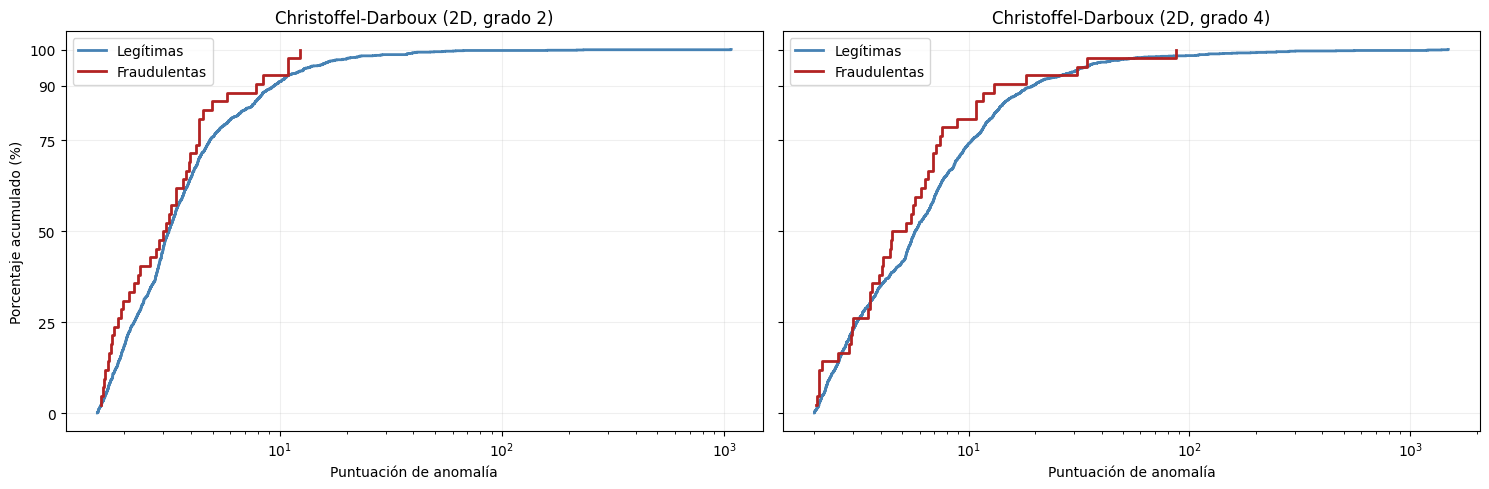

In [153]:
# Distribuciones acumuladas
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharey=True
)

configuraciones = [
    (
        scores_cd_legit_2d,
        scores_cd_fraud_2d,
        "Christoffel-Darboux (2D, grado 2)"
    ),
    (
        scores_cd_legit_2d_g4,
        scores_cd_fraud_2d_g4,
        "Christoffel-Darboux (2D, grado 4)"
    )
]

for ax, (legit, fraud, titulo) in zip(
    axes,
    configuraciones
):

    for scores, color, etiqueta in [
        (legit, "steelblue", "Legítimas"),
        (fraud, "firebrick", "Fraudulentas")
    ]:

        scores_ordenados = np.sort(scores)

        acumulado = (
            np.arange(1, len(scores) + 1)
            / len(scores)
            * 100
        )

        ax.step(
            scores_ordenados,
            acumulado,
            where="post",
            color=color,
            linewidth=2,
            label=etiqueta
        )

    ax.set_xscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("Puntuación de anomalía")
    ax.set_yticks([0, 25, 50, 75, 90, 100])
    ax.grid(alpha=0.2)
    ax.legend()

axes[0].set_ylabel("Porcentaje acumulado (%)")

plt.tight_layout()
plt.show()

In [154]:
percentiles_g4 = [50, 75, 90, 95, 99]

scores_ordenados_g4 = np.sort(
    scores_cd_legit_2d_g4
)

umbrales_cd_2d_g4 = {}
resultados_umbrales_g4 = []

for n in percentiles_g4:

    indice = int(
        np.ceil(N_g4 * n / 100)
    ) - 1

    rho = scores_ordenados_g4[indice]

    umbrales_cd_2d_g4[n] = rho

    cobertura = np.mean(
        scores_cd_legit_2d_g4 <= rho
    ) * 100

    fraudes_dentro = np.sum(
        scores_cd_fraud_2d_g4 <= rho
    )

    fraudes_fuera = np.sum(
        scores_cd_fraud_2d_g4 > rho
    )

    resultados_umbrales_g4.append({
        "percentil": n,
        "radio": rho,
        "cobertura_legit_pct": cobertura,
        "cumple_condicion": n <= cobertura < n + 1,
        "fraudes_dentro": fraudes_dentro,
        "fraudes_fuera": fraudes_fuera
    })

df_umbrales_cd_2d_g4 = pd.DataFrame(
    resultados_umbrales_g4
)

display(df_umbrales_cd_2d_g4.round(4))

,percentil,radio,cobertura_legit_pct,cumple_condicion,fraudes_dentro,fraudes_fuera
0,50,5.7309,50.0000,True,25,17
1,75,10.3606,75.0335,True,34,8
2,90,19.6270,90.0268,True,39,3
3,95,33.0434,95.0469,True,40,2
4,99,164.3311,99.0629,True,42,0


In [155]:
inicio = perf_counter()

scores_grid_cd_g4 = calcular_score_cd(
    X_grid_cd,
    poly_2d_g4,
    L_2d_g4
)

ZZ_cd_g4 = scores_grid_cd_g4.reshape(
    XX_cd.shape
)

tiempo_grid_cd_g4 = perf_counter() - inicio

print("Dimensiones:", ZZ_cd_g4.shape)

print(
    "Scores finitos:",
    np.isfinite(ZZ_cd_g4).all()
)

print(
    f"Tiempo de evaluación de la malla: "
    f"{tiempo_grid_cd_g4:.6f} s"
)

Dimensiones: (500, 500)
Scores finitos: True
Tiempo de evaluación de la malla: 0.046144 s


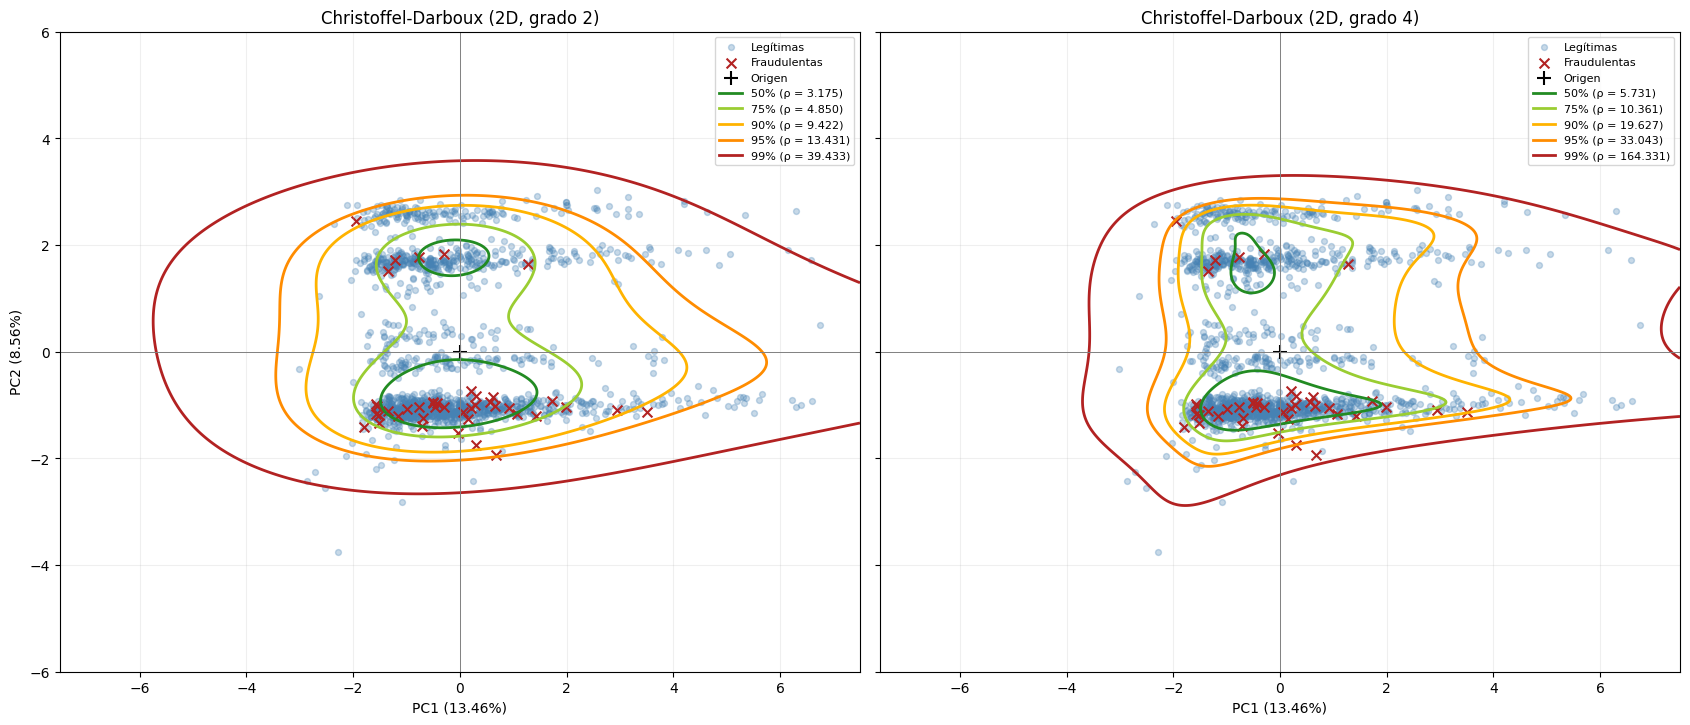

In [156]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    sharex=True,
    sharey=True
)

configuraciones = [
    (
        ZZ_cd,
        umbrales_cd_2d,
        "Christoffel-Darboux (2D, grado 2)"
    ),
    (
        ZZ_cd_g4,
        umbrales_cd_2d_g4,
        "Christoffel-Darboux (2D, grado 4)"
    )
]

for ax, (ZZ, umbrales, titulo) in zip(
    axes,
    configuraciones
):

    ax.scatter(
        X_legit_2d[:, 0],
        X_legit_2d[:, 1],
        color="steelblue",
        alpha=0.30,
        s=18,
        label="Legítimas"
    )

    ax.scatter(
        X_fraud_2d[:, 0],
        X_fraud_2d[:, 1],
        color="firebrick",
        marker="x",
        s=50,
        label="Fraudulentas"
    )

    leyenda_umbrales = []

    for n, rho in umbrales.items():

        color = colores_percentiles[n]

        ax.contour(
            XX_cd,
            YY_cd,
            ZZ,
            levels=[rho],
            colors=[color],
            linewidths=2
        )

        leyenda_umbrales.append(
            Line2D(
                [0], [0],
                color=color,
                linewidth=2,
                label=f"{n}% (ρ = {rho:.3f})"
            )
        )

    ax.scatter(
        0, 0,
        color="black",
        marker="+",
        s=100,
        label="Origen"
    )

    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)

    ax.set_title(titulo)
    ax.set_xlabel("PC1 (13.46%)")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

    handles, labels = ax.get_legend_handles_labels()

    ax.legend(
        handles=handles + leyenda_umbrales,
        loc="upper right",
        fontsize=8
    )

axes[0].set_ylabel("PC2 (8.56%)")

plt.tight_layout()
plt.show()

In [157]:
df_riesgo_cd_2d_g4, riesgo_global_cd_2d_g4 = (
    calcular_riesgo_regiones_cd(
        scores_cd_legit_2d_g4,
        scores_cd_fraud_2d_g4,
        umbrales_cd_2d_g4
    )
)

print(
    f"Riesgo global: "
    f"{riesgo_global_cd_2d_g4:.4f}%"
)

display(df_riesgo_cd_2d_g4.round(4))

Riesgo global: 2.7344%


,legitimas,fraudulentas,total,riesgo_pct,lift,concentracion_fraudes_pct
region,,,,,,
0% - 50%,747,25,772,3.2383,1.1843,59.5238
50% - 75%,374,9,383,2.3499,0.8594,21.4286
75% - 90%,224,5,229,2.1834,0.7985,11.9048
90% - 95%,75,1,76,1.3158,0.4812,2.3810
95% - 99%,60,2,62,3.2258,1.1797,4.7619
Exterior 99%,14,0,14,0.0000,0.0000,0.0000


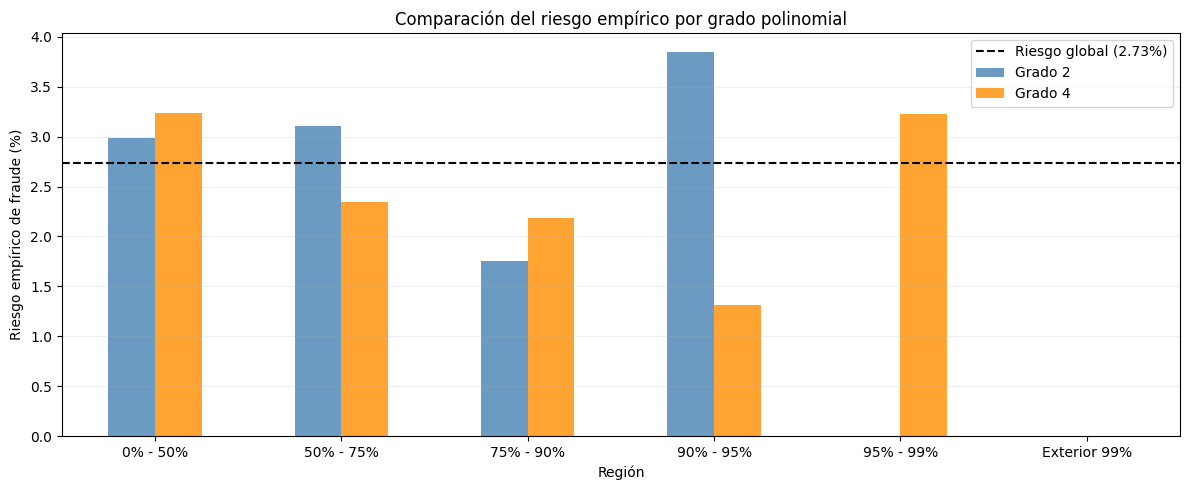

In [158]:
df_comparacion_riesgo_cd = pd.DataFrame({
    "Grado 2": df_riesgo_cd_2d["riesgo_pct"],
    "Grado 4": df_riesgo_cd_2d_g4["riesgo_pct"]
})

ax = df_comparacion_riesgo_cd.plot(
    kind="bar",
    figsize=(12, 5),
    color=["steelblue", "darkorange"],
    alpha=0.80,
    rot=0
)

ax.axhline(
    riesgo_global_cd_2d_g4,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Riesgo global ({riesgo_global_cd_2d_g4:.2f}%)"
)

ax.set_title(
    "Comparación del riesgo empírico "
    "por grado polinomial"
)

ax.set_xlabel("Región")
ax.set_ylabel("Riesgo empírico de fraude (%)")
ax.grid(axis="y", alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [159]:
scores_cd_train_2d_g4 = np.concatenate([
    scores_cd_legit_2d_g4,
    scores_cd_fraud_2d_g4
])

y_cd_train_2d_g4 = np.concatenate([
    np.zeros(
        len(scores_cd_legit_2d_g4),
        dtype=int
    ),
    np.ones(
        len(scores_cd_fraud_2d_g4),
        dtype=int
    )
])

resultados_cd_2d_g4 = []

for percentil, umbral in umbrales_cd_2d_g4.items():

    metricas = evaluar_detector(
        y_cd_train_2d_g4,
        scores_cd_train_2d_g4,
        umbral
    )

    resultados_cd_2d_g4.append({
        "percentil": percentil,
        "radio": umbral,
        **metricas
    })

df_evaluacion_cd_2d_g4 = pd.DataFrame(
    resultados_cd_2d_g4
)

display(df_evaluacion_cd_2d_g4.round(4))

,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,50,5.7309,747,747,25,17,0.0223,0.4048,0.0422,0.5000,0.5000,0.4524
1,75,10.3606,1121,373,34,8,0.0210,0.1905,0.0378,0.2497,0.7503,0.4704
2,90,19.6270,1345,149,39,3,0.0197,0.0714,0.0309,0.0997,0.9003,0.4858
3,95,33.0434,1420,74,40,2,0.0263,0.0476,0.0339,0.0495,0.9505,0.4990
4,99,164.3311,1480,14,42,0,0.0000,0.0000,0.0000,0.0094,0.9906,0.4953


In [160]:
mejor_cd_2d_g4 = (
    df_evaluacion_cd_2d_g4
    .sort_values(
        ["f1_score", "recall"],
        ascending=[False, False]
    )
    .iloc[0]
)

percentil_optimo_cd_2d_g4 = int(
    mejor_cd_2d_g4["percentil"]
)

umbral_optimo_cd_2d_g4 = float(
    mejor_cd_2d_g4["radio"]
)

print(
    f"Percentil seleccionado: "
    f"{percentil_optimo_cd_2d_g4}%"
)

print(
    f"Umbral seleccionado: "
    f"{umbral_optimo_cd_2d_g4:.6f}"
)

for metrica in [
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "balanced_accuracy"
]:

    print(
        f"{metrica}: "
        f"{mejor_cd_2d_g4[metrica]:.4f}"
    )

Percentil seleccionado: 50%
Umbral seleccionado: 5.730887
precision: 0.0223
recall: 0.4048
f1_score: 0.0422
fpr: 0.5000
balanced_accuracy: 0.4524


In [161]:
inicio = perf_counter()

scores_cd_test_2d_g4 = calcular_score_cd(
    X_test_pca[:, :2],
    poly_2d_g4,
    L_2d_g4
)

tiempo_inferencia_cd_2d_g4 = (
    perf_counter() - inicio
)

metricas_cd_test_2d_g4 = evaluar_detector(
    y_test,
    scores_cd_test_2d_g4,
    umbral_optimo_cd_2d_g4
)

auc_cd_test_2d_g4 = roc_auc_score(
    y_test,
    scores_cd_test_2d_g4
)

df_resultado_cd_2d_g4 = pd.DataFrame([{
    "metodo": "Christoffel-Darboux",
    "componentes": 2,
    "grado": 4,
    "monomios": m_g4,
    "varianza_explicada_pct": (
        pca.explained_variance_ratio_[:2].sum()
        * 100
    ),
    "percentil": percentil_optimo_cd_2d_g4,
    "radio": umbral_optimo_cd_2d_g4,
    **metricas_cd_test_2d_g4,
    "roc_auc": auc_cd_test_2d_g4,
    "tiempo_inferencia_s": tiempo_inferencia_cd_2d_g4
}])

display(df_resultado_cd_2d_g4.round(6))

,metodo,componentes,grado,monomios,varianza_explicada_pct,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy,roc_auc,tiempo_inferencia_s
0,Christoffel-Darboux,2,4,15,22.020426,50,5.730887,175,200,4,6,0.029126,0.6,0.055556,0.533333,0.466667,0.533333,0.4488,0.00067


In [162]:
df_comparativa_cd_2d = pd.concat(
    [
        df_resultado_cd_2d,
        df_resultado_cd_2d_g4
    ],
    ignore_index=True
)

display(df_comparativa_cd_2d.round(6))

,metodo,componentes,grado,monomios,varianza_explicada_pct,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy,roc_auc,tiempo_inferencia_s
0,Christoffel-Darboux,2,2,6,22.020426,50,3.174890,177,198,6,4,0.019802,0.4,0.037736,0.528000,0.472000,0.436000,0.464267,0.000666
1,Christoffel-Darboux,2,4,15,22.020426,50,5.730887,175,200,4,6,0.029126,0.6,0.055556,0.533333,0.466667,0.533333,0.448800,0.000670


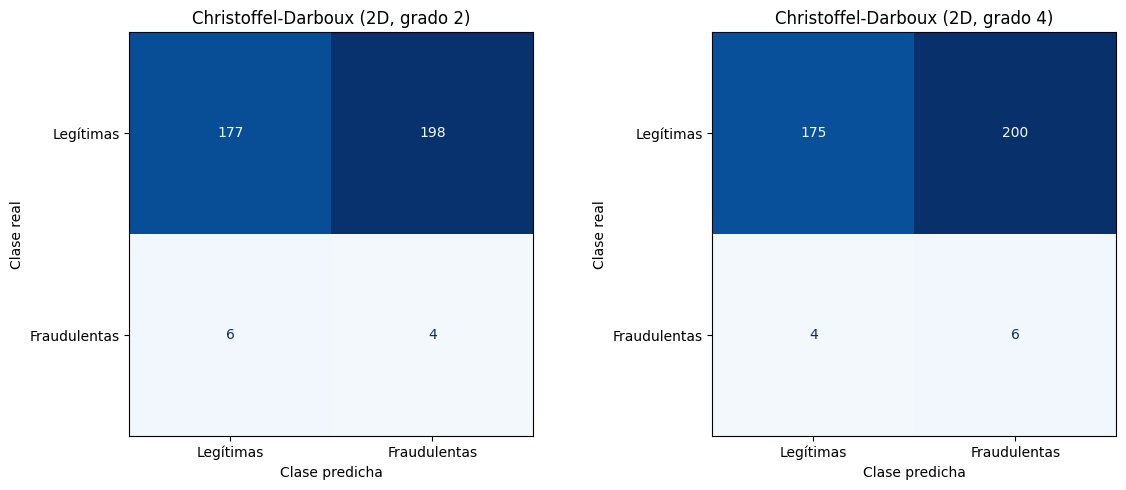

In [163]:
y_pred_cd_test_2d_g4 = (
    scores_cd_test_2d_g4 > umbral_optimo_cd_2d_g4
).astype(int)

cm_cd_test_2d_g4 = confusion_matrix(
    y_test,
    y_pred_cd_test_2d_g4,
    labels=[0, 1]
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

configuraciones = [
    (
        cm_cd_test_2d,
        "Christoffel-Darboux (2D, grado 2)"
    ),
    (
        cm_cd_test_2d_g4,
        "Christoffel-Darboux (2D, grado 4)"
    )
]

# Escala de color común
vmax = max(
    cm_cd_test_2d.max(),
    cm_cd_test_2d_g4.max()
)

for ax, (cm, titulo) in zip(
    axes,
    configuraciones
):

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Legítimas",
            "Fraudulentas"
        ]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        im_kw={
            "vmin": 0,
            "vmax": vmax
        }
    )

    ax.set_title(titulo)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

#### 6.10. Generalización de Christoffel-Darboux a espacios multidimensionales
Se generaliza el kernel de Christoffel-Darboux
a espacios de 5, 7 y 10 componentes principales,
utilizando transformaciones polinomiales de
grado 2 y 4.

Se analiza el crecimiento combinatorio del espacio
polinomial, la estabilidad numérica de la matriz
de momentos, el costo computacional y la capacidad
de detección de transacciones fraudulentas.

In [164]:
from math import comb

componentes_experimentos = [2, 5, 7, 10]
grados_experimentos = [2, 4]

N_legit = len(X_legit_2d)

resultados_dimensiones = []

for k in componentes_experimentos:

    for g in grados_experimentos:

        m = comb(k + g, g)

        resultados_dimensiones.append({
            "componentes": k,
            "grado": g,
            "monomios": m,
            "observaciones_legitimas": N_legit,
            "elementos_D": N_legit * m,
            "elementos_M": m**2,
            "memoria_D_MB": N_legit * m * 8 / 1024**2,
            "memoria_M_MB": m**2 * 8 / 1024**2,
            "observaciones_por_monomio": N_legit / m,
            "varianza_explicada_pct": (
                pca.explained_variance_ratio_[:k].sum()
                * 100
            )
        })

df_dimensiones_cd = pd.DataFrame(
    resultados_dimensiones
)

display(df_dimensiones_cd.round(4))

,componentes,grado,monomios,observaciones_legitimas,elementos_D,elementos_M,memoria_D_MB,memoria_M_MB,observaciones_por_monomio,varianza_explicada_pct
0,2,2,6,1494,8964,36,0.0684,0.0003,249.0000,22.0204
1,2,4,15,1494,22410,225,0.1710,0.0017,99.6000,22.0204
2,5,2,21,1494,31374,441,0.2394,0.0034,71.1429,44.5802
3,5,4,126,1494,188244,15876,1.4362,0.1211,11.8571,44.5802
4,7,2,36,1494,53784,1296,0.4103,0.0099,41.5000,53.7863
5,7,4,330,1494,493020,108900,3.7614,0.8308,4.5273,53.7863
6,10,2,66,1494,98604,4356,0.7523,0.0332,22.6364,66.9230
7,10,4,1001,1494,1495494,1002001,11.4097,7.6447,1.4925,66.9230


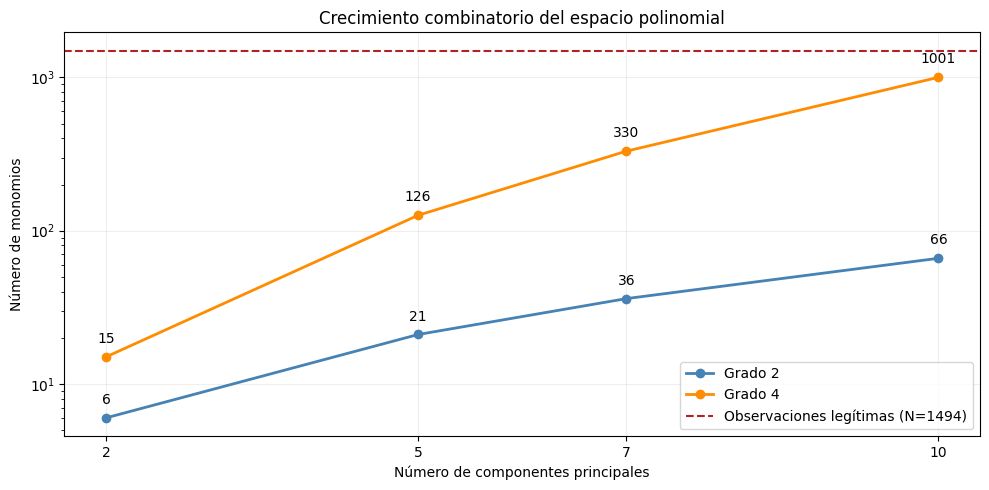

In [165]:
# Visualización del crecimiento
fig, ax = plt.subplots(figsize=(10, 5))

for grado, color in [
    (2, "steelblue"),
    (4, "darkorange")
]:

    datos = df_dimensiones_cd[
        df_dimensiones_cd["grado"] == grado
    ]

    ax.plot(
        datos["componentes"],
        datos["monomios"],
        marker="o",
        linewidth=2,
        color=color,
        label=f"Grado {grado}"
    )

    for _, fila in datos.iterrows():

        ax.annotate(
            f"{int(fila['monomios'])}",
            (
                fila["componentes"],
                fila["monomios"]
            ),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

ax.axhline(
    N_legit,
    color="firebrick",
    linestyle="--",
    label=f"Observaciones legítimas (N={N_legit})"
)

ax.set_title(
    "Crecimiento combinatorio del espacio polinomial"
)

ax.set_xlabel("Número de componentes principales")
ax.set_ylabel("Número de monomios")

ax.set_xticks(componentes_experimentos)
ax.set_yscale("log")

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [166]:
def ajustar_modelo_cd(
    X_legit,
    grado=2,
    epsilon=1e-6
):
    """
    Ajusta un modelo Christoffel-Darboux
    sobre observaciones legítimas.
    """

    X_legit = np.asarray(
        X_legit,
        dtype=np.float64
    )

    N, k = X_legit.shape

    inicio = perf_counter()

    # 1. Transformación polinomial
    poly = PolynomialFeatures(
        degree=grado,
        include_bias=True
    )

    D = poly.fit_transform(X_legit)

    m = D.shape[1]

    # 2. Matriz de momentos
    M = (D.T @ D) / N

    # 3. Regularización de Tikhonov
    M_reg = M + epsilon * np.eye(m)

    # 4. Factorización de Cholesky
    L = np.linalg.cholesky(M_reg)

    tiempo_ajuste = perf_counter() - inicio

    # 5. Diagnóstico numérico
    eig_original = np.linalg.eigvalsh(M)
    eig_reg = np.linalg.eigvalsh(M_reg)

    condicion_original = (
        eig_original.max() / eig_original.min()
        if eig_original.min() > 0
        else np.inf
    )

    condicion_reg = (
        eig_reg.max() / eig_reg.min()
        if eig_reg.min() > 0
        else np.inf
    )

    return {
        "poly": poly,
        "M": M,
        "M_reg": M_reg,
        "L": L,
        "grado": grado,
        "componentes": k,
        "monomios": m,
        "observaciones": N,
        "epsilon": epsilon,
        "condicion_original": condicion_original,
        "condicion_regularizada": condicion_reg,
        "valor_propio_minimo": eig_reg.min(),
        "definida_positiva": np.all(eig_reg > 0),
        "tiempo_ajuste_s": tiempo_ajuste
    }

In [167]:
modelo_cd_validacion = ajustar_modelo_cd(
    X_legit_2d,
    grado=2,
    epsilon=1e-6
)

scores_cd_validacion = calcular_score_cd(
    X_legit_2d,
    modelo_cd_validacion["poly"],
    modelo_cd_validacion["L"]
)

print("Validación de la función generalizada\n")

print(
    "Número de monomios:",
    modelo_cd_validacion["monomios"]
)

print(
    "Coincidencia de matrices de momentos:",
    np.allclose(
        modelo_cd_validacion["M"],
        M_2d_g4
    ) if modelo_cd_validacion["M"].shape
    == M_2d_g4.shape else
    "No aplica: grados diferentes"
)

print(
    "Coincidencia de scores:",
    np.allclose(
        scores_cd_validacion,
        scores_cd_legit_2d
    )
)

print(
    "Diferencia absoluta máxima:",
    np.max(
        np.abs(
            scores_cd_validacion
            - scores_cd_legit_2d
        )
    )
)

print(
    "Matriz definida positiva:",
    modelo_cd_validacion["definida_positiva"]
)

Validación de la función generalizada

Número de monomios: 6
Coincidencia de matrices de momentos: No aplica: grados diferentes
Coincidencia de scores: True
Diferencia absoluta máxima: 0.0
Matriz definida positiva: True


In [168]:
modelo_cd_validacion_g4 = ajustar_modelo_cd(
    X_legit_2d,
    grado=4,
    epsilon=1e-6
)

scores_cd_validacion_g4 = calcular_score_cd(
    X_legit_2d,
    modelo_cd_validacion_g4["poly"],
    modelo_cd_validacion_g4["L"]
)

print("Validación del modelo de grado cuatro\n")

print(
    "Número de monomios:",
    modelo_cd_validacion_g4["monomios"]
)

print(
    "Coincidencia de matrices de momentos:",
    np.allclose(
        modelo_cd_validacion_g4["M"],
        M_2d_g4
    )
)

print(
    "Coincidencia de matrices regularizadas:",
    np.allclose(
        modelo_cd_validacion_g4["M_reg"],
        M_reg_2d_g4
    )
)

print(
    "Coincidencia de scores:",
    np.allclose(
        scores_cd_validacion_g4,
        scores_cd_legit_2d_g4
    )
)

Validación del modelo de grado cuatro

Número de monomios: 15
Coincidencia de matrices de momentos: True
Coincidencia de matrices regularizadas: True
Coincidencia de scores: True


In [169]:
# Automatización de los experimentos
def calibrar_modelo_cd(
    scores_legit,
    scores_fraud,
    percentiles=(50, 75, 90, 95, 99)
):
    """
    Calcula los umbrales empíricos y selecciona
    el mejor mediante el F1-score de entrenamiento.
    """

    N = len(scores_legit)

    scores_ordenados = np.sort(scores_legit)

    scores_train = np.concatenate([
        scores_legit,
        scores_fraud
    ])

    y_train_cd = np.concatenate([
        np.zeros(len(scores_legit), dtype=int),
        np.ones(len(scores_fraud), dtype=int)
    ])

    umbrales = {}
    resultados = []

    for n in percentiles:

        indice = int(np.ceil(N * n / 100)) - 1

        rho = scores_ordenados[indice]

        umbrales[n] = rho

        cobertura = np.mean(
            scores_legit <= rho
        ) * 100

        metricas = evaluar_detector(
            y_train_cd,
            scores_train,
            rho
        )

        resultados.append({
            "percentil": n,
            "radio": rho,
            "cobertura_legit_pct": cobertura,
            "cumple_condicion": n <= cobertura < n + 1,
            **metricas
        })

    df_evaluacion = pd.DataFrame(resultados)

    mejor = (
        df_evaluacion
        .sort_values(
            ["f1_score", "recall"],
            ascending=[False, False]
        )
        .iloc[0]
    )

    return {
        "umbrales": umbrales,
        "df_evaluacion": df_evaluacion,
        "percentil_optimo": int(mejor["percentil"]),
        "umbral_optimo": float(mejor["radio"]),
        "metricas_train": mejor.to_dict()
    }

In [170]:
def ejecutar_experimento_cd(
    componentes,
    grado,
    epsilon=1e-6
):
    """
    Ejecuta un experimento completo de
    Christoffel-Darboux.
    """

    # 1. Selección de componentes principales
    X_train_k = X_train_pca[:, :componentes]
    X_test_k = X_test_pca[:, :componentes]

    y_train_array = np.asarray(y_train)
    y_test_array = np.asarray(y_test)

    X_legit_k = X_train_k[y_train_array == 0]
    X_fraud_k = X_train_k[y_train_array == 1]

    # 2. Ajuste del modelo
    modelo = ajustar_modelo_cd(
        X_legit_k,
        grado=grado,
        epsilon=epsilon
    )

    # 3. Puntuaciones de entrenamiento
    inicio = perf_counter()

    scores_legit = calcular_score_cd(
        X_legit_k,
        modelo["poly"],
        modelo["L"]
    )

    scores_fraud = calcular_score_cd(
        X_fraud_k,
        modelo["poly"],
        modelo["L"]
    )

    # Validaciones numéricas
    assert np.isfinite(scores_legit).all()
    assert np.isfinite(scores_fraud).all()

    assert np.all(scores_legit > 0)
    assert np.all(scores_fraud > 0)

    # 4. Calibración de umbrales
    calibracion = calibrar_modelo_cd(
        scores_legit,
        scores_fraud
    )

    tiempo_calibracion = perf_counter() - inicio

    umbral = calibracion["umbral_optimo"]

    # 5. Inferencia sobre prueba
    inicio = perf_counter()

    scores_test = calcular_score_cd(
        X_test_k,
        modelo["poly"],
        modelo["L"]
    )

    tiempo_inferencia = perf_counter() - inicio

    assert np.isfinite(scores_test).all()
    assert np.all(scores_test > 0)

    # 6. Evaluación sobre prueba
    metricas_test = evaluar_detector(
        y_test_array,
        scores_test,
        umbral
    )

    auc_test = roc_auc_score(
        y_test_array,
        scores_test
    )

    # 7. Evaluación ROC-AUC de entrenamiento
    auc_train = roc_auc_score(
        np.concatenate([
            np.zeros(len(scores_legit), dtype=int),
            np.ones(len(scores_fraud), dtype=int)
        ]),
        np.concatenate([
            scores_legit,
            scores_fraud
        ])
    )

    # 8. Matriz de confusión
    y_pred = (scores_test > umbral).astype(int)

    cm = confusion_matrix(
        y_test_array,
        y_pred,
        labels=[0, 1]
    )

    # 9. Resumen del experimento
    resultado = {
        "metodo": "Christoffel-Darboux",
        "componentes": componentes,
        "grado": grado,
        "monomios": modelo["monomios"],

        "varianza_explicada_pct": (
            pca.explained_variance_ratio_[
                :componentes
            ].sum() * 100
        ),

        "percentil": calibracion["percentil_optimo"],
        "radio": umbral,

        **metricas_test,

        "roc_auc": auc_test,

        "f1_train": (
            calibracion["metricas_train"]["f1_score"]
        ),

        "roc_auc_train": auc_train,

        "condicion_original": (
            modelo["condicion_original"]
        ),

        "condicion_regularizada": (
            modelo["condicion_regularizada"]
        ),

        "valor_propio_minimo": (
            modelo["valor_propio_minimo"]
        ),

        "definida_positiva": (
            modelo["definida_positiva"]
        ),

        "tiempo_ajuste_s": modelo["tiempo_ajuste_s"],
        "tiempo_calibracion_s": tiempo_calibracion,
        "tiempo_inferencia_s": tiempo_inferencia,

        "tiempo_total_s": (
            modelo["tiempo_ajuste_s"]
            + tiempo_calibracion
            + tiempo_inferencia
        )
    }

    return {
        "resultado": resultado,
        "modelo": modelo,
        "calibracion": calibracion,
        "scores_legit": scores_legit,
        "scores_fraud": scores_fraud,
        "scores_test": scores_test,
        "y_pred": y_pred,
        "matriz_confusion": cm
    }

In [171]:
experimento_validacion_cd = ejecutar_experimento_cd(
    componentes=2,
    grado=2
)

df_validacion_cd = pd.DataFrame([
    experimento_validacion_cd["resultado"]
])

columnas_validacion = [
    "componentes",
    "grado",
    "monomios",
    "percentil",
    "radio",
    "TN",
    "FP",
    "FN",
    "TP",
    "precision",
    "recall",
    "f1_score",
    "roc_auc"
]

display(
    df_validacion_cd[columnas_validacion].round(6)
)

,componentes,grado,monomios,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,roc_auc
0,2,2,6,50,3.17489,177,198,6,4,0.019802,0.4,0.037736,0.464267


In [172]:
# Validación automática
columnas_comparar = [
    "radio",
    "TN",
    "FP",
    "FN",
    "TP",
    "precision",
    "recall",
    "f1_score",
    "roc_auc"
]

for columna in columnas_comparar:

    valor_original = df_resultado_cd_2d[
        columna
    ].iloc[0]

    valor_nuevo = df_validacion_cd[
        columna
    ].iloc[0]

    coincidencia = np.isclose(
        valor_original,
        valor_nuevo
    )

    print(f"{columna}: {coincidencia}")

radio: True
TN: True
FP: True
FN: True
TP: True
precision: True
recall: True
f1_score: True
roc_auc: True


In [173]:
# Ejecución de experimentos
experimentos_cd = {}

resultados_cd = []

componentes_experimentos = [2, 5, 7, 10]
grados_experimentos = [2, 4]

inicio_experimentos = perf_counter()

for k in componentes_experimentos:

    for g in grados_experimentos:

        print(
            f"Ejecutando Christoffel-Darboux: "
            f"{k}D, grado {g}..."
        )

        experimento = ejecutar_experimento_cd(
            componentes=k,
            grado=g,
            epsilon=1e-6
        )

        # Almacenamiento del experimento completo
        experimentos_cd[(k, g)] = experimento

        # Almacenamiento del resumen
        resultados_cd.append(
            experimento["resultado"]
        )

        print(
            f"  Monomios: "
            f"{experimento['resultado']['monomios']}"
        )

        print(
            f"  F1-score: "
            f"{experimento['resultado']['f1_score']:.4f}"
        )

        print(
            f"  ROC-AUC: "
            f"{experimento['resultado']['roc_auc']:.4f}"
        )

        print(
            f"  Tiempo total: "
            f"{experimento['resultado']['tiempo_total_s']:.6f} s"
        )

        print("-" * 50)

tiempo_experimentos = (
    perf_counter() - inicio_experimentos
)

df_resultados_cd = pd.DataFrame(resultados_cd)

print(
    f"\nExperimentos realizados: "
    f"{len(df_resultados_cd)}"
)

print(
    f"Tiempo global de ejecución: "
    f"{tiempo_experimentos:.4f} s"
)

Ejecutando Christoffel-Darboux: 2D, grado 2...
  Monomios: 6
  F1-score: 0.0377
  ROC-AUC: 0.4643
  Tiempo total: 0.022652 s
--------------------------------------------------
Ejecutando Christoffel-Darboux: 2D, grado 4...
  Monomios: 15
  F1-score: 0.0556
  ROC-AUC: 0.4488
  Tiempo total: 0.019950 s
--------------------------------------------------
Ejecutando Christoffel-Darboux: 5D, grado 2...
  Monomios: 21
  F1-score: 0.0597
  ROC-AUC: 0.5187
  Tiempo total: 0.021490 s
--------------------------------------------------
Ejecutando Christoffel-Darboux: 5D, grado 4...
  Monomios: 126
  F1-score: 0.0000
  ROC-AUC: 0.5781
  Tiempo total: 0.023144 s
--------------------------------------------------
Ejecutando Christoffel-Darboux: 7D, grado 2...
  Monomios: 36
  F1-score: 0.0392
  ROC-AUC: 0.5027
  Tiempo total: 0.021270 s
--------------------------------------------------
Ejecutando Christoffel-Darboux: 7D, grado 4...
  Monomios: 330
  F1-score: 0.1034
  ROC-AUC: 0.5912
  Tiempo total:

In [174]:
# Resultados de clasificación
columnas_clasificacion = [
    "componentes",
    "grado",
    "monomios",
    "varianza_explicada_pct",
    "percentil",
    "TN",
    "FP",
    "FN",
    "TP",
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "balanced_accuracy",
    "roc_auc"
]

display(
    df_resultados_cd[
        columnas_clasificacion
    ].round(4)
)

,componentes,grado,monomios,varianza_explicada_pct,percentil,TN,FP,FN,TP,precision,recall,f1_score,fpr,balanced_accuracy,roc_auc
0,2,2,6,22.0204,50,177,198,6,4,0.0198,0.4,0.0377,0.5280,0.4360,0.4643
1,2,4,15,22.0204,50,175,200,4,6,0.0291,0.6,0.0556,0.5333,0.5333,0.4488
2,5,2,21,44.5802,50,190,185,4,6,0.0314,0.6,0.0597,0.4933,0.5533,0.5187
3,5,4,126,44.5802,99,364,11,10,0,0.0000,0.0,0.0000,0.0293,0.4853,0.5781
4,7,2,36,53.7863,75,285,90,8,2,0.0217,0.2,0.0392,0.2400,0.4800,0.5027
5,7,4,330,53.7863,99,330,45,7,3,0.0625,0.3,0.1034,0.1200,0.5900,0.5912
6,10,2,66,66.9230,95,357,18,9,1,0.0526,0.1,0.0690,0.0480,0.5260,0.6232
7,10,4,1001,66.9230,99,116,259,2,8,0.0300,0.8,0.0578,0.6907,0.5547,0.6749


In [175]:
# Resultados de estabilidad numérica
columnas_estabilidad = [
    "componentes",
    "grado",
    "monomios",
    "condicion_original",
    "condicion_regularizada",
    "valor_propio_minimo",
    "definida_positiva"
]

display(
    df_resultados_cd[
        columnas_estabilidad
    ].style.format({
        "condicion_original": "{:.4e}",
        "condicion_regularizada": "{:.4e}",
        "valor_propio_minimo": "{:.4e}"
    })
)

,componentes,grado,monomios,condicion_original,condicion_regularizada,valor_propio_minimo,definida_positiva
0,2,2,6,1.8844e+03,1.8844e+03,2.2059e-01,True
1,2,4,15,1.4222e+09,1.4222e+09,7.9749e-02,True
2,5,2,21,3.3289e+03,3.3289e+03,1.4093e-01,True
3,5,4,126,1.1214e+10,1.1213e+10,1.2211e-02,True
4,7,2,36,3.6898e+03,3.6897e+03,1.2757e-01,True
5,7,4,330,2.3232e+10,2.3228e+10,5.9168e-03,True
6,10,2,66,4.7621e+03,4.7620e+03,9.8929e-02,True
7,10,4,1001,2.5786e+11,2.5738e+11,5.3405e-04,True


In [176]:
# Resultados de rendimiento computacional
columnas_tiempos = [
    "componentes",
    "grado",
    "monomios",
    "tiempo_ajuste_s",
    "tiempo_calibracion_s",
    "tiempo_inferencia_s",
    "tiempo_total_s"
]

display(
    df_resultados_cd[
        columnas_tiempos
    ].round(6)
)

,componentes,grado,monomios,tiempo_ajuste_s,tiempo_calibracion_s,tiempo_inferencia_s,tiempo_total_s
0,2,2,6,0.000580,0.021789,0.000283,0.022652
1,2,4,15,0.000385,0.019254,0.000312,0.019950
2,5,2,21,0.000566,0.020596,0.000328,0.021490
3,5,4,126,0.001563,0.020931,0.000651,0.023144
4,7,2,36,0.000580,0.020286,0.000404,0.021270
5,7,4,330,0.004144,0.024162,0.001422,0.029728
6,10,2,66,0.000939,0.021420,0.000451,0.022810
7,10,4,1001,0.037699,0.059368,0.006206,0.103272


In [177]:
# Generalización del modelo
df_resultados_cd["brecha_f1"] = (
    df_resultados_cd["f1_train"]
    - df_resultados_cd["f1_score"]
)

df_resultados_cd["brecha_auc"] = (
    df_resultados_cd["roc_auc_train"]
    - df_resultados_cd["roc_auc"]
)

columnas_generalizacion = [
    "componentes",
    "grado",
    "monomios",
    "f1_train",
    "f1_score",
    "brecha_f1",
    "roc_auc_train",
    "roc_auc",
    "brecha_auc"
]

display(
    df_resultados_cd[
        columnas_generalizacion
    ].round(4)
)

,componentes,grado,monomios,f1_train,f1_score,brecha_f1,roc_auc_train,roc_auc,brecha_auc
0,2,2,6,0.0470,0.0377,0.0093,0.4372,0.4643,-0.0270
1,2,4,15,0.0422,0.0556,-0.0134,0.4450,0.4488,-0.0038
2,5,2,21,0.0446,0.0597,-0.0151,0.5158,0.5187,-0.0029
3,5,4,126,0.0690,0.0000,0.0690,0.5255,0.5781,-0.0527
4,7,2,36,0.0653,0.0392,0.0261,0.5534,0.5027,0.0508
5,7,4,330,0.1935,0.1034,0.0901,0.6042,0.5912,0.0130
6,10,2,66,0.0826,0.0690,0.0137,0.5689,0.6232,-0.0543
7,10,4,1001,0.7273,0.0578,0.6695,0.8066,0.6749,0.1317


###  Análisis comparativo de los experimentos
Se analiza el impacto de la dimensionalidad y del grado
polinomial sobre el desempeño del kernel de
Christoffel-Darboux.

La comparación considera:

- Capacidad de detección de fraudes.
- Capacidad de discriminación entre clases.
- Generalización del modelo.
- Estabilidad numérica.
- Costo computacional.

El objetivo es identificar los compromisos existentes
entre complejidad matemática y desempeño predictivo.

In [178]:
def graficar_comparacion_cd(
    metrica,
    titulo,
    ylabel,
    escala_log=False,
    referencia=None
):
    fig, ax = plt.subplots(figsize=(10, 5))

    colores = {
        2: "steelblue",
        4: "firebrick"
    }

    for grado in [2, 4]:

        datos = (
            df_resultados_cd[
                df_resultados_cd["grado"] == grado
            ]
            .sort_values("componentes")
        )

        ax.plot(
            datos["componentes"],
            datos[metrica],
            marker="o",
            linewidth=2,
            markersize=7,
            color=colores[grado],
            label=f"Grado {grado}"
        )

    if referencia is not None:
        ax.axhline(
            referencia,
            color="black",
            linestyle="--",
            label=f"Referencia ({referencia})"
        )

    if escala_log:
        ax.set_yscale("log")

    ax.set_title(titulo)
    ax.set_xlabel("Componentes principales")
    ax.set_ylabel(ylabel)
    ax.set_xticks([2, 5, 7, 10])

    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

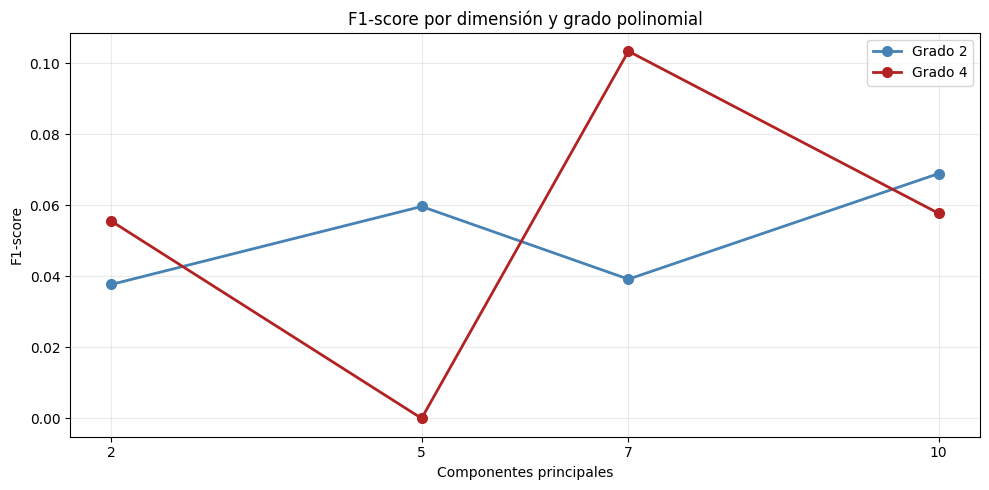

In [179]:
graficar_comparacion_cd(
    metrica="f1_score",
    titulo="F1-score por dimensión y grado polinomial",
    ylabel="F1-score"
)

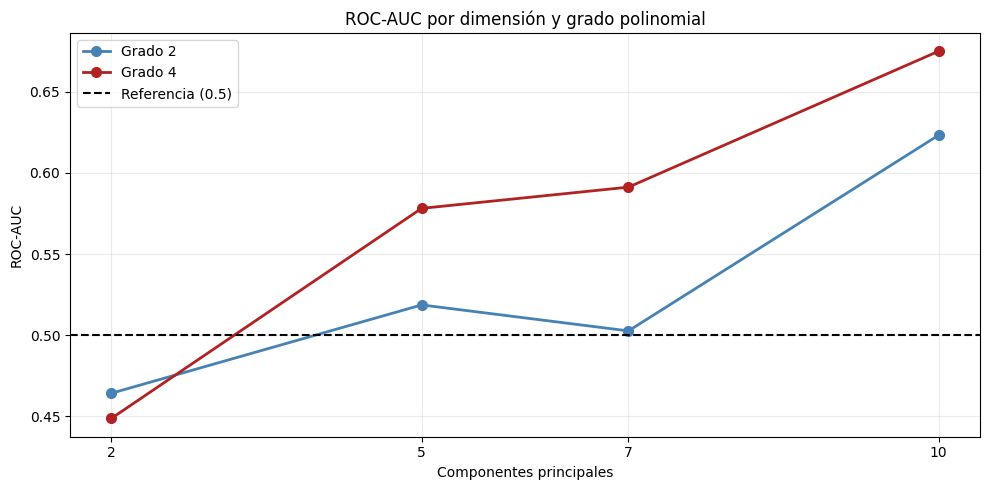

In [180]:
graficar_comparacion_cd(
    metrica="roc_auc",
    titulo="ROC-AUC por dimensión y grado polinomial",
    ylabel="ROC-AUC",
    referencia=0.5
)

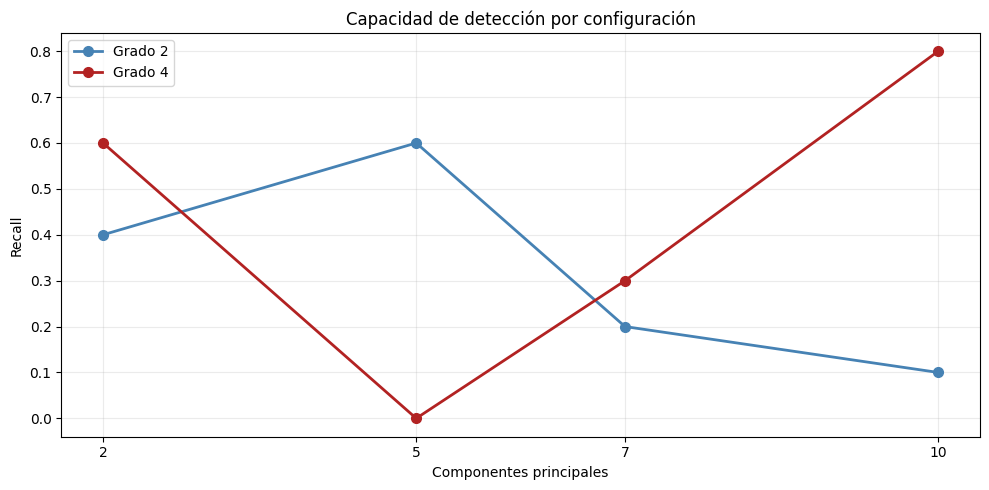

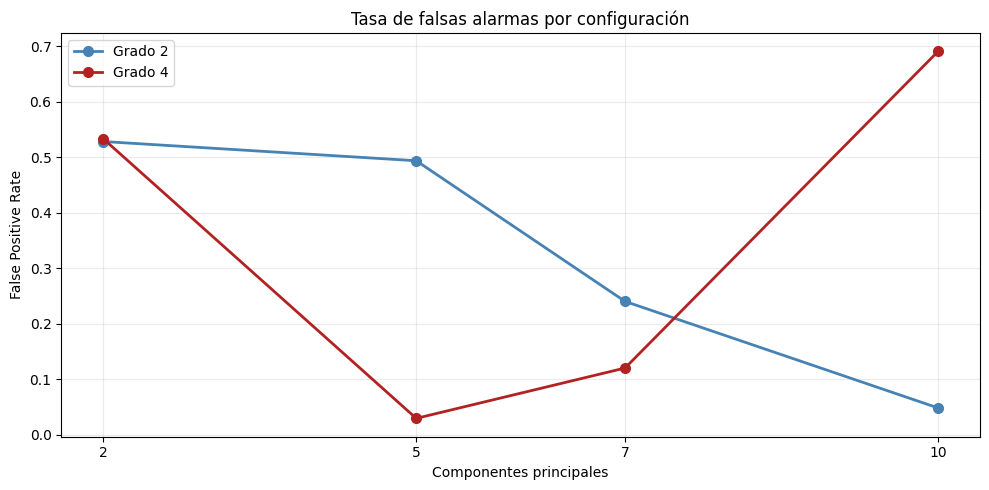

In [181]:
graficar_comparacion_cd(
    metrica="recall",
    titulo="Capacidad de detección por configuración",
    ylabel="Recall"
)

graficar_comparacion_cd(
    metrica="fpr",
    titulo="Tasa de falsas alarmas por configuración",
    ylabel="False Positive Rate"
)

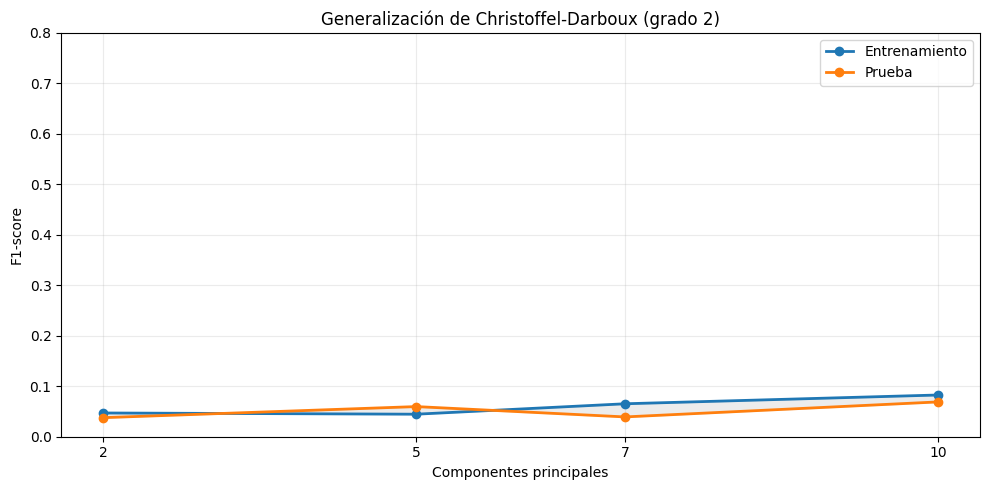

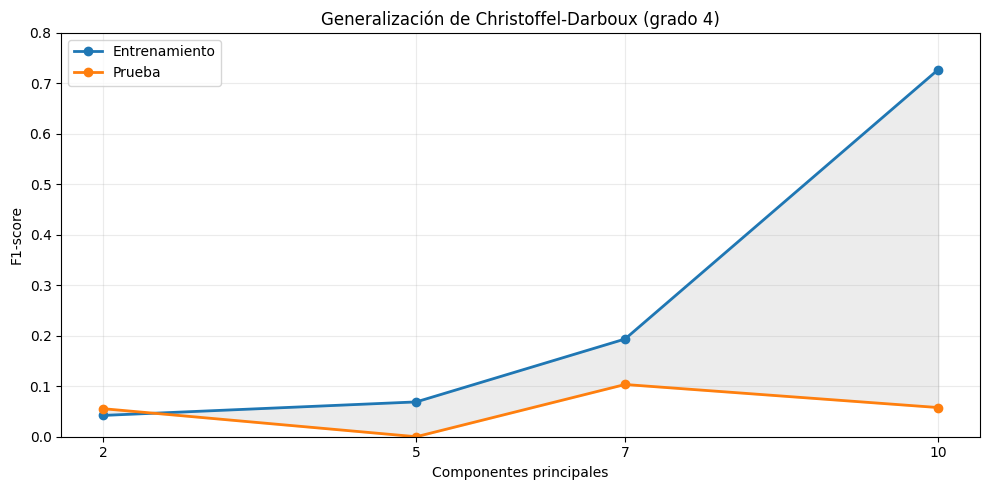

In [182]:
# Análisis de generalización
for grado in [2, 4]:

    datos = (
        df_resultados_cd[
            df_resultados_cd["grado"] == grado
        ]
        .sort_values("componentes")
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        datos["componentes"],
        datos["f1_train"],
        marker="o",
        linewidth=2,
        label="Entrenamiento"
    )

    ax.plot(
        datos["componentes"],
        datos["f1_score"],
        marker="o",
        linewidth=2,
        label="Prueba"
    )

    ax.fill_between(
        datos["componentes"],
        datos["f1_train"],
        datos["f1_score"],
        alpha=0.15,
        color="gray"
    )

    ax.set_title(
        f"Generalización de Christoffel-Darboux "
        f"(grado {grado})"
    )

    ax.set_xlabel("Componentes principales")
    ax.set_ylabel("F1-score")
    ax.set_xticks([2, 5, 7, 10])
    ax.set_ylim(0, 0.8)

    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

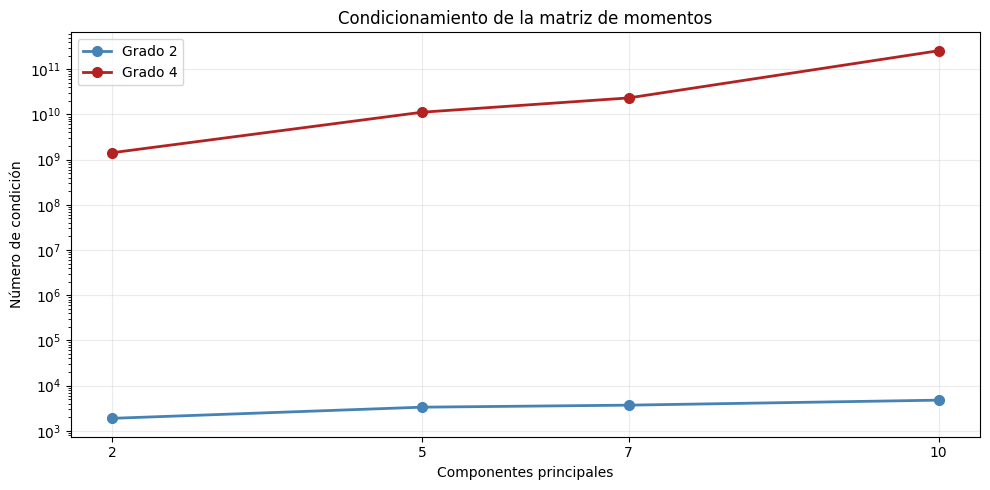

In [183]:
# Análisis de estabilidad numérica
graficar_comparacion_cd(
    metrica="condicion_regularizada",
    titulo="Condicionamiento de la matriz de momentos",
    ylabel="Número de condición",
    escala_log=True
)

In [184]:
# Efectividad de la regularización
df_resultados_cd["reduccion_condicion_pct"] = (
    1 - (
        df_resultados_cd["condicion_regularizada"]
        / df_resultados_cd["condicion_original"]
    )
) * 100

columnas_regularizacion = [
    "componentes",
    "grado",
    "condicion_original",
    "condicion_regularizada",
    "reduccion_condicion_pct",
    "valor_propio_minimo",
    "definida_positiva"
]

display(
    df_resultados_cd[
        columnas_regularizacion
    ].style.format({
        "condicion_original": "{:.6e}",
        "condicion_regularizada": "{:.6e}",
        "reduccion_condicion_pct": "{:.6f}",
        "valor_propio_minimo": "{:.6e}"
    })
)

,componentes,grado,condicion_original,condicion_regularizada,reduccion_condicion_pct,valor_propio_minimo,definida_positiva
0,2,2,1.884449e+03,1.884440e+03,0.000453,2.205893e-01,True
1,2,4,1.422185e+09,1.422167e+09,0.001254,7.974916e-02,True
2,5,2,3.328891e+03,3.328867e+03,0.000709,1.409317e-01,True
3,5,4,1.121396e+10,1.121304e+10,0.008199,1.221122e-02,True
4,7,2,3.689765e+03,3.689736e+03,0.000784,1.275688e-01,True
5,7,4,2.323179e+10,2.322785e+10,0.016937,5.916775e-03,True
6,10,2,4.762064e+03,4.762016e+03,0.001011,9.892917e-02,True
7,10,4,2.578585e+11,2.573751e+11,0.187438,5.340459e-04,True


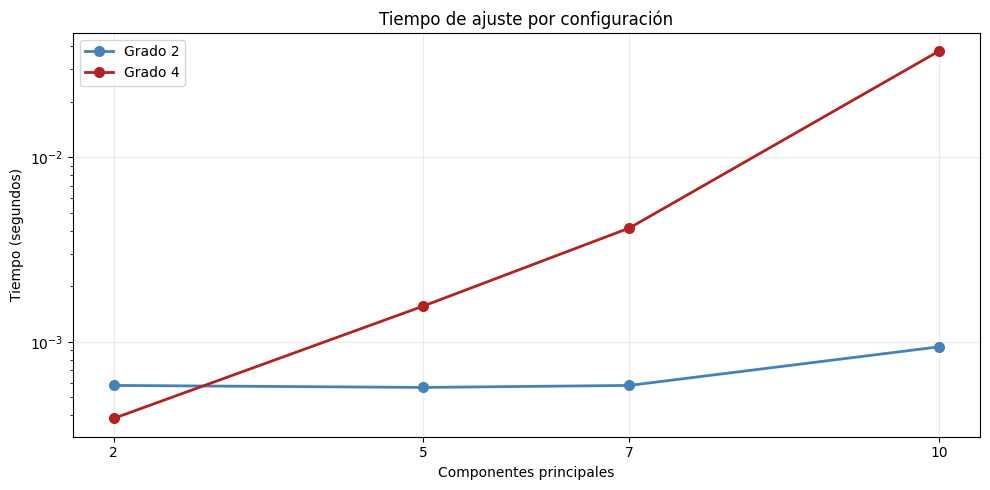

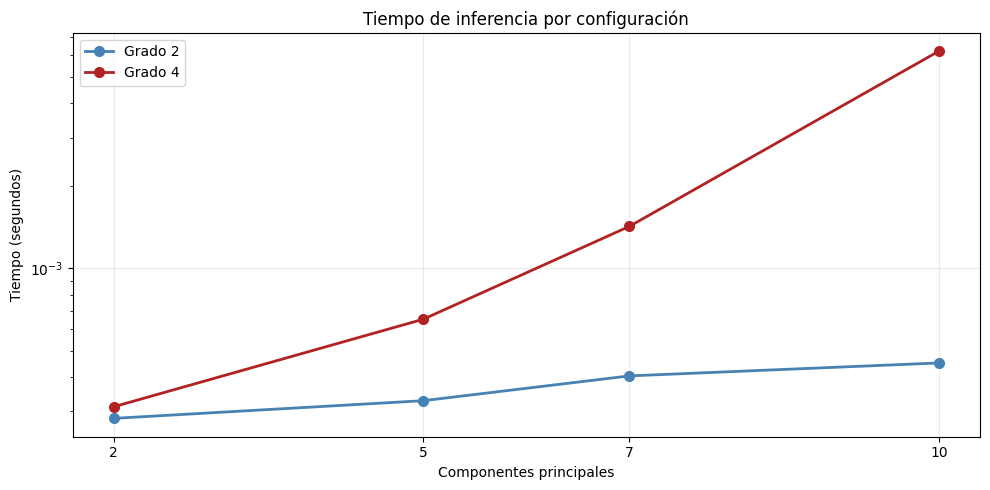

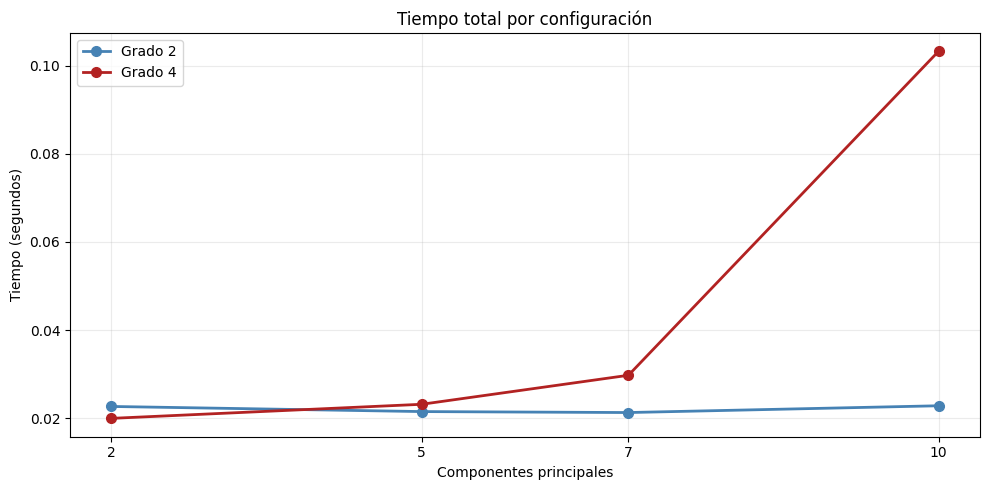

In [185]:
# Análisis del costo computacional
graficar_comparacion_cd(
    metrica="tiempo_ajuste_s",
    titulo="Tiempo de ajuste por configuración",
    ylabel="Tiempo (segundos)",
    escala_log=True
)

graficar_comparacion_cd(
    metrica="tiempo_inferencia_s",
    titulo="Tiempo de inferencia por configuración",
    ylabel="Tiempo (segundos)",
    escala_log=True
)

graficar_comparacion_cd(
    metrica="tiempo_total_s",
    titulo="Tiempo total por configuración",
    ylabel="Tiempo (segundos)"
)

### Conclusiones de los experimentos multidimensionales

El incremento del número de componentes principales
permite conservar una mayor proporción de la varianza
original de los datos, pasando del 22.02% en dos
dimensiones al 66.92% en diez dimensiones.

La configuración de diez dimensiones y grado cuatro
obtuvo el mayor ROC-AUC en prueba (0.6749), lo que
sugiere una mejor capacidad de discriminación entre
transacciones legítimas y fraudulentas.

Sin embargo, esta configuración presentó una brecha
considerable entre el F1-score de entrenamiento
(0.7273) y el de prueba (0.0578), además de una tasa
de falsas alarmas del 69.07%.

El incremento de la complejidad polinomial también
produjo un deterioro considerable del condicionamiento
de la matriz de momentos, a pesar de que todas las
matrices regularizadas fueron definidas positivas.

La configuración de siete dimensiones y grado cuatro
obtuvo el mayor F1-score observado en prueba (0.1034),
aunque su capacidad de detección continúa siendo
limitada.

En consecuencia, una mayor dimensionalidad y un mayor
grado polinomial no garantizan una mejor capacidad de
generalización.

Los resultados deben interpretarse considerando que
el conjunto de prueba contiene únicamente diez
transacciones fraudulentas.

---

### Fase 7. Comparación integral de Mahalanobis y Christoffel-Darboux
En esta sección se realiza una evaluación comparativa
entre la distancia de Mahalanobis y el kernel de
Christoffel-Darboux.

Todos los experimentos utilizan la misma partición
de entrenamiento y prueba, así como las componentes
principales obtenidas durante el preprocesamiento.

#### 7.1. Integración de resultados experimentales

Se concentran los resultados de los diez experimentos
en una estructura tabular común para facilitar su
comparación en términos de:

- Varianza explicada.
- Complejidad matemática.
- Capacidad de detección.
- Tasa de falsas alarmas.
- Capacidad de discriminación.
- Rendimiento computacional.


In [189]:
df_maha_final = df_comparativa_maha.copy()

df_maha_final["metodo"] = "Mahalanobis"

# No aplica expansión polinomial
df_maha_final["grado"] = pd.NA
df_maha_final["monomios"] = pd.NA

# Dimensión de la matriz de covarianza
df_maha_final["dimension_matriz"] = (
    df_maha_final["componentes"]
)

# Calcular especificidad
df_maha_final["specificity"] = (
    df_maha_final["TN"]
    / (df_maha_final["TN"] + df_maha_final["FP"])
)

display(df_maha_final)

,metodo,componentes,varianza_explicada_pct,percentil,radio,tiempo_inferencia_s,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy,grado,monomios,dimension_matriz
0,Mahalanobis,2,22.020426,50.0,1.022705,0.000237,174,201,6,4,0.019512,0.4,0.037209,0.536000,0.464000,0.432000,<NA>,<NA>,2
1,Mahalanobis,10,66.923009,50.0,2.727340,0.000293,196,179,3,7,0.037634,0.7,0.071429,0.477333,0.522667,0.611333,<NA>,<NA>,10


In [190]:
df_cd_final = df_resultados_cd.copy()

df_cd_final["metodo"] = "Christoffel-Darboux"

# Dimensión de la matriz de momentos
df_cd_final["dimension_matriz"] = (
    df_cd_final["monomios"]
)

display(df_cd_final.head())

,metodo,componentes,grado,monomios,varianza_explicada_pct,percentil,radio,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy,roc_auc,f1_train,roc_auc_train,condicion_original,condicion_regularizada,valor_propio_minimo,definida_positiva,tiempo_ajuste_s,tiempo_calibracion_s,tiempo_inferencia_s,tiempo_total_s,brecha_f1,brecha_auc,reduccion_condicion_pct,dimension_matriz
0,Christoffel-Darboux,2,2,6,22.020426,50,3.174890,177,198,6,4,0.019802,0.4,0.037736,0.528000,0.472000,0.436000,0.464267,0.047030,0.437241,1.884449e+03,1.884440e+03,0.220589,True,0.000580,0.021789,0.000283,0.022652,0.009294,-0.027026,0.000453,6
1,Christoffel-Darboux,2,4,15,22.020426,50,5.730887,175,200,4,6,0.029126,0.6,0.055556,0.533333,0.466667,0.533333,0.448800,0.042184,0.445018,1.422185e+09,1.422167e+09,0.079749,True,0.000385,0.019254,0.000312,0.019950,-0.013372,-0.003782,0.001254,15
2,Christoffel-Darboux,5,2,21,44.580174,50,9.167057,190,185,4,6,0.031414,0.6,0.059701,0.493333,0.506667,0.553333,0.518667,0.044610,0.515777,3.328891e+03,3.328867e+03,0.140932,True,0.000566,0.020596,0.000328,0.021490,-0.015092,-0.002889,0.000709,21
3,Christoffel-Darboux,5,4,126,44.580174,99,1432.838991,364,11,10,0,0.000000,0.0,0.000000,0.029333,0.970667,0.485333,0.578133,0.068966,0.525467,1.121396e+10,1.121304e+10,0.012211,True,0.001563,0.020931,0.000651,0.023144,0.068966,-0.052666,0.008199,126
4,Christoffel-Darboux,7,2,36,53.786340,75,33.380512,285,90,8,2,0.021739,0.2,0.039216,0.240000,0.760000,0.480000,0.502667,0.065268,0.553436,3.689765e+03,3.689736e+03,0.127569,True,0.000580,0.020286,0.000404,0.021270,0.026052,0.050769,0.000784,36


In [ ]:
# Integración de los resultados
df_comparacion_final = pd.concat(
    [
        df_maha_final,
        df_cd_final
    ],
    ignore_index=True,
    sort=False
)

# Identificador de cada configuración
df_comparacion_final["configuracion"] = (
    df_comparacion_final.apply(
        lambda fila: (
            f"Mahalanobis {int(fila['componentes'])}D"
            if fila["metodo"] == "Mahalanobis"
            else (
                f"CD {int(fila['componentes'])}D "
                f"G{int(fila['grado'])}"
            )
        ),
        axis=1
    )
)

display(df_comparacion_final)

,metodo,componentes,varianza_explicada_pct,percentil,radio,tiempo_inferencia_s,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy,grado,monomios,dimension_matriz,roc_auc,f1_train,roc_auc_train,condicion_original,condicion_regularizada,valor_propio_minimo,definida_positiva,tiempo_ajuste_s,tiempo_calibracion_s,tiempo_total_s,brecha_f1,brecha_auc,reduccion_condicion_pct,configuracion
0,Mahalanobis,2,22.020426,50.0,1.022705,0.000237,174,201,6,4,0.019512,0.4,0.037209,0.536000,0.464000,0.432000,<NA>,<NA>,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mahalanobis 2D
1,Mahalanobis,10,66.923009,50.0,2.727340,0.000293,196,179,3,7,0.037634,0.7,0.071429,0.477333,0.522667,0.611333,<NA>,<NA>,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mahalanobis 10D
2,Christoffel-Darboux,2,22.020426,50.0,3.174890,0.000283,177,198,6,4,0.019802,0.4,0.037736,0.528000,0.472000,0.436000,2,6,6,0.464267,0.047030,0.437241,1.884449e+03,1.884440e+03,0.220589,True,0.000580,0.021789,0.022652,0.009294,-0.027026,0.000453,CD 2D G2
3,Christoffel-Darboux,2,22.020426,50.0,5.730887,0.000312,175,200,4,6,0.029126,0.6,0.055556,0.533333,0.466667,0.533333,4,15,15,0.448800,0.042184,0.445018,1.422185e+09,1.422167e+09,0.079749,True,0.000385,0.019254,0.019950,-0.013372,-0.003782,0.001254,CD 2D G4
4,Christoffel-Darboux,5,44.580174,50.0,9.167057,0.000328,190,185,4,6,0.031414,0.6,0.059701,0.493333,0.506667,0.553333,2,21,21,0.518667,0.044610,0.515777,3.328891e+03,3.328867e+03,0.140932,True,0.000566,0.020596,0.021490,-0.015092,-0.002889,0.000709,CD 5D G2
5,Christoffel-Darboux,5,44.580174,99.0,1432.838991,0.000651,364,11,10,0,0.000000,0.0,0.000000,0.029333,0.970667,0.485333,4,126,126,0.578133,0.068966,0.525467,1.121396e+10,1.121304e+10,0.012211,True,0.001563,0.020931,0.023144,0.068966,-0.052666,0.008199,CD 5D G4
6,Christoffel-Darboux,7,53.786340,75.0,33.380512,0.000404,285,90,8,2,0.021739,0.2,0.039216,0.240000,0.760000,0.480000,2,36,36,0.502667,0.065268,0.553436,3.689765e+03,3.689736e+03,0.127569,True,0.000580,0.020286,0.021270,0.026052,0.050769,0.000784,CD 7D G2
7,Christoffel-Darboux,7,53.786340,99.0,1486.030182,0.001422,330,45,7,3,0.062500,0.3,0.103448,0.120000,0.880000,0.590000,4,330,330,0.591200,0.193548,0.604226,2.323179e+10,2.322785e+10,0.005917,True,0.004144,0.024162,0.029728,0.090100,0.013026,0.016937,CD 7D G4
8,Christoffel-Darboux,10,66.923009,95.0,200.932265,0.000451,357,18,9,1,0.052632,0.1,0.068966,0.048000,0.952000,0.526000,2,66,66,0.623200,0.082645,0.568942,4.762064e+03,4.762016e+03,0.098929,True,0.000939,0.021420,0.022810,0.013679,-0.054258,0.001011,CD 10D G2
9,Christoffel-Darboux,10,66.923009,99.0,1493.761896,0.006206,116,259,2,8,0.029963,0.8,0.057762,0.690667,0.309333,0.554667,4,1001,1001,0.674933,0.727273,0.806623,2.578585e+11,2.573751e+11,0.000534,True,0.037699,0.059368,0.103272,0.669511,0.131690,0.187438,CD 10D G4


In [192]:
# Tabla comparativa de clasificación
columnas_clasificacion = [
    "configuracion",
    "varianza_explicada_pct",
    "dimension_matriz",
    "percentil",
    "TN",
    "FP",
    "FN",
    "TP",
    "precision",
    "recall",
    "f1_score",
    "fpr",
    "specificity",
    "balanced_accuracy"
]

df_comparacion_clasificacion = (
    df_comparacion_final[
        columnas_clasificacion
    ].copy()
)

display(
    df_comparacion_clasificacion.round(4)
)

,configuracion,varianza_explicada_pct,dimension_matriz,percentil,TN,FP,FN,TP,precision,recall,f1_score,fpr,specificity,balanced_accuracy
0,Mahalanobis 2D,22.0204,2,50.0,174,201,6,4,0.0195,0.4,0.0372,0.5360,0.4640,0.4320
1,Mahalanobis 10D,66.9230,10,50.0,196,179,3,7,0.0376,0.7,0.0714,0.4773,0.5227,0.6113
2,CD 2D G2,22.0204,6,50.0,177,198,6,4,0.0198,0.4,0.0377,0.5280,0.4720,0.4360
3,CD 2D G4,22.0204,15,50.0,175,200,4,6,0.0291,0.6,0.0556,0.5333,0.4667,0.5333
4,CD 5D G2,44.5802,21,50.0,190,185,4,6,0.0314,0.6,0.0597,0.4933,0.5067,0.5533
5,CD 5D G4,44.5802,126,99.0,364,11,10,0,0.0000,0.0,0.0000,0.0293,0.9707,0.4853
6,CD 7D G2,53.7863,36,75.0,285,90,8,2,0.0217,0.2,0.0392,0.2400,0.7600,0.4800
7,CD 7D G4,53.7863,330,99.0,330,45,7,3,0.0625,0.3,0.1034,0.1200,0.8800,0.5900
8,CD 10D G2,66.9230,66,95.0,357,18,9,1,0.0526,0.1,0.0690,0.0480,0.9520,0.5260
9,CD 10D G4,66.9230,1001,99.0,116,259,2,8,0.0300,0.8,0.0578,0.6907,0.3093,0.5547


In [193]:
# Validación de la consistencia experimental
df_validacion_final = pd.DataFrame({
    "configuracion": (
        df_comparacion_final["configuracion"]
    ),
    "legitimas": (
        df_comparacion_final["TN"]
        + df_comparacion_final["FP"]
    ),
    "fraudulentas": (
        df_comparacion_final["TP"]
        + df_comparacion_final["FN"]
    )
})

df_validacion_final["total"] = (
    df_validacion_final["legitimas"]
    + df_validacion_final["fraudulentas"]
)

display(df_validacion_final)

,configuracion,legitimas,fraudulentas,total
0,Mahalanobis 2D,375,10,385
1,Mahalanobis 10D,375,10,385
2,CD 2D G2,375,10,385
3,CD 2D G4,375,10,385
4,CD 5D G2,375,10,385
5,CD 5D G4,375,10,385
6,CD 7D G2,375,10,385
7,CD 7D G4,375,10,385
8,CD 10D G2,375,10,385
9,CD 10D G4,375,10,385


## 7.2. Comparación de métricas de clasificación

Se comparan las configuraciones de Mahalanobis y
Christoffel-Darboux utilizando las métricas obtenidas
sobre el conjunto de prueba.

Debido al desbalance entre clases, se priorizan
precision, recall, F1-score y balanced accuracy
sobre la exactitud convencional.

También se analiza la tasa de falsos positivos
para identificar el costo operativo asociado
a la detección de transacciones fraudulentas.

In [194]:
def graficar_comparacion_final(
    metrica,
    titulo,
    xlabel,
    referencia=None
):
    datos = (
        df_comparacion_final
        .sort_values(metrica, ascending=True)
        .copy()
    )

    colores = {
        "Mahalanobis": "steelblue",
        "CD G2": "darkorange",
        "CD G4": "firebrick"
    }

    datos["grupo"] = datos.apply(
        lambda fila: (
            "Mahalanobis"
            if fila["metodo"] == "Mahalanobis"
            else f"CD G{int(fila['grado'])}"
        ),
        axis=1
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    barras = ax.barh(
        datos["configuracion"],
        datos[metrica],
        color=datos["grupo"].map(colores),
        alpha=0.85
    )

    ax.bar_label(
        barras,
        fmt="%.4f",
        padding=4
    )

    if referencia is not None:
        ax.axvline(
            referencia,
            color="black",
            linestyle="--",
            alpha=0.7,
            label=f"Referencia: {referencia}"
        )

    from matplotlib.patches import Patch

    leyenda = [
        Patch(color=color, label=grupo)
        for grupo, color in colores.items()
    ]

    handles, labels = ax.get_legend_handles_labels()

    ax.legend(
        handles=leyenda + handles,
        loc="lower right"
    )

    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Configuración")

    ax.margins(x=0.15)
    ax.grid(axis="x", alpha=0.25)

    plt.tight_layout()
    plt.show()

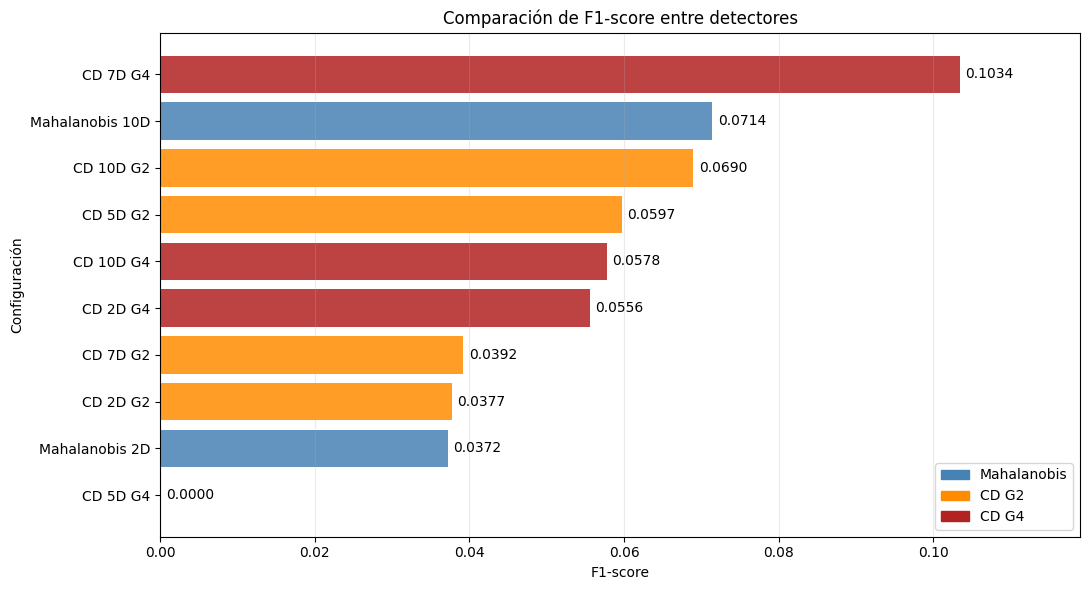

In [195]:
graficar_comparacion_final(
    metrica="f1_score",
    titulo="Comparación de F1-score entre detectores",
    xlabel="F1-score"
)

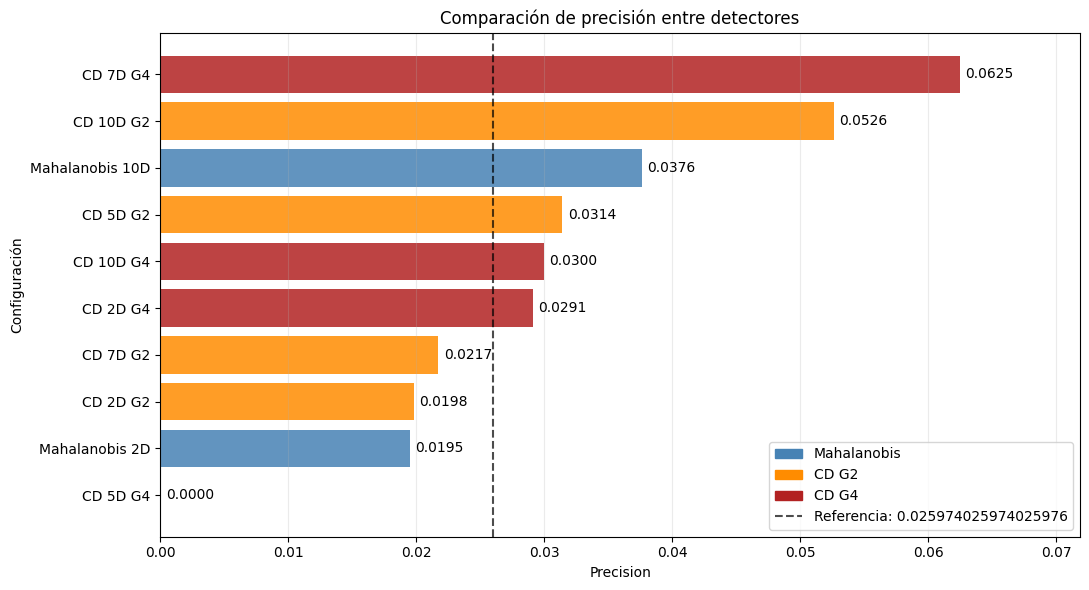

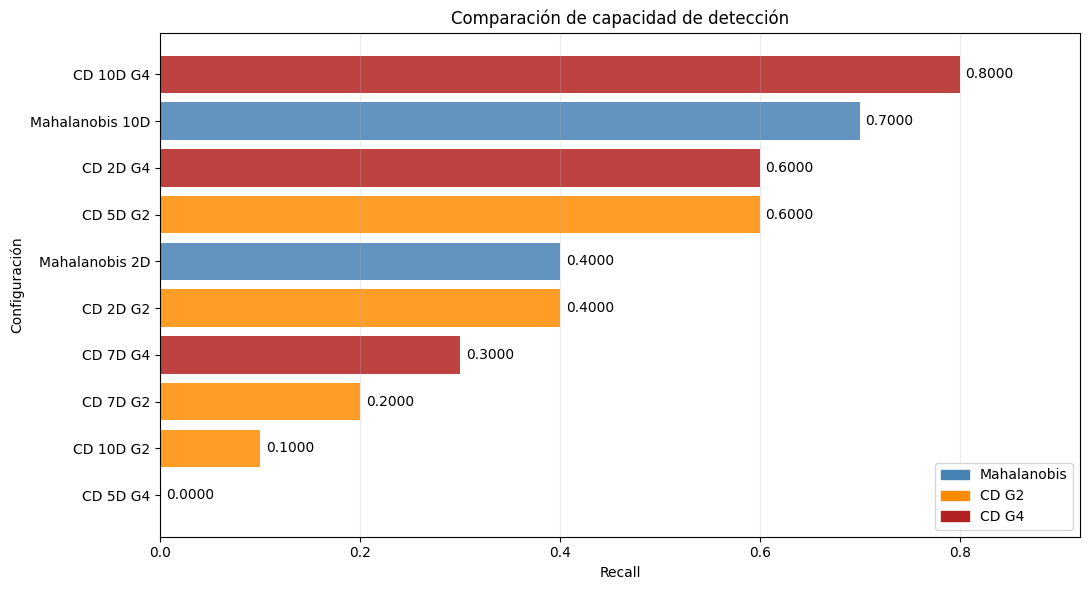

In [196]:
graficar_comparacion_final(
    metrica="precision",
    titulo="Comparación de precisión entre detectores",
    xlabel="Precision",
    referencia=np.mean(np.asarray(y_test) == 1)
)

graficar_comparacion_final(
    metrica="recall",
    titulo="Comparación de capacidad de detección",
    xlabel="Recall"
)

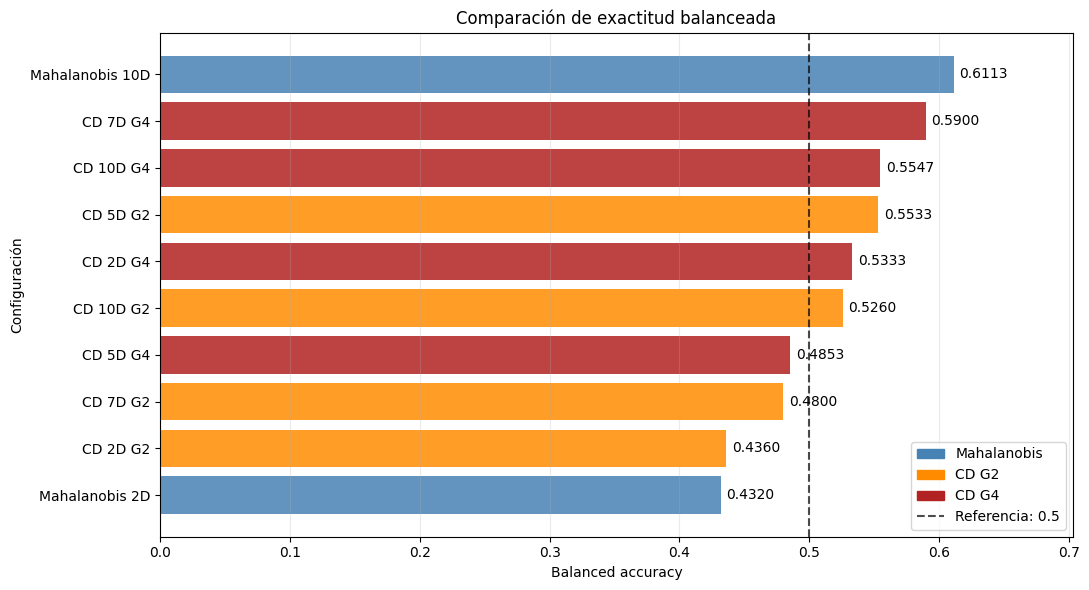

In [197]:
graficar_comparacion_final(
    metrica="balanced_accuracy",
    titulo="Comparación de exactitud balanceada",
    xlabel="Balanced accuracy",
    referencia=0.5
)

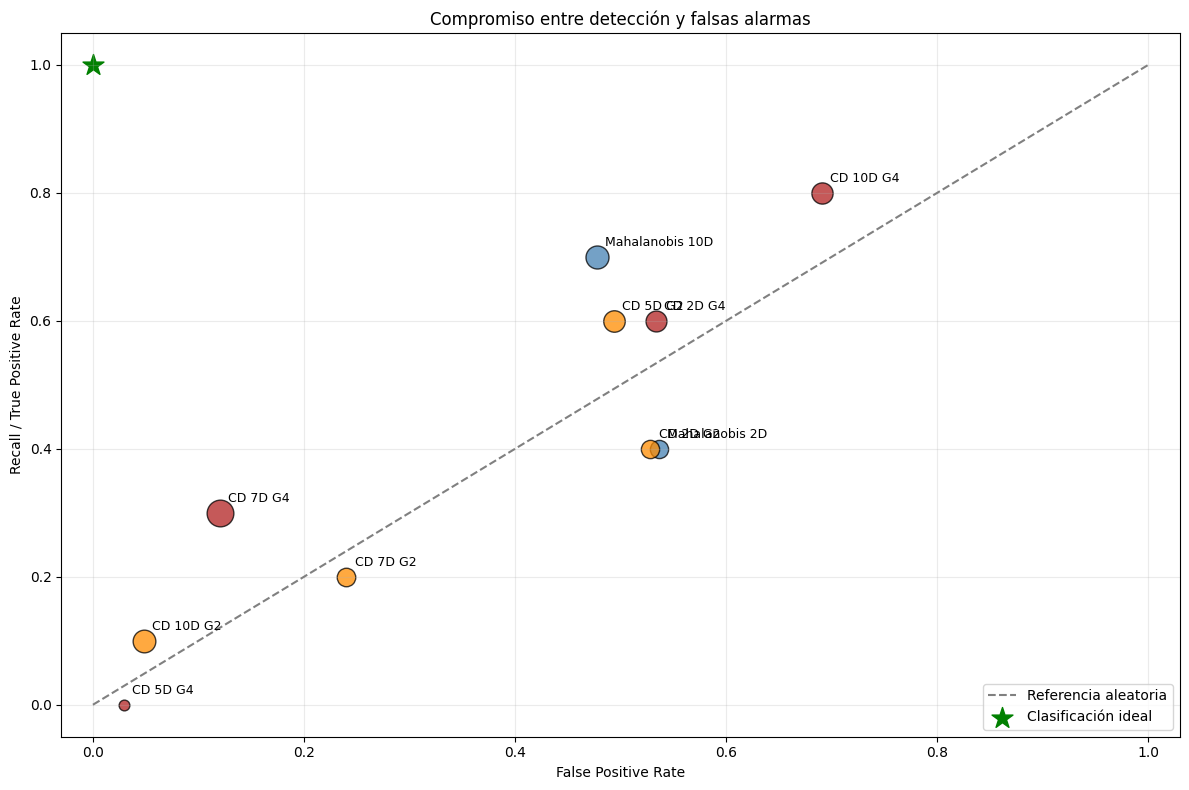

In [198]:
# Compromiso entre detección y falsas alarmas
fig, ax = plt.subplots(figsize=(12, 8))

for _, fila in df_comparacion_final.iterrows():

    if fila["metodo"] == "Mahalanobis":
        color = "steelblue"
    elif fila["grado"] == 2:
        color = "darkorange"
    else:
        color = "firebrick"

    ax.scatter(
        fila["fpr"],
        fila["recall"],
        s=60 + 3000 * fila["f1_score"],
        color=color,
        alpha=0.75,
        edgecolor="black"
    )

    ax.annotate(
        fila["configuracion"],
        (fila["fpr"], fila["recall"]),
        xytext=(6, 8),
        textcoords="offset points",
        fontsize=9
    )

# Referencia de un clasificador aleatorio
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Referencia aleatoria"
)

# Punto de clasificación ideal
ax.scatter(
    0, 1,
    marker="*",
    s=250,
    color="green",
    label="Clasificación ideal"
)

ax.set_title("Compromiso entre detección y falsas alarmas")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("Recall / True Positive Rate")

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.05, 1.05)

ax.grid(alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [199]:
# Mejores configuraciones por criterio
criterios = {
    "precision": "max",
    "recall": "max",
    "f1_score": "max",
    "balanced_accuracy": "max",
    "fpr": "min"
}

resultados_criterios = []

for metrica, objetivo in criterios.items():

    if objetivo == "max":
        indice = df_comparacion_final[metrica].idxmax()
    else:
        indice = df_comparacion_final[metrica].idxmin()

    fila = df_comparacion_final.loc[indice]

    resultados_criterios.append({
        "criterio": metrica,
        "configuracion": fila["configuracion"],
        "valor": fila[metrica],
        "fraudes_detectados": fila["TP"],
        "falsas_alarmas": fila["FP"]
    })

df_mejores_criterios = pd.DataFrame(
    resultados_criterios
)

display(df_mejores_criterios.round(4))

,criterio,configuracion,valor,fraudes_detectados,falsas_alarmas
0,precision,CD 7D G4,0.0625,3,45
1,recall,CD 10D G4,0.8000,8,259
2,f1_score,CD 7D G4,0.1034,3,45
3,balanced_accuracy,Mahalanobis 10D,0.6113,7,179
4,fpr,CD 5D G4,0.0293,0,11


Mahalanobis sigue siendo competitivo: su configuración de diez dimensiones obtiene la mayor exactitud balanceada con una complejidad algebraica considerablemente menor.



Christoffel-Darboux presenta mayor flexibilidad: consigue los mejores resultados observados en precision, recall y F1-score, aunque en configuraciones diferentes.



Minimizar las falsas alarmas no es suficiente: CD 5D G4 tiene la menor FPR, pero no detecta ningún fraude.



Ningún detector presenta un desempeño satisfactorio para producción: incluso la mayor precisión observada es de apenas 6.25%.

#### 7.3. Comparación de curvas ROC
Se evalúa la capacidad de discriminación de los
detectores mediante las curvas ROC y el área bajo
la curva (ROC-AUC).

A diferencia de las métricas de clasificación
calculadas previamente, este análisis considera
todos los posibles umbrales de decisión.

Esto permite distinguir entre la capacidad de
ordenamiento de las puntuaciones de anomalía
y la efectividad del umbral seleccionado durante
el entrenamiento.

In [200]:
# Recuperación de las puntuaciones de anomalía
for nombre, objeto in list(globals().items()):

    if isinstance(objeto, (np.ndarray, pd.Series)):

        if any(
            termino in nombre.lower()
            for termino in ["maha", "dist", "score"]
        ):

            if objeto.shape == (len(y_test),):

                print(
                    f"{nombre}: {objeto.shape}"
                )

scores_test_maha_2d: (385,)
y_pred_test_maha_2d: (385,)
scores_test_maha_10d: (385,)
y_pred_test_maha_10d: (385,)
scores_cd_test_2d: (385,)
scores_cd_test_2d_g4: (385,)


In [201]:
# Recuperación de puntuaciones de Mahalanobis
scores_maha_roc = {}

y_train_array = np.asarray(y_train)

for k in [2, 10]:

    X_train_k = np.asarray(X_train_pca)[:, :k]
    X_test_k = np.asarray(X_test_pca)[:, :k]

    X_legit_k = X_train_k[y_train_array == 0]

    # Covarianza de observaciones legítimas
    sigma = np.cov(
        X_legit_k,
        rowvar=False
    )

    # Resolver el sistema sin invertir explícitamente
    solucion = np.linalg.solve(
        sigma,
        X_test_k.T
    ).T

    distancias_cuadradas = np.sum(
        X_test_k * solucion,
        axis=1
    )

    distancias = np.sqrt(
        np.maximum(distancias_cuadradas, 0)
    )

    scores_maha_roc[k] = distancias

    print(
        f"Mahalanobis {k}D: "
        f"{distancias.shape}"
    )

Mahalanobis 2D: (385,)
Mahalanobis 10D: (385,)


In [202]:
# Integración de todas las puntuaciones
scores_roc = {}

# Mahalanobis
for k in [2, 10]:

    configuracion = f"Mahalanobis {k}D"

    scores_roc[configuracion] = (
        scores_maha_roc[k]
    )

# Christoffel-Darboux
for (k, g), experimento in experimentos_cd.items():

    configuracion = f"CD {k}D G{g}"

    scores_roc[configuracion] = (
        experimento["scores_test"]
    )

# Validación
for configuracion, scores in scores_roc.items():

    print(
        f"{configuracion:<20} | "
        f"Observaciones: {len(scores)} | "
        f"Finitos: {np.isfinite(scores).all()}"
    )

Mahalanobis 2D       | Observaciones: 385 | Finitos: True
Mahalanobis 10D      | Observaciones: 385 | Finitos: True
CD 2D G2             | Observaciones: 385 | Finitos: True
CD 2D G4             | Observaciones: 385 | Finitos: True
CD 5D G2             | Observaciones: 385 | Finitos: True
CD 5D G4             | Observaciones: 385 | Finitos: True
CD 7D G2             | Observaciones: 385 | Finitos: True
CD 7D G4             | Observaciones: 385 | Finitos: True
CD 10D G2            | Observaciones: 385 | Finitos: True
CD 10D G4            | Observaciones: 385 | Finitos: True


In [203]:
# Validación contra matrices de confuisión originales
for _, fila in df_comparacion_final.iterrows():

    configuracion = fila["configuracion"]
    scores = scores_roc[configuracion]

    y_pred = (
        scores > fila["radio"]
    ).astype(int)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    cm_original = np.array([
        [fila["TN"], fila["FP"]],
        [fila["FN"], fila["TP"]]
    ])

    coincidencia = np.array_equal(
        cm,
        cm_original
    )

    print(
        f"{configuracion:<20} | "
        f"Coincidencia: {coincidencia}"
    )

Mahalanobis 2D       | Coincidencia: True
Mahalanobis 10D      | Coincidencia: True
CD 2D G2             | Coincidencia: True
CD 2D G4             | Coincidencia: True
CD 5D G2             | Coincidencia: True
CD 5D G4             | Coincidencia: True
CD 7D G2             | Coincidencia: True
CD 7D G4             | Coincidencia: True
CD 10D G2            | Coincidencia: True
CD 10D G4            | Coincidencia: True


In [204]:
# Cálculo de las curvas
from sklearn.metrics import roc_curve, roc_auc_score

curvas_roc = {}
resultados_roc = []

for configuracion, scores in scores_roc.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        scores
    )

    auc = roc_auc_score(
        y_test,
        scores
    )

    curvas_roc[configuracion] = {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds,
        "auc": auc
    }

    resultados_roc.append({
        "configuracion": configuracion,
        "roc_auc": auc
    })

df_resultados_roc = (
    pd.DataFrame(resultados_roc)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(df_resultados_roc.round(6))

,configuracion,roc_auc
0,CD 10D G4,0.674933
1,CD 10D G2,0.623200
2,Mahalanobis 10D,0.608000
3,CD 7D G4,0.591200
4,CD 5D G4,0.578133
5,CD 5D G2,0.518667
6,CD 7D G2,0.502667
7,Mahalanobis 2D,0.476800
8,CD 2D G2,0.464267
9,CD 2D G4,0.448800


In [206]:
# Actualización de tabla comparativa
mapa_auc = (
    df_resultados_roc
    .set_index("configuracion")["roc_auc"]
)

df_comparacion_final["roc_auc"] = (
    df_comparacion_final["configuracion"]
    .map(mapa_auc)
)

display(
    df_comparacion_final[
        [
            "configuracion",
            "varianza_explicada_pct",
            "f1_score",
            "balanced_accuracy",
            "roc_auc"
        ]
    ].round(4)
)

,configuracion,varianza_explicada_pct,f1_score,balanced_accuracy,roc_auc
0,Mahalanobis 2D,22.0204,0.0372,0.4320,0.4768
1,Mahalanobis 10D,66.9230,0.0714,0.6113,0.6080
2,CD 2D G2,22.0204,0.0377,0.4360,0.4643
3,CD 2D G4,22.0204,0.0556,0.5333,0.4488
4,CD 5D G2,44.5802,0.0597,0.5533,0.5187
5,CD 5D G4,44.5802,0.0000,0.4853,0.5781
6,CD 7D G2,53.7863,0.0392,0.4800,0.5027
7,CD 7D G4,53.7863,0.1034,0.5900,0.5912
8,CD 10D G2,66.9230,0.0690,0.5260,0.6232
9,CD 10D G4,66.9230,0.0578,0.5547,0.6749


In [211]:
# Visualizar las curvas
def graficar_curvas_roc(configuraciones, titulo):

    fig, ax = plt.subplots(figsize=(10, 7))

    for configuracion in configuraciones:

        curva = curvas_roc[configuracion]

        ax.plot(
            curva["fpr"],
            curva["tpr"],
            linewidth=2,
            label=(
                f"{configuracion} "
                f"(AUC = {curva['auc']:.4f})"
            )
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Referencia aleatoria"
    )

    ax.set_title(titulo)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

    plt.tight_layout()
    plt.show()

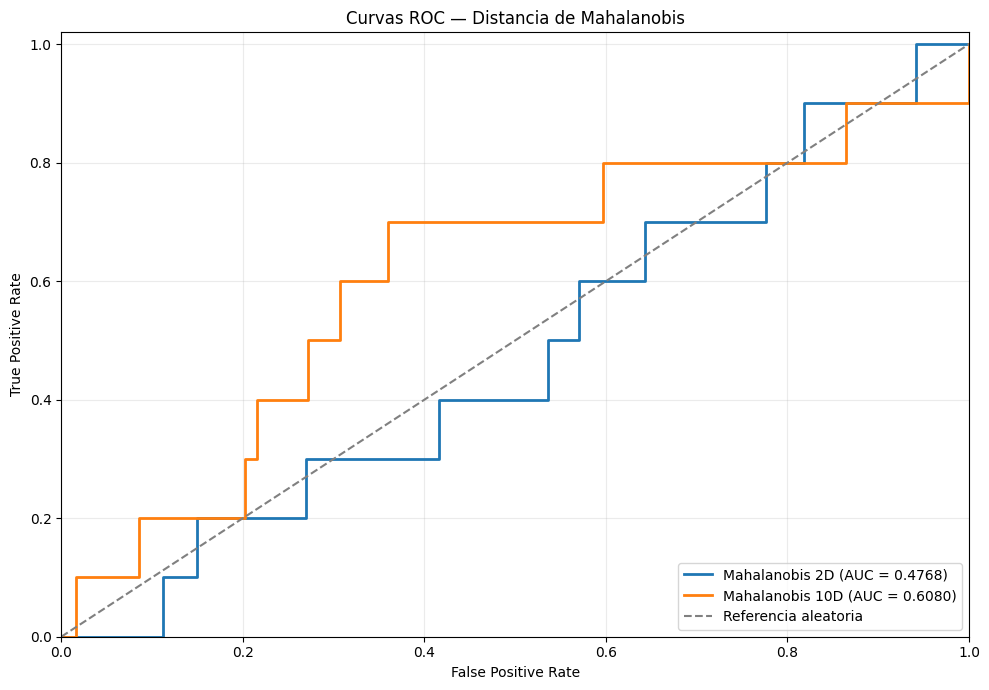

In [212]:
graficar_curvas_roc(
    [
        "Mahalanobis 2D",
        "Mahalanobis 10D"
    ],
    "Curvas ROC — Distancia de Mahalanobis"
)

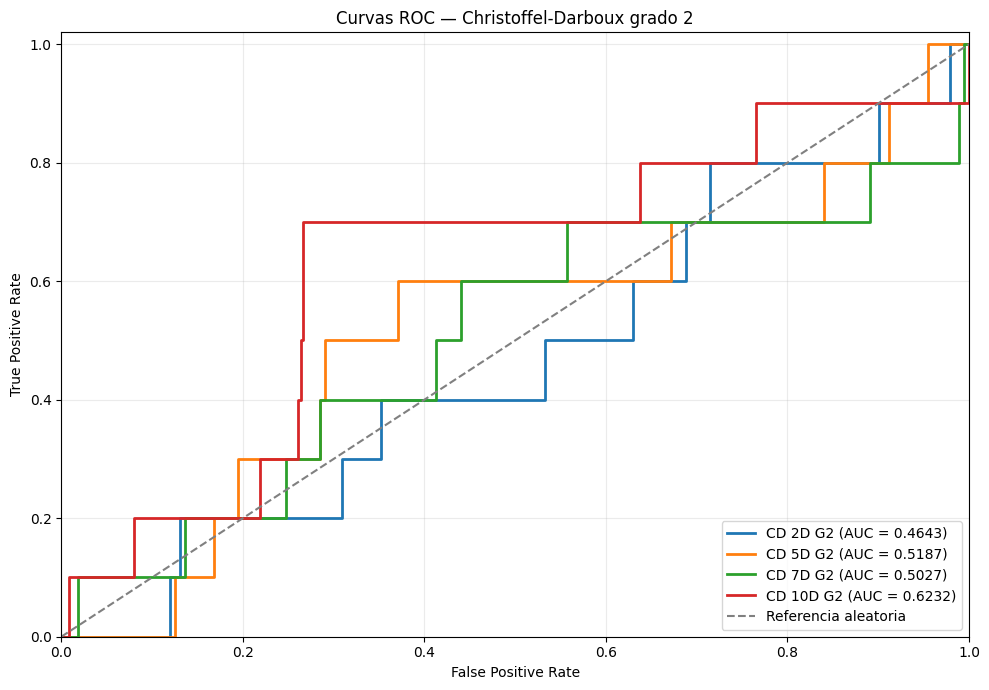

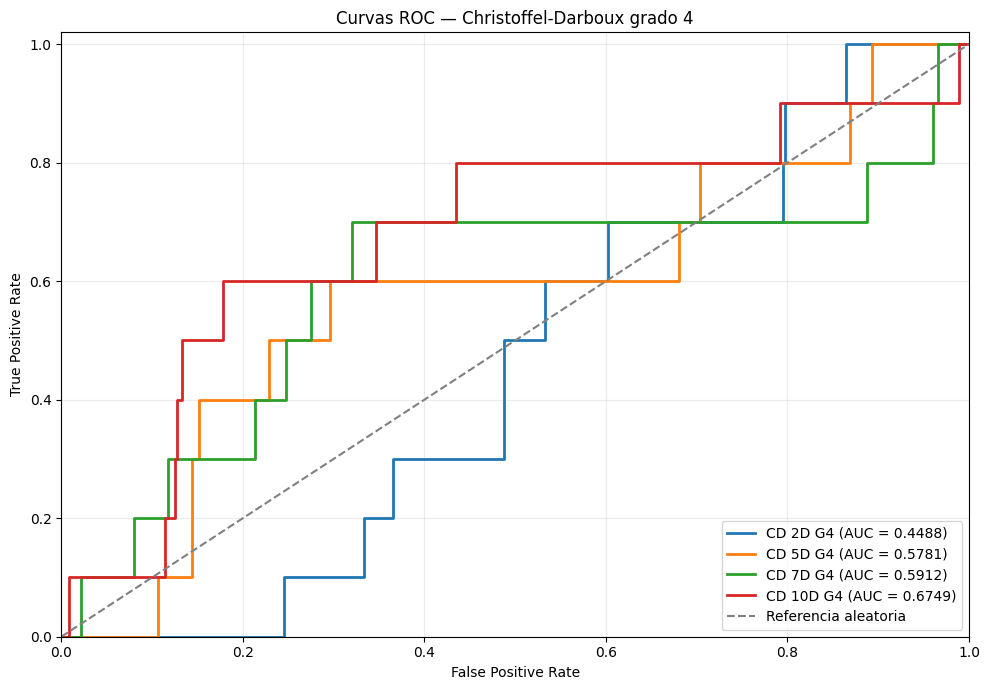

In [213]:
for grado in [2, 4]:

    configuraciones = [
        f"CD {k}D G{grado}"
        for k in [2, 5, 7, 10]
    ]

    graficar_curvas_roc(
        configuraciones,
        f"Curvas ROC — Christoffel-Darboux grado {grado}"
    )

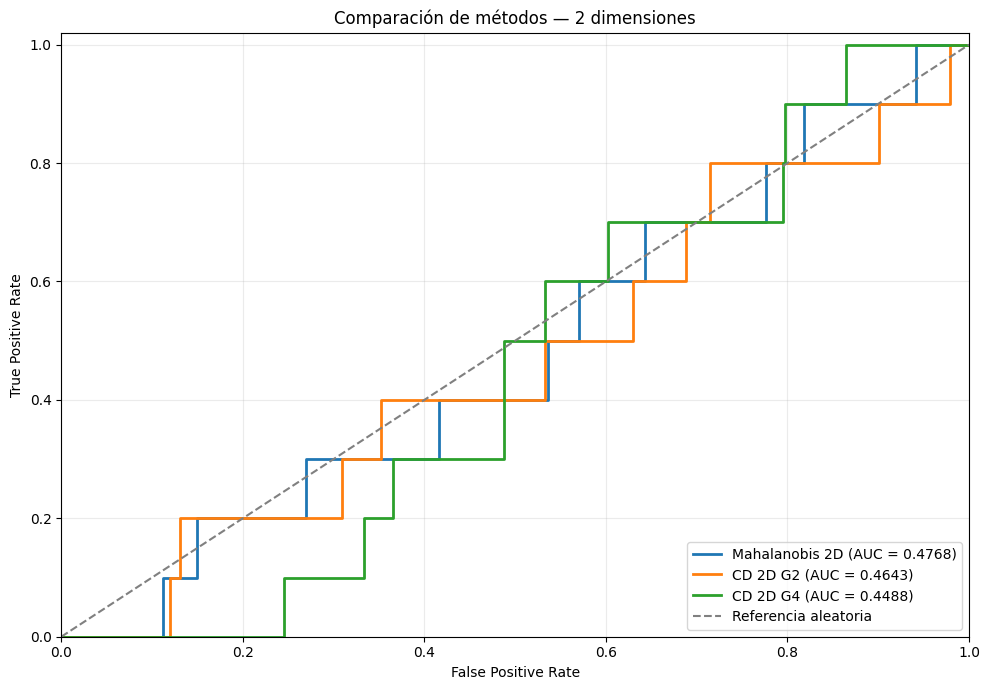

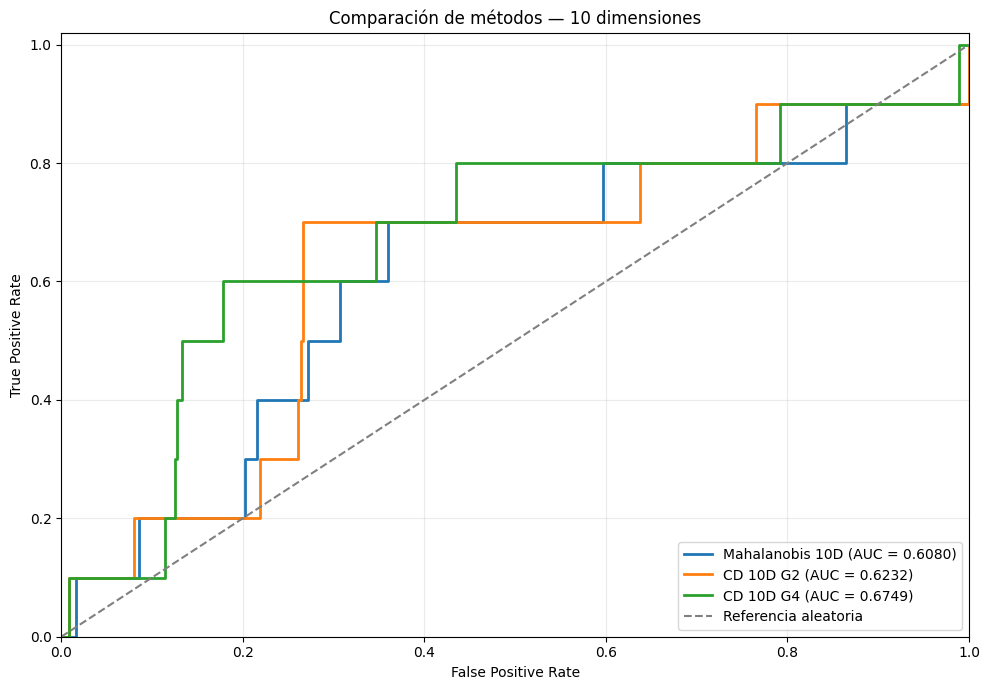

In [214]:
for k in [2, 10]:

    graficar_curvas_roc(
        [
            f"Mahalanobis {k}D",
            f"CD {k}D G2",
            f"CD {k}D G4"
        ],
        f"Comparación de métodos — {k} dimensiones"
    )

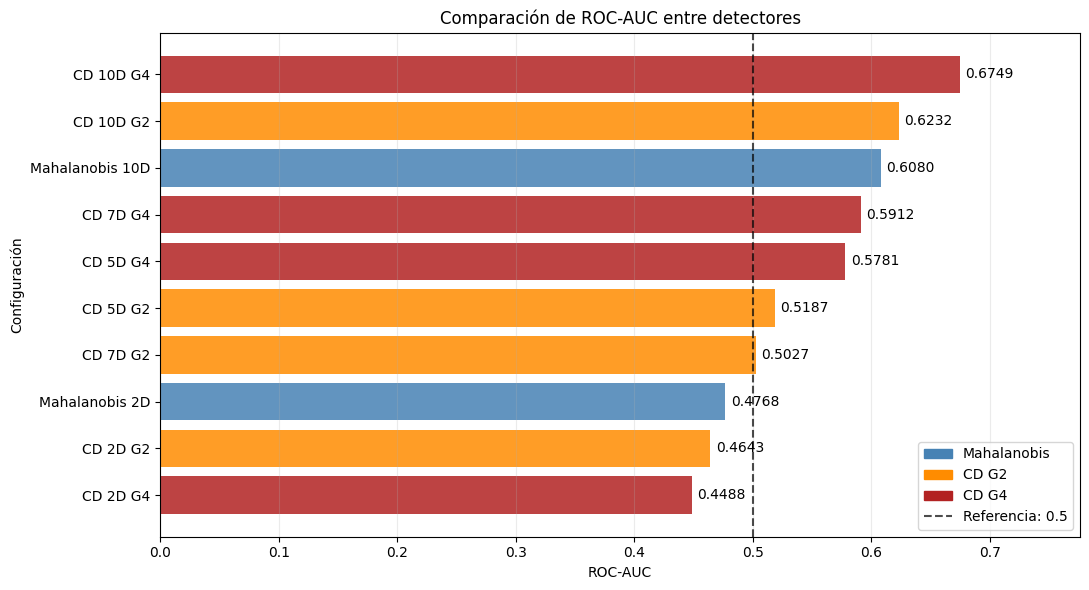

In [215]:
graficar_comparacion_final(
    metrica="roc_auc",
    titulo="Comparación de ROC-AUC entre detectores",
    xlabel="ROC-AUC",
    referencia=0.5
)

#### 7.4. Comparación de matrices de confusión
Se construyen las matrices de confusión de los diez
experimentos utilizando los umbrales seleccionados
durante el entrenamiento.

Se consideran tanto las frecuencias absolutas como
las frecuencias relativas normalizadas por clase real.

La normalización permite comparar la capacidad de
clasificación de ambas clases sin que la interpretación
visual esté dominada por las transacciones legítimas.

Finalmente, se representa cada matriz de confusión
mediante un vector de cuatro elementos para facilitar
su incorporación en el reporte comparativo final.

In [216]:
matrices_confusion_final = {}

for _, fila in df_comparacion_final.iterrows():

    configuracion = fila["configuracion"]

    matriz = np.array([
        [fila["TN"], fila["FP"]],
        [fila["FN"], fila["TP"]]
    ], dtype=int)

    matrices_confusion_final[configuracion] = matriz

    print(f"{configuracion}:")
    print(matriz)
    print()

Mahalanobis 2D:
[[174 201]
 [  6   4]]

Mahalanobis 10D:
[[196 179]
 [  3   7]]

CD 2D G2:
[[177 198]
 [  6   4]]

CD 2D G4:
[[175 200]
 [  4   6]]

CD 5D G2:
[[190 185]
 [  4   6]]

CD 5D G4:
[[364  11]
 [ 10   0]]

CD 7D G2:
[[285  90]
 [  8   2]]

CD 7D G4:
[[330  45]
 [  7   3]]

CD 10D G2:
[[357  18]
 [  9   1]]

CD 10D G4:
[[116 259]
 [  2   8]]



In [217]:
from sklearn.metrics import ConfusionMatrixDisplay

def graficar_matrices_confusion(
    configuraciones,
    normalizar=False,
    columnas=3
):

    n = len(configuraciones)
    filas = int(np.ceil(n / columnas))

    fig, axes = plt.subplots(
        filas,
        columnas,
        figsize=(4.5 * columnas, 4 * filas),
        squeeze=False
    )

    axes = axes.ravel()

    for ax, configuracion in zip(
        axes,
        configuraciones
    ):

        matriz = matrices_confusion_final[
            configuracion
        ].copy()

        if normalizar:

            matriz = (
                matriz
                / matriz.sum(axis=1, keepdims=True)
            )

            formato = ".1%"
            vmax = 1

        else:

            formato = "d"
            vmax = 375

        disp = ConfusionMatrixDisplay(
            confusion_matrix=matriz,
            display_labels=["Legítima", "Fraude"]
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            colorbar=False,
            values_format=formato,
            im_kw={
                "vmin": 0,
                "vmax": vmax
            }
        )

        ax.set_title(configuracion)
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")

    # Ocultar espacios no utilizados
    for ax in axes[n:]:
        ax.axis("off")

    titulo = (
        "Matrices de confusión normalizadas"
        if normalizar
        else "Matrices de confusión absolutas"
    )

    fig.suptitle(titulo, fontsize=15)

    plt.tight_layout()
    plt.show()

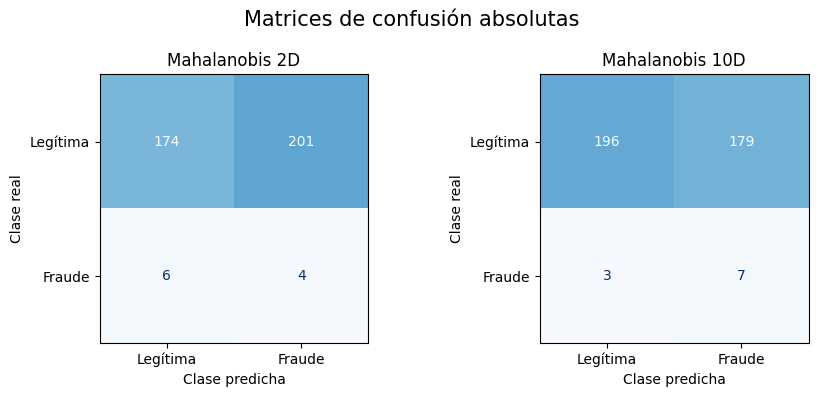

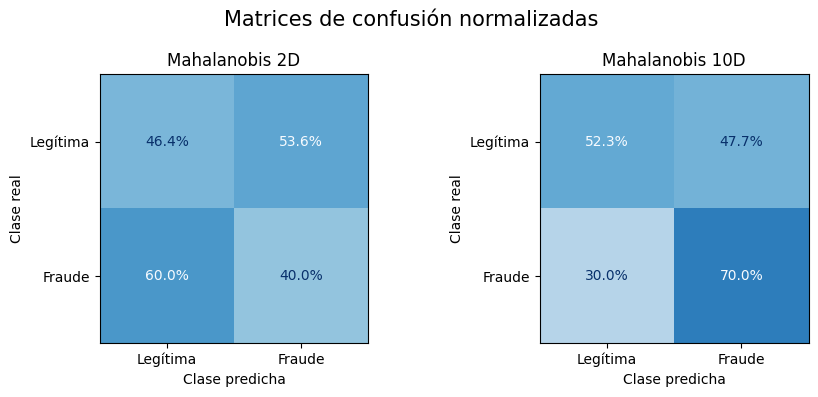

In [218]:
# Comparación de Mahalanobis
configuraciones_maha = [
    "Mahalanobis 2D",
    "Mahalanobis 10D"
]

graficar_matrices_confusion(
    configuraciones_maha,
    columnas=2
)

graficar_matrices_confusion(
    configuraciones_maha,
    normalizar=True,
    columnas=2
)

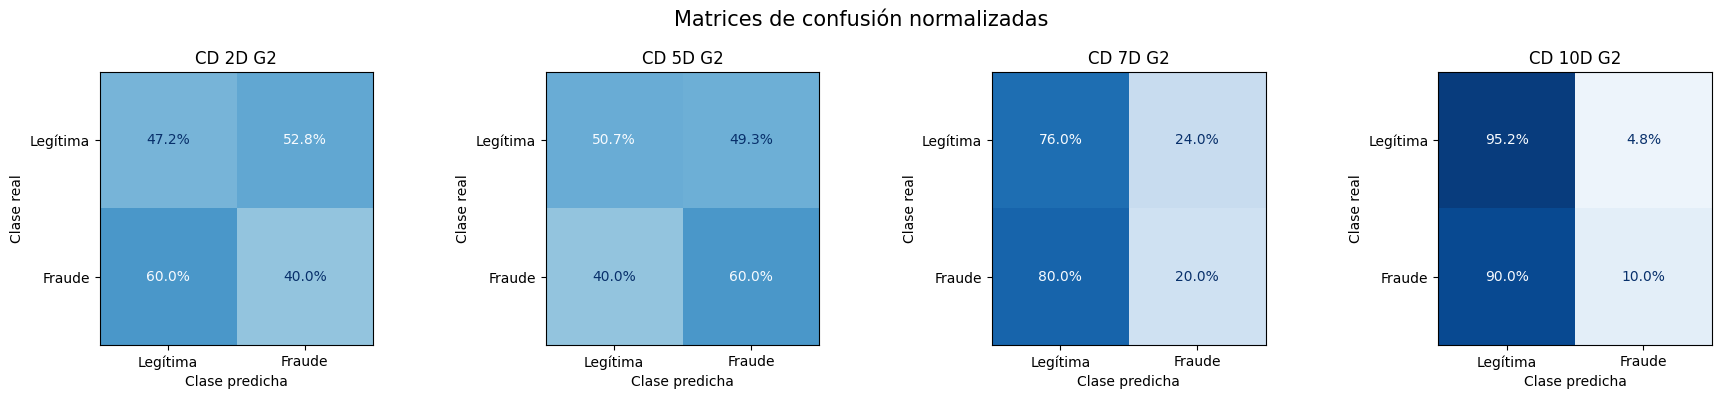

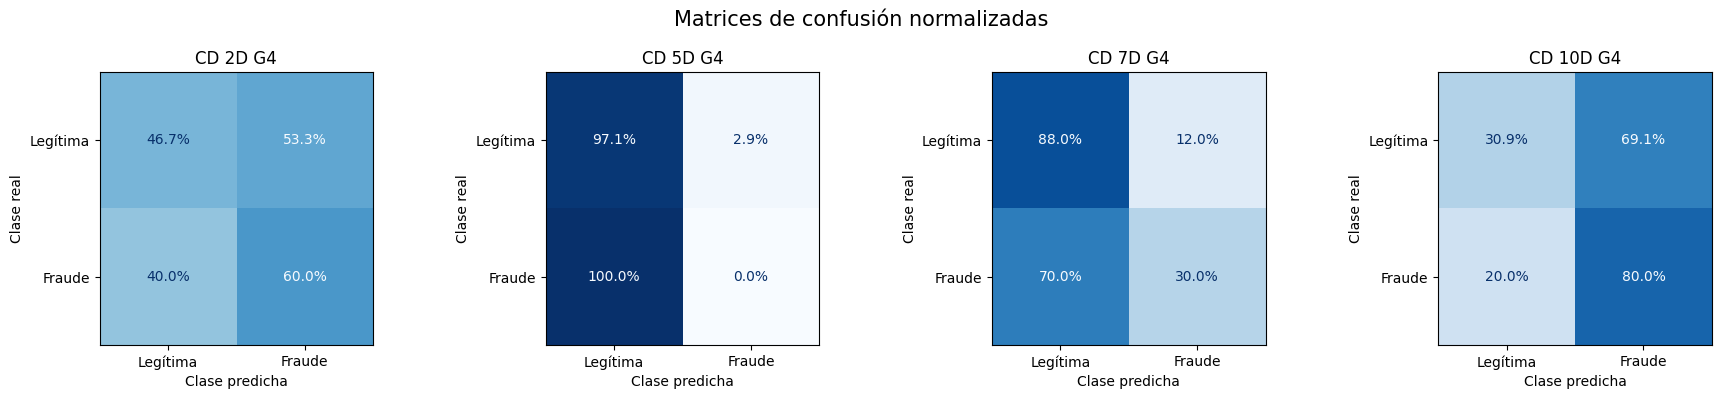

In [219]:
# Comparación CD
for grado in [2, 4]:

    configuraciones = [
        f"CD {k}D G{grado}"
        for k in [2, 5, 7, 10]
    ]

    graficar_matrices_confusion(
        configuraciones,
        normalizar=True,
        columnas=4
    )

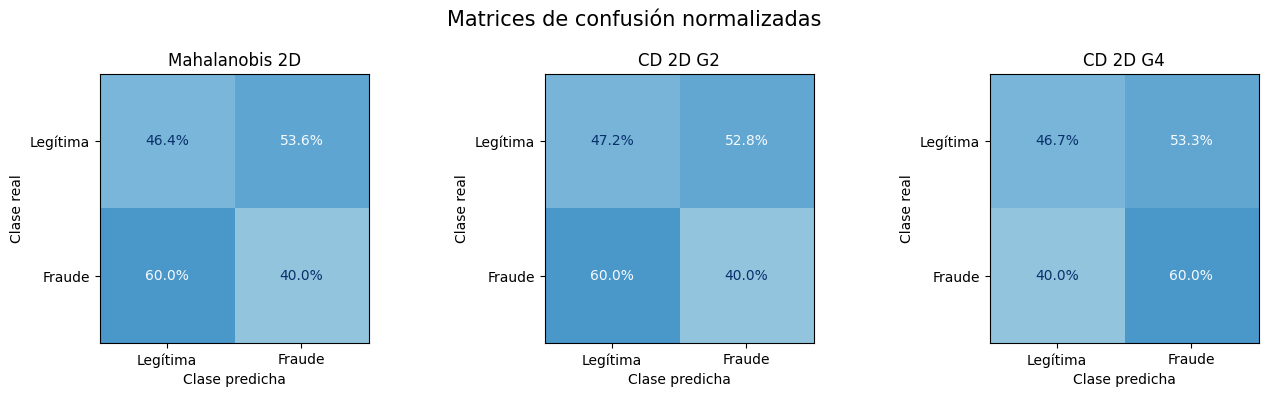

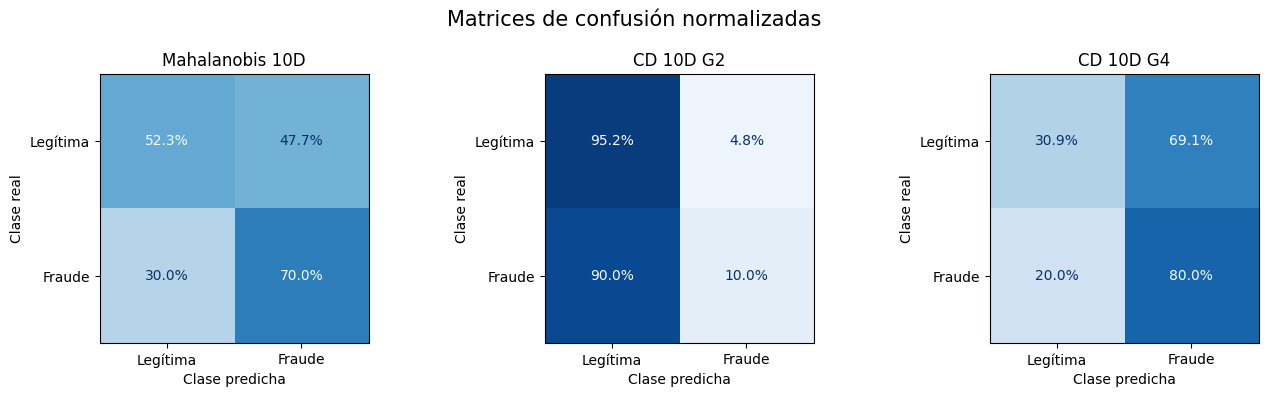

In [220]:
# Comparación directa entre métodos
for k in [2, 10]:

    configuraciones = [
        f"Mahalanobis {k}D",
        f"CD {k}D G2",
        f"CD {k}D G4"
    ]

    graficar_matrices_confusion(
        configuraciones,
        normalizar=True,
        columnas=3
    )

In [221]:
df_comparacion_final["matriz_confusion"] = (
    df_comparacion_final.apply(
        lambda fila: [
            int(fila["TN"]),
            int(fila["FP"]),
            int(fila["FN"]),
            int(fila["TP"])
        ],
        axis=1
    )
)

columnas_resumen = [
    "configuracion",
    "varianza_explicada_pct",
    "matriz_confusion",
    "precision",
    "recall",
    "f1_score",
    "balanced_accuracy",
    "roc_auc"
]

df_resumen_confusion = (
    df_comparacion_final[columnas_resumen]
    .copy()
)

display(df_resumen_confusion.round(4))

,configuracion,varianza_explicada_pct,matriz_confusion,precision,recall,f1_score,balanced_accuracy,roc_auc
0,Mahalanobis 2D,22.0204,"[174, 201, 6, 4]",0.0195,0.4,0.0372,0.4320,0.4768
1,Mahalanobis 10D,66.9230,"[196, 179, 3, 7]",0.0376,0.7,0.0714,0.6113,0.6080
2,CD 2D G2,22.0204,"[177, 198, 6, 4]",0.0198,0.4,0.0377,0.4360,0.4643
3,CD 2D G4,22.0204,"[175, 200, 4, 6]",0.0291,0.6,0.0556,0.5333,0.4488
4,CD 5D G2,44.5802,"[190, 185, 4, 6]",0.0314,0.6,0.0597,0.5533,0.5187
5,CD 5D G4,44.5802,"[364, 11, 10, 0]",0.0000,0.0,0.0000,0.4853,0.5781
6,CD 7D G2,53.7863,"[285, 90, 8, 2]",0.0217,0.2,0.0392,0.4800,0.5027
7,CD 7D G4,53.7863,"[330, 45, 7, 3]",0.0625,0.3,0.1034,0.5900,0.5912
8,CD 10D G2,66.9230,"[357, 18, 9, 1]",0.0526,0.1,0.0690,0.5260,0.6232
9,CD 10D G4,66.9230,"[116, 259, 2, 8]",0.0300,0.8,0.0578,0.5547,0.6749


#### 7.5. Comparación geométrica de las regiones en 2D

Se comparan las regiones de aceptación construidas
mediante la distancia de Mahalanobis y el kernel
de Christoffel-Darboux de grados dos y cuatro.

Las visualizaciones utilizan una representación
bidimensional común, correspondiente a las dos
primeras componentes principales, que conservan
el 22.02% de la varianza original.

Se analiza la capacidad de cada método para
representar la geometría de las transacciones
legítimas, así como la distribución de las
transacciones fraudulentas respecto a las
fronteras de aceptación.

In [222]:
# Recuperación de los datos
X_train_2d = np.asarray(X_train_pca)[:, :2]
X_test_2d = np.asarray(X_test_pca)[:, :2]

y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

X_legit_train_2d = X_train_2d[y_train_array == 0]
X_fraud_train_2d = X_train_2d[y_train_array == 1]

X_legit_test_2d = X_test_2d[y_test_array == 0]
X_fraud_test_2d = X_test_2d[y_test_array == 1]

print("Entrenamiento:")
print("Legítimas:", X_legit_train_2d.shape)
print("Fraudulentas:", X_fraud_train_2d.shape)

print("\nPrueba:")
print("Legítimas:", X_legit_test_2d.shape)
print("Fraudulentas:", X_fraud_test_2d.shape)

Entrenamiento:
Legítimas: (1494, 2)
Fraudulentas: (42, 2)

Prueba:
Legítimas: (375, 2)
Fraudulentas: (10, 2)


In [223]:
# Construcción de la malla
limites_inferiores = np.percentile(
    X_train_2d,
    0.5,
    axis=0
)

limites_superiores = np.percentile(
    X_train_2d,
    99.5,
    axis=0
)

margen = (
    limites_superiores
    - limites_inferiores
) * 0.15

x_min, y_min = limites_inferiores - margen
x_max, y_max = limites_superiores + margen

resolucion = 400

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, resolucion),
    np.linspace(y_min, y_max, resolucion)
)

malla_2d = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

print("Dimensión de la malla:", malla_2d.shape)
print("Puntos por evaluar:", len(malla_2d))

Dimensión de la malla: (160000, 2)
Puntos por evaluar: 160000


In [224]:
# Evaluación de los tres métodos sobre la malla
sigma_maha_2d = np.cov(
    X_legit_train_2d,
    rowvar=False
)

solucion_malla = np.linalg.solve(
    sigma_maha_2d,
    malla_2d.T
).T

scores_malla_maha = np.sqrt(
    np.maximum(
        np.sum(
            malla_2d * solucion_malla,
            axis=1
        ),
        0
    )
)

Z_maha = scores_malla_maha.reshape(xx.shape)

print("Superficie Mahalanobis:", Z_maha.shape)

Superficie Mahalanobis: (400, 400)


In [225]:
solucion_legit = np.linalg.solve(
    sigma_maha_2d,
    X_legit_train_2d.T
).T

distancias_legit_maha = np.sqrt(
    np.maximum(
        np.sum(
            X_legit_train_2d * solucion_legit,
            axis=1
        ),
        0
    )
)

percentiles = [50, 75, 90, 95, 99]

distancias_ordenadas = np.sort(
    distancias_legit_maha
)

N = len(distancias_ordenadas)

umbrales_geo_maha = {
    n: distancias_ordenadas[
        int(np.ceil(N * n / 100)) - 1
    ]
    for n in percentiles
}

print(umbrales_geo_maha)

{50: np.float64(1.0227046710349523), 75: np.float64(1.380519946057598), 90: np.float64(1.9219026551163791), 95: np.float64(2.1752817113456344), 99: np.float64(3.637514057437866)}


In [226]:
superficies_cd = {}

for grado in [2, 4]:

    experimento = experimentos_cd[(2, grado)]
    modelo = experimento["modelo"]

    scores_malla = calcular_score_cd(
        malla_2d,
        modelo["poly"],
        modelo["L"]
    )

    superficies_cd[grado] = (
        scores_malla.reshape(xx.shape)
    )

    print(
        f"Superficie CD grado {grado}:",
        superficies_cd[grado].shape
    )

Superficie CD grado 2: (400, 400)
Superficie CD grado 4: (400, 400)


In [227]:
superficies_geo = {
    "Mahalanobis 2D": {
        "Z": Z_maha,
        "umbrales": umbrales_geo_maha
    },

    "CD 2D G2": {
        "Z": superficies_cd[2],
        "umbrales": (
            experimentos_cd[(2, 2)]
            ["calibracion"]["umbrales"]
        )
    },

    "CD 2D G4": {
        "Z": superficies_cd[4],
        "umbrales": (
            experimentos_cd[(2, 4)]
            ["calibracion"]["umbrales"]
        )
    }
}

for nombre, superficie in superficies_geo.items():

    print(
        f"{nombre:<20} | "
        f"Dimensión: {superficie['Z'].shape} | "
        f"Finitos: {np.isfinite(superficie['Z']).all()}"
    )

Mahalanobis 2D       | Dimensión: (400, 400) | Finitos: True
CD 2D G2             | Dimensión: (400, 400) | Finitos: True
CD 2D G4             | Dimensión: (400, 400) | Finitos: True


In [228]:
# Comparación de las regiones percentiles
from matplotlib.lines import Line2D

colores_percentiles = {
    50: "#2166ac",
    75: "#67a9cf",
    90: "#fdae61",
    95: "#ef6548",
    99: "#b2182b"
}

def graficar_regiones_comparativas(
    X_legit,
    X_fraud,
    conjunto="Entrenamiento"
):

    fig, axes = plt.subplots(
        1, 3,
        figsize=(19, 6),
        sharex=True,
        sharey=True
    )

    for ax, (nombre, superficie) in zip(
        axes,
        superficies_geo.items()
    ):

        # Transacciones legítimas
        ax.scatter(
            X_legit[:, 0],
            X_legit[:, 1],
            color="gray",
            alpha=0.20,
            s=12,
            zorder=1
        )

        # Fronteras percentiles
        for n in percentiles:

            ax.contour(
                xx,
                yy,
                superficie["Z"],
                levels=[superficie["umbrales"][n]],
                colors=[colores_percentiles[n]],
                linewidths=1.8,
                zorder=2
            )

        # Transacciones fraudulentas
        ax.scatter(
            X_fraud[:, 0],
            X_fraud[:, 1],
            color="black",
            marker="x",
            s=45,
            linewidths=1.5,
            zorder=3
        )

        ax.set_title(nombre)
        ax.set_xlabel("Componente principal 1")

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)

        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.15)

    axes[0].set_ylabel("Componente principal 2")

    leyenda = [
        Line2D(
            [0], [0],
            color=colores_percentiles[n],
            linewidth=2,
            label=f"Percentil {n}"
        )
        for n in percentiles
    ]

    leyenda.extend([
        Line2D(
            [0], [0],
            marker="o",
            linestyle="none",
            color="gray",
            label="Legítimas"
        ),
        Line2D(
            [0], [0],
            marker="x",
            linestyle="none",
            color="black",
            label="Fraudes"
        )
    ])

    fig.suptitle(
        f"Comparación geométrica — {conjunto}",
        fontsize=16
    )

    fig.legend(
        handles=leyenda,
        loc="lower center",
        ncol=7,
        bbox_to_anchor=(0.5, 0.01)
    )

    plt.tight_layout(
        rect=[0, 0.08, 1, 0.93]
    )

    plt.show()

    return fig

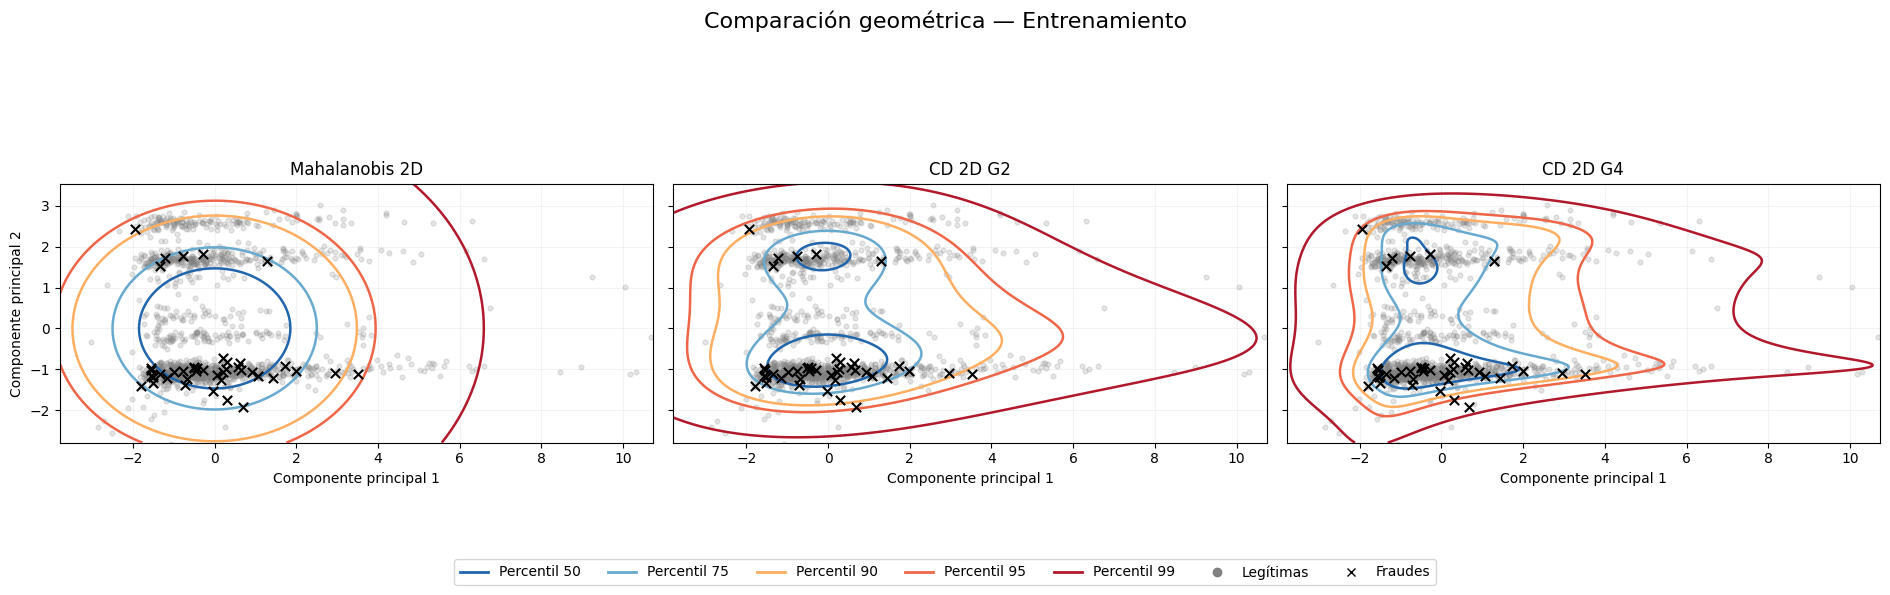

In [229]:
fig_geometria_train = graficar_regiones_comparativas(
    X_legit_train_2d,
    X_fraud_train_2d,
    conjunto="Entrenamiento"
)

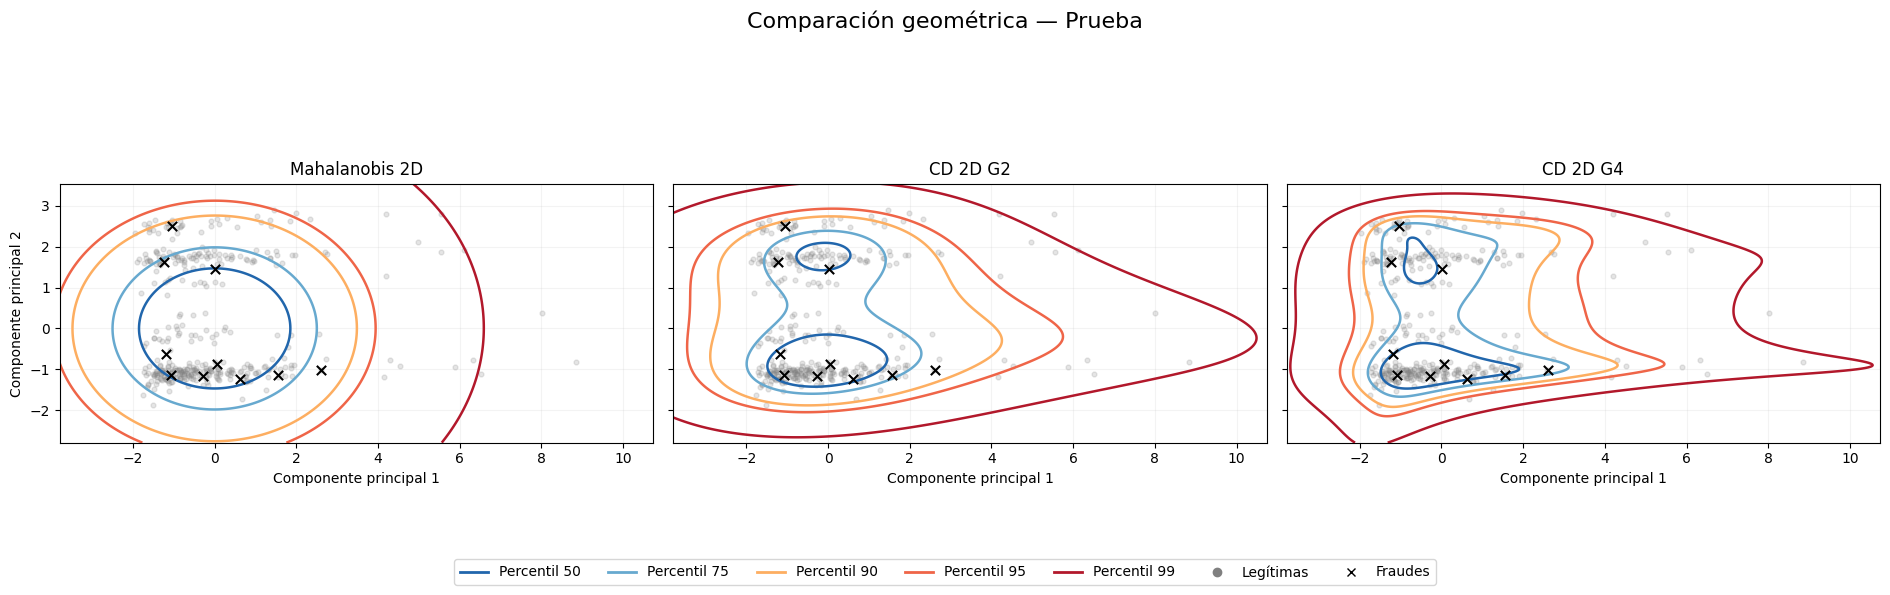

In [230]:
fig_geometria_test = graficar_regiones_comparativas(
    X_legit_test_2d,
    X_fraud_test_2d,
    conjunto="Prueba"
)

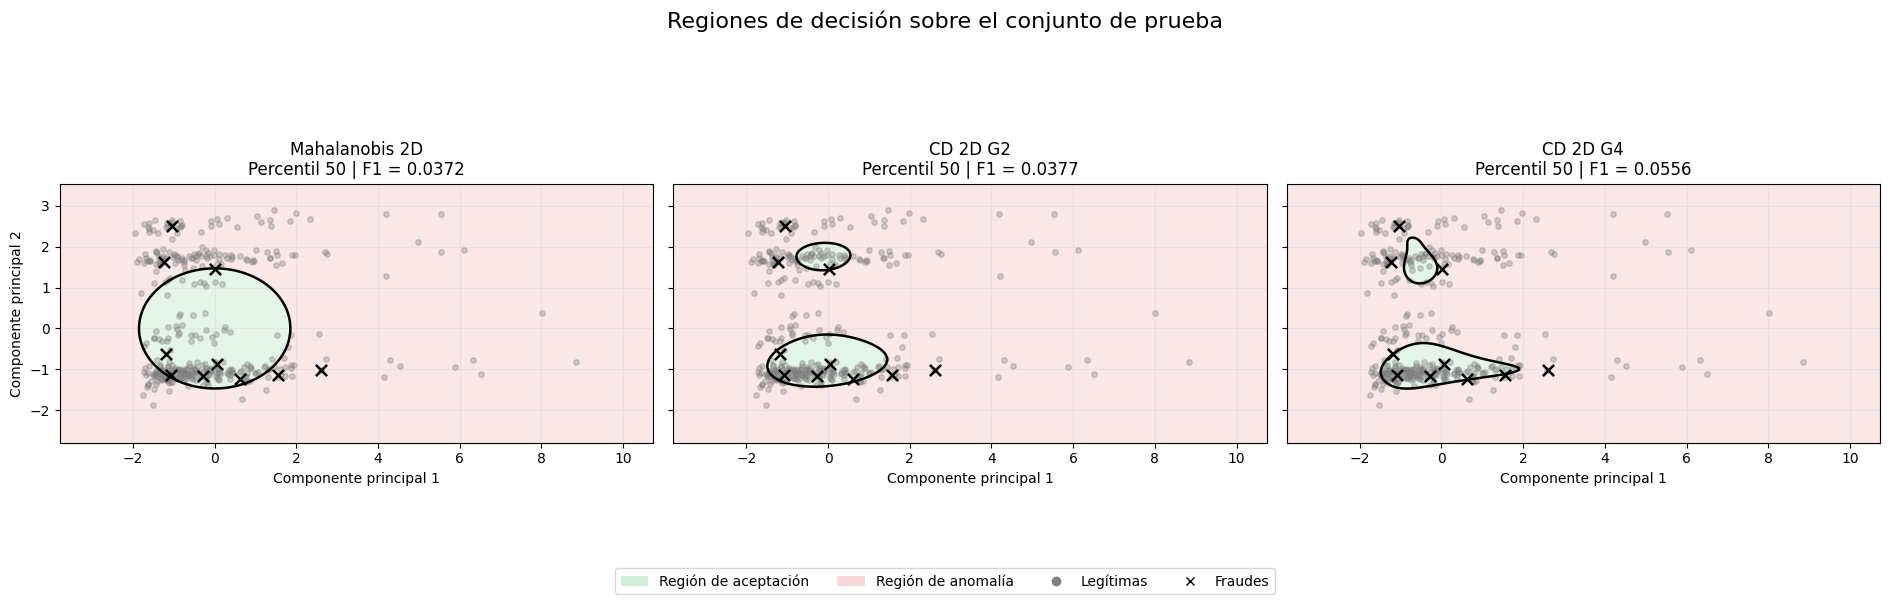

In [231]:
# Visualización de las regiones de decisión
fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6),
    sharex=True,
    sharey=True
)

for ax, (nombre, superficie) in zip(
    axes,
    superficies_geo.items()
):

    fila = df_comparacion_final.loc[
        df_comparacion_final["configuracion"] == nombre
    ].iloc[0]

    rho = float(fila["radio"])

    # Región de aceptación
    region_aceptacion = (
        superficie["Z"] <= rho
    ).astype(int)

    ax.contourf(
        xx,
        yy,
        region_aceptacion,
        levels=[-0.5, 0.5, 1.5],
        colors=["#f8d7da", "#d4edda"],
        alpha=0.6
    )

    # Frontera de decisión
    ax.contour(
        xx,
        yy,
        superficie["Z"],
        levels=[rho],
        colors=["black"],
        linewidths=1.8
    )

    ax.scatter(
        X_legit_test_2d[:, 0],
        X_legit_test_2d[:, 1],
        color="gray",
        alpha=0.35,
        s=15
    )

    ax.scatter(
        X_fraud_test_2d[:, 0],
        X_fraud_test_2d[:, 1],
        color="black",
        marker="x",
        s=65,
        linewidths=1.8
    )

    ax.set_title(
        f"{nombre}\n"
        f"Percentil {int(fila['percentil'])} | "
        f"F1 = {fila['f1_score']:.4f}"
    )

    ax.set_xlabel("Componente principal 1")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.15)

axes[0].set_ylabel("Componente principal 2")

from matplotlib.patches import Patch

leyenda = [
    Patch(
        facecolor="#d4edda",
        label="Región de aceptación"
    ),
    Patch(
        facecolor="#f8d7da",
        label="Región de anomalía"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        color="gray",
        label="Legítimas"
    ),
    Line2D(
        [0], [0],
        marker="x",
        linestyle="none",
        color="black",
        label="Fraudes"
    )
]

fig.legend(
    handles=leyenda,
    loc="lower center",
    ncol=4
)

fig.suptitle(
    "Regiones de decisión sobre el conjunto de prueba",
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0.08, 1, 0.93]
)

fig_geometria_decision = fig

plt.show()

In [232]:
# Validación de cobertura de las regiones
resultados_cobertura = []

for nombre, superficie in superficies_geo.items():

    scores = np.asarray(scores_roc[nombre])

    scores_legit = scores[y_test_array == 0]
    scores_fraud = scores[y_test_array == 1]

    for n, rho in superficie["umbrales"].items():

        resultados_cobertura.append({
            "configuracion": nombre,
            "percentil": n,
            "radio": rho,

            "legitimas_dentro": np.sum(
                scores_legit <= rho
            ),

            "fraudes_dentro": np.sum(
                scores_fraud <= rho
            ),

            "cobertura_legit_pct": (
                np.mean(scores_legit <= rho) * 100
            ),

            "fraudes_dentro_pct": (
                np.mean(scores_fraud <= rho) * 100
            ),

            "fraudes_fuera_pct": (
                np.mean(scores_fraud > rho) * 100
            )
        })

df_cobertura_geometrica = pd.DataFrame(
    resultados_cobertura
)

display(
    df_cobertura_geometrica.round(4)
)

,configuracion,percentil,radio,legitimas_dentro,fraudes_dentro,cobertura_legit_pct,fraudes_dentro_pct,fraudes_fuera_pct
0,Mahalanobis 2D,50,1.0227,174,6,46.4000,60.0,40.0
1,Mahalanobis 2D,75,1.3805,287,8,76.5333,80.0,20.0
2,Mahalanobis 2D,90,1.9219,346,10,92.2667,100.0,0.0
3,Mahalanobis 2D,95,2.1753,358,10,95.4667,100.0,0.0
4,Mahalanobis 2D,99,3.6375,371,10,98.9333,100.0,0.0
5,CD 2D G2,50,3.1749,177,6,47.2000,60.0,40.0
6,CD 2D G2,75,4.8500,293,8,78.1333,80.0,20.0
7,CD 2D G2,90,9.4216,345,10,92.0000,100.0,0.0
8,CD 2D G2,95,13.4312,359,10,95.7333,100.0,0.0
9,CD 2D G2,99,39.4333,373,10,99.4667,100.0,0.0


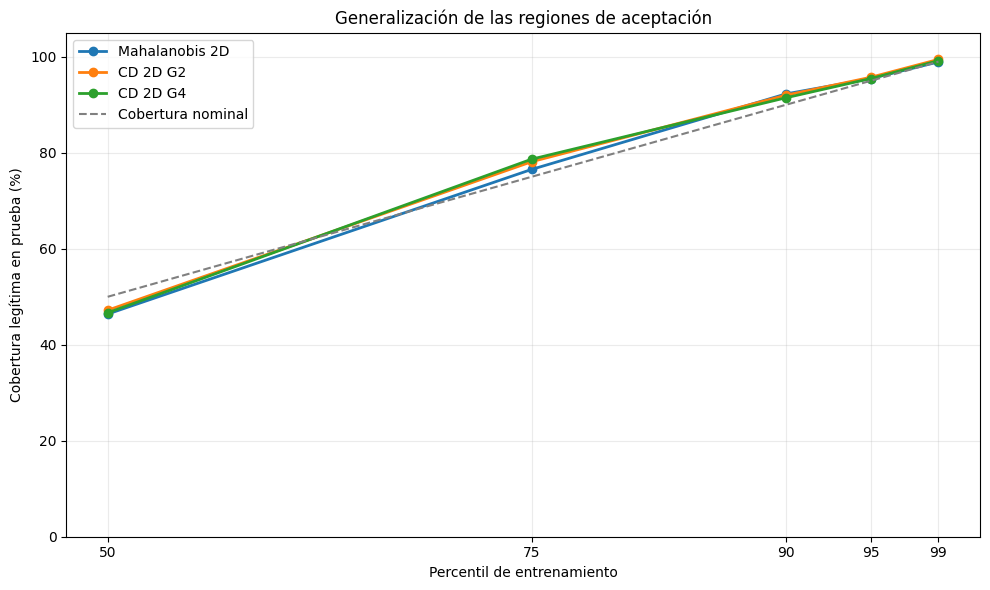

In [233]:
fig, ax = plt.subplots(figsize=(10, 6))

for nombre in superficies_geo:

    datos = df_cobertura_geometrica.loc[
        df_cobertura_geometrica["configuracion"] == nombre
    ].sort_values("percentil")

    ax.plot(
        datos["percentil"],
        datos["cobertura_legit_pct"],
        marker="o",
        linewidth=2,
        label=nombre
    )

ax.plot(
    percentiles,
    percentiles,
    linestyle="--",
    color="gray",
    label="Cobertura nominal"
)

ax.set_title(
    "Generalización de las regiones de aceptación"
)

ax.set_xlabel("Percentil de entrenamiento")
ax.set_ylabel("Cobertura legítima en prueba (%)")

ax.set_xticks(percentiles)
ax.set_ylim(0, 105)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [235]:
# Gráficas para el reporte
from pathlib import Path

ruta_figuras = Path("../reports/figures")

ruta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

figuras_geometricas = {
    "geometria_entrenamiento": fig_geometria_train,
    "geometria_prueba": fig_geometria_test,
    "geometria_decision": fig_geometria_decision
}

for nombre, figura in figuras_geometricas.items():

    figura.savefig(
        ruta_figuras / f"{nombre}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Figura exportada: {nombre}.png")

Figura exportada: geometria_entrenamiento.png
Figura exportada: geometria_prueba.png
Figura exportada: geometria_decision.png


#### 7.6. Comparación del rendimiento computacional

In [236]:
from time import perf_counter
from scipy.linalg import solve_triangular

REPETICIONES = 30
CALENTAMIENTO = 3


def medir_tiempo(
    funcion,
    *args,
    repeticiones=REPETICIONES,
    calentamiento=CALENTAMIENTO,
    **kwargs
):

    # Ejecuciones de calentamiento
    for _ in range(calentamiento):
        funcion(*args, **kwargs)

    tiempos = []

    # Mediciones experimentales
    for _ in range(repeticiones):

        inicio = perf_counter()

        funcion(*args, **kwargs)

        fin = perf_counter()

        tiempos.append(fin - inicio)

    tiempos = np.asarray(tiempos)

    return {
        "media_s": np.mean(tiempos),
        "mediana_s": np.median(tiempos),
        "desviacion_s": np.std(tiempos, ddof=1),
        "minimo_s": np.min(tiempos),
        "maximo_s": np.max(tiempos),
        "p25_s": np.percentile(tiempos, 25),
        "p75_s": np.percentile(tiempos, 75),
        "tiempos_s": tiempos
    }

In [237]:
def ajustar_maha_benchmark(X_legit):

    sigma = np.cov(
        X_legit,
        rowvar=False
    )

    L = np.linalg.cholesky(sigma)

    return L


def inferencia_maha_benchmark(X, L):

    Z = solve_triangular(
        L,
        X.T,
        lower=True
    )

    return np.sqrt(
        np.sum(Z**2, axis=0)
    )

In [238]:
for k in [2, 10]:

    X_train_k = np.asarray(
        X_train_pca,
        dtype=np.float64
    )[:, :k]

    X_test_k = np.asarray(
        X_test_pca,
        dtype=np.float64
    )[:, :k]

    X_legit_k = X_train_k[
        np.asarray(y_train) == 0
    ]

    L = ajustar_maha_benchmark(
        X_legit_k
    )

    scores = inferencia_maha_benchmark(
        X_test_k,
        L
    )

    scores_originales = scores_roc[
        f"Mahalanobis {k}D"
    ]

    print(f"Mahalanobis {k}D")

    print(
        "Equivalencia:",
        np.allclose(scores, scores_originales)
    )

    print(
        "Diferencia máxima:",
        np.max(
            np.abs(scores - scores_originales)
        )
    )

    print()

Mahalanobis 2D
Equivalencia: True
Diferencia máxima: 8.881784197001252e-16

Mahalanobis 10D
Equivalencia: True
Diferencia máxima: 8.881784197001252e-16



In [239]:
resultados_benchmark = []
mediciones_benchmark = {}

for k in [2, 10]:

    configuracion = f"Mahalanobis {k}D"

    X_train_k = np.asarray(
        X_train_pca,
        dtype=np.float64
    )[:, :k]

    X_test_k = np.asarray(
        X_test_pca,
        dtype=np.float64
    )[:, :k]

    X_legit_k = X_train_k[
        np.asarray(y_train) == 0
    ]

    # Ajuste
    ajuste = medir_tiempo(
        ajustar_maha_benchmark,
        X_legit_k
    )

    L = ajustar_maha_benchmark(
        X_legit_k
    )

    # Inferencia
    inferencia = medir_tiempo(
        inferencia_maha_benchmark,
        X_test_k,
        L
    )

    mediciones_benchmark[configuracion] = {
        "ajuste": ajuste,
        "inferencia": inferencia
    }

    resultados_benchmark.append({
        "configuracion": configuracion,
        "metodo": "Mahalanobis",
        "componentes": k,
        "grado": 0,
        "dimension_matricial": k,
        "elementos_matriz": k**2,
        "memoria_matriz_kib": k**2 * 8 / 1024,
        "tiempo_ajuste_ms": ajuste["mediana_s"] * 1000,
        "tiempo_inferencia_ms": inferencia["mediana_s"] * 1000,
        "desviacion_inferencia_ms": inferencia["desviacion_s"] * 1000,
        "tiempo_por_transaccion_us": (
            inferencia["mediana_s"]
            / len(X_test_k)
            * 1e6
        )
    })

    print(f"{configuracion}: completado")

Mahalanobis 2D: completado
Mahalanobis 10D: completado


In [240]:
def ajustar_cd_benchmark(
    X_legit,
    grado=2,
    epsilon=1e-6
):

    poly = PolynomialFeatures(
        degree=grado,
        include_bias=True
    )

    D = poly.fit_transform(X_legit)

    N, m = D.shape

    M = (D.T @ D) / N

    M_reg = M + epsilon * np.eye(m)

    L = np.linalg.cholesky(M_reg)

    return poly, L

In [241]:
for k in [2, 5, 7, 10]:

    for grado in [2, 4]:

        configuracion = f"CD {k}D G{grado}"

        X_train_k = np.asarray(
            X_train_pca,
            dtype=np.float64
        )[:, :k]

        X_test_k = np.asarray(
            X_test_pca,
            dtype=np.float64
        )[:, :k]

        X_legit_k = X_train_k[
            np.asarray(y_train) == 0
        ]

        poly, L = ajustar_cd_benchmark(
            X_legit_k,
            grado=grado
        )

        scores = calcular_score_cd(
            X_test_k,
            poly,
            L
        )

        equivalencia = np.allclose(
            scores,
            scores_roc[configuracion]
        )

        print(
            f"{configuracion:<15} | "
            f"Equivalencia: {equivalencia}"
        )

CD 2D G2        | Equivalencia: True
CD 2D G4        | Equivalencia: True
CD 5D G2        | Equivalencia: True
CD 5D G4        | Equivalencia: True
CD 7D G2        | Equivalencia: True
CD 7D G4        | Equivalencia: True
CD 10D G2       | Equivalencia: True
CD 10D G4       | Equivalencia: True


In [242]:
# Permite volver a ejecutar esta celda
# sin duplicar los resultados de CD
resultados_benchmark = [
    resultado
    for resultado in resultados_benchmark
    if resultado["metodo"] == "Mahalanobis"
]

for k in [2, 5, 7, 10]:

    for grado in [2, 4]:

        configuracion = f"CD {k}D G{grado}"

        X_train_k = np.asarray(
            X_train_pca,
            dtype=np.float64
        )[:, :k]

        X_test_k = np.asarray(
            X_test_pca,
            dtype=np.float64
        )[:, :k]

        X_legit_k = X_train_k[
            np.asarray(y_train) == 0
        ]

        # Ajuste
        ajuste = medir_tiempo(
            ajustar_cd_benchmark,
            X_legit_k,
            grado=grado,
            epsilon=1e-6
        )

        poly, L = ajustar_cd_benchmark(
            X_legit_k,
            grado=grado
        )

        m = poly.n_output_features_

        # Inferencia
        inferencia = medir_tiempo(
            calcular_score_cd,
            X_test_k,
            poly,
            L
        )

        mediciones_benchmark[configuracion] = {
            "ajuste": ajuste,
            "inferencia": inferencia
        }

        resultados_benchmark.append({
            "configuracion": configuracion,
            "metodo": "Christoffel-Darboux",
            "componentes": k,
            "grado": grado,
            "dimension_matricial": m,
            "elementos_matriz": m**2,
            "memoria_matriz_kib": m**2 * 8 / 1024,
            "tiempo_ajuste_ms": ajuste["mediana_s"] * 1000,
            "tiempo_inferencia_ms": inferencia["mediana_s"] * 1000,
            "desviacion_inferencia_ms": inferencia["desviacion_s"] * 1000,
            "tiempo_por_transaccion_us": (
                inferencia["mediana_s"]
                / len(X_test_k)
                * 1e6
            )
        })

        print(f"{configuracion}: completado")

CD 2D G2: completado
CD 2D G4: completado
CD 5D G2: completado
CD 5D G4: completado
CD 7D G2: completado
CD 7D G4: completado
CD 10D G2: completado
CD 10D G4: completado


In [243]:
df_benchmark = pd.DataFrame(
    resultados_benchmark
)

df_benchmark["tiempo_total_ms"] = (
    df_benchmark["tiempo_ajuste_ms"]
    + df_benchmark["tiempo_inferencia_ms"]
)

assert len(df_benchmark) == 10

assert df_benchmark[
    "configuracion"
].is_unique

display(df_benchmark.round(6))

,configuracion,metodo,componentes,grado,dimension_matricial,elementos_matriz,memoria_matriz_kib,tiempo_ajuste_ms,tiempo_inferencia_ms,desviacion_inferencia_ms,tiempo_por_transaccion_us,tiempo_total_ms
0,Mahalanobis 2D,Mahalanobis,2,0,2,4,0.031250,0.07110,0.11955,0.012610,0.310519,0.19065
1,Mahalanobis 10D,Mahalanobis,10,0,10,100,0.781250,0.10860,0.14725,0.033340,0.382468,0.25585
2,CD 2D G2,Christoffel-Darboux,2,2,6,36,0.281250,0.32405,0.26970,0.027697,0.700519,0.59375
3,CD 2D G4,Christoffel-Darboux,2,4,15,225,1.757812,0.37960,0.24425,0.015455,0.634415,0.62385
4,CD 5D G2,Christoffel-Darboux,5,2,21,441,3.445312,0.39260,0.25540,0.028694,0.663377,0.64800
5,CD 5D G4,Christoffel-Darboux,5,4,126,15876,124.031250,1.53785,0.47200,0.035305,1.225974,2.00985
6,CD 7D G2,Christoffel-Darboux,7,2,36,1296,10.125000,0.51795,0.29235,0.036586,0.759351,0.81030
7,CD 7D G4,Christoffel-Darboux,7,4,330,108900,850.781250,4.21255,0.92115,0.050892,2.392598,5.13370
8,CD 10D G2,Christoffel-Darboux,10,2,66,4356,34.031250,0.79810,0.36185,0.046928,0.939870,1.15995
9,CD 10D G4,Christoffel-Darboux,10,4,1001,1002001,7828.132812,36.85115,8.72770,1.013580,22.669351,45.57885


In [244]:
referencia = df_benchmark.loc[
    df_benchmark["configuracion"]
    == "Mahalanobis 10D"
].iloc[0]

df_benchmark["factor_ajuste"] = (
    df_benchmark["tiempo_ajuste_ms"]
    / referencia["tiempo_ajuste_ms"]
)

df_benchmark["factor_inferencia"] = (
    df_benchmark["tiempo_inferencia_ms"]
    / referencia["tiempo_inferencia_ms"]
)

df_benchmark["factor_memoria"] = (
    df_benchmark["elementos_matriz"]
    / referencia["elementos_matriz"]
)

display(
    df_benchmark[
        [
            "configuracion",
            "tiempo_ajuste_ms",
            "tiempo_inferencia_ms",
            "factor_ajuste",
            "factor_inferencia",
            "factor_memoria"
        ]
    ].round(4)
)

,configuracion,tiempo_ajuste_ms,tiempo_inferencia_ms,factor_ajuste,factor_inferencia,factor_memoria
0,Mahalanobis 2D,0.0711,0.1195,0.6547,0.8119,0.04
1,Mahalanobis 10D,0.1086,0.1473,1.0000,1.0000,1.00
2,CD 2D G2,0.3240,0.2697,2.9839,1.8316,0.36
3,CD 2D G4,0.3796,0.2442,3.4954,1.6587,2.25
4,CD 5D G2,0.3926,0.2554,3.6151,1.7345,4.41
5,CD 5D G4,1.5379,0.4720,14.1607,3.2054,158.76
6,CD 7D G2,0.5179,0.2923,4.7693,1.9854,12.96
7,CD 7D G4,4.2126,0.9212,38.7896,6.2557,1089.00
8,CD 10D G2,0.7981,0.3618,7.3490,2.4574,43.56
9,CD 10D G4,36.8511,8.7277,339.3295,59.2713,10020.01


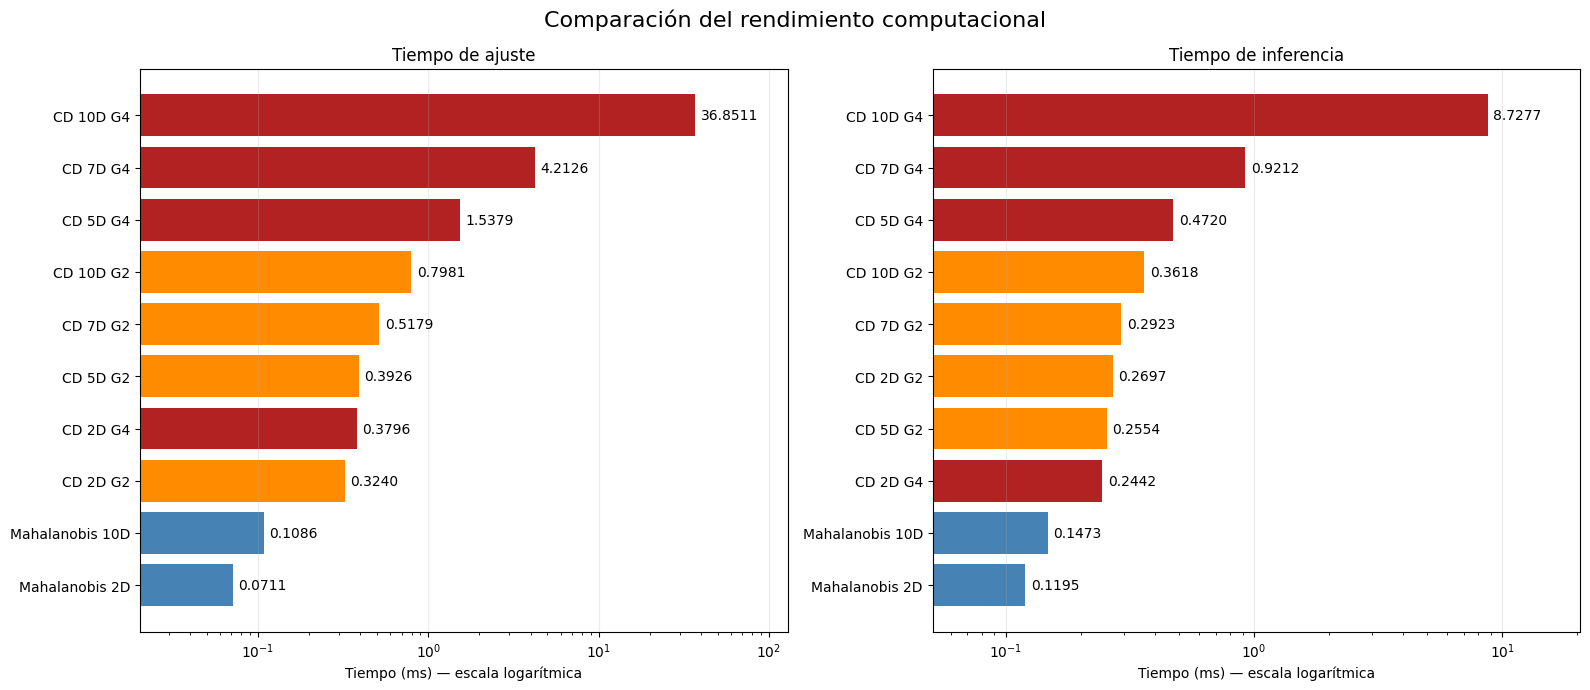

In [245]:
colores_benchmark = {
    "Mahalanobis": "steelblue",
    "CD G2": "darkorange",
    "CD G4": "firebrick"
}

df_benchmark["grupo"] = df_benchmark.apply(
    lambda fila: (
        "Mahalanobis"
        if fila["metodo"] == "Mahalanobis"
        else f"CD G{int(fila['grado'])}"
    ),
    axis=1
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

metricas_tiempo = {
    "tiempo_ajuste_ms": "Tiempo de ajuste",
    "tiempo_inferencia_ms": "Tiempo de inferencia"
}

for ax, (metrica, titulo) in zip(
    axes,
    metricas_tiempo.items()
):

    datos = df_benchmark.sort_values(metrica)

    barras = ax.barh(
        datos["configuracion"],
        datos[metrica],
        color=datos["grupo"].map(colores_benchmark)
    )

    ax.bar_label(
        barras,
        fmt="%.4f",
        padding=4
    )

    ax.set_xscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("Tiempo (ms) — escala logarítmica")

    ax.margins(x=0.20)
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Comparación del rendimiento computacional",
    fontsize=16
)

plt.tight_layout()

fig_benchmark_tiempos = fig

plt.show()

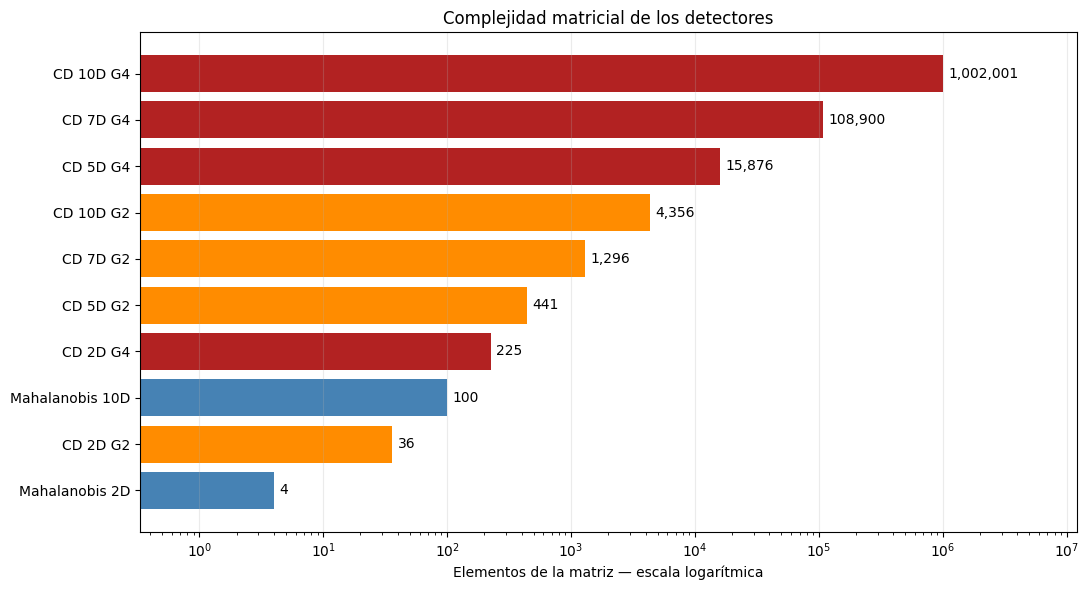

In [246]:
datos = df_benchmark.sort_values(
    "elementos_matriz"
)

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    datos["configuracion"],
    datos["elementos_matriz"],
    color=datos["grupo"].map(colores_benchmark)
)

ax.bar_label(
    barras,
    labels=[
        f"{int(v):,}"
        for v in datos["elementos_matriz"]
    ],
    padding=4
)

ax.set_xscale("log")

ax.set_title(
    "Complejidad matricial de los detectores"
)

ax.set_xlabel(
    "Elementos de la matriz — escala logarítmica"
)

ax.margins(x=0.20)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

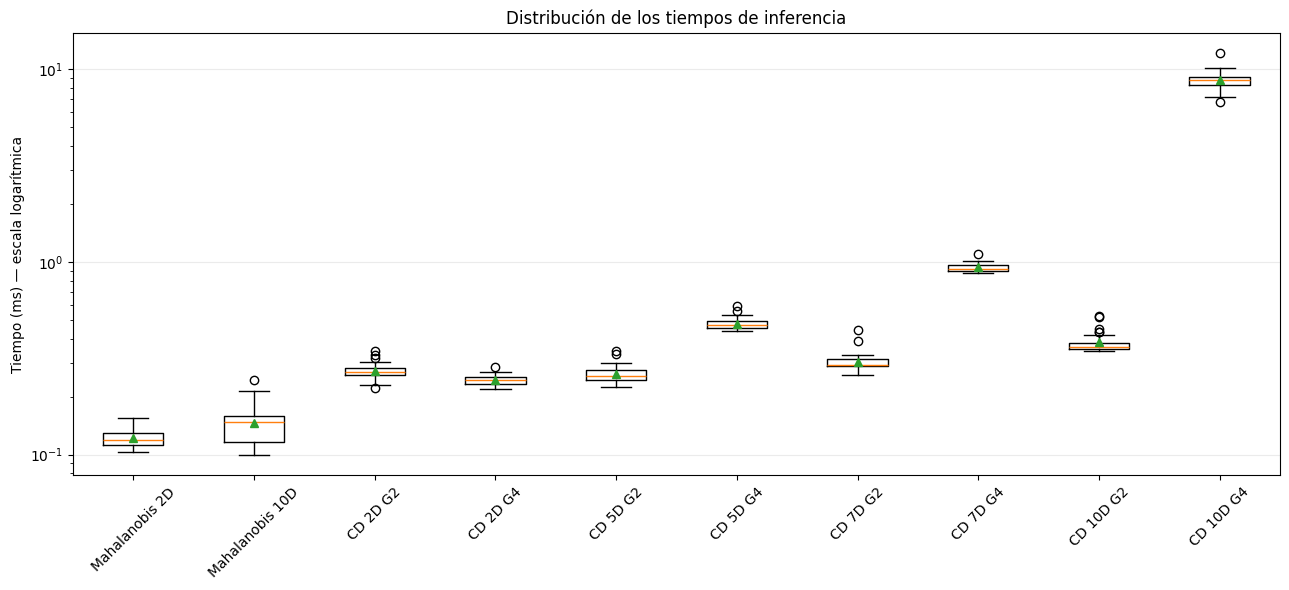

In [247]:
configuraciones = df_benchmark[
    "configuracion"
].tolist()

tiempos_inferencia = [
    mediciones_benchmark[nombre]
    ["inferencia"]["tiempos_s"] * 1000
    for nombre in configuraciones
]

fig, ax = plt.subplots(figsize=(13, 6))

ax.boxplot(
    tiempos_inferencia,
    tick_labels=configuraciones,
    showmeans=True
)

ax.set_yscale("log")

ax.set_title(
    "Distribución de los tiempos de inferencia"
)

ax.set_ylabel(
    "Tiempo (ms) — escala logarítmica"
)

ax.tick_params(
    axis="x",
    labelrotation=45
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [248]:
columnas_benchmark = [
    "configuracion",
    "dimension_matricial",
    "elementos_matriz",
    "memoria_matriz_kib",
    "tiempo_ajuste_ms",
    "tiempo_inferencia_ms",
    "tiempo_total_ms",
    "tiempo_por_transaccion_us",
    "factor_ajuste",
    "factor_inferencia",
    "factor_memoria"
]

df_rendimiento_integral = (
    df_comparacion_final.merge(
        df_benchmark[columnas_benchmark],
        on="configuracion",
        how="inner",
        validate="one_to_one"
    )
)

assert len(df_rendimiento_integral) == 10

display(
    df_rendimiento_integral[
        [
            "configuracion",
            "dimension_matricial",
            "tiempo_ajuste_ms",
            "tiempo_inferencia_ms",
            "factor_inferencia",
            "f1_score",
            "balanced_accuracy",
            "roc_auc"
        ]
    ].round(6)
)

,configuracion,dimension_matricial,tiempo_ajuste_ms,tiempo_inferencia_ms,factor_inferencia,f1_score,balanced_accuracy,roc_auc
0,Mahalanobis 2D,2,0.07110,0.11955,0.811883,0.037209,0.432000,0.476800
1,Mahalanobis 10D,10,0.10860,0.14725,1.000000,0.071429,0.611333,0.608000
2,CD 2D G2,6,0.32405,0.26970,1.831576,0.037736,0.436000,0.464267
3,CD 2D G4,15,0.37960,0.24425,1.658742,0.055556,0.533333,0.448800
4,CD 5D G2,21,0.39260,0.25540,1.734463,0.059701,0.553333,0.518667
5,CD 5D G4,126,1.53785,0.47200,3.205430,0.000000,0.485333,0.578133
6,CD 7D G2,36,0.51795,0.29235,1.985397,0.039216,0.480000,0.502667
7,CD 7D G4,330,4.21255,0.92115,6.255683,0.103448,0.590000,0.591200
8,CD 10D G2,66,0.79810,0.36185,2.457383,0.068966,0.526000,0.623200
9,CD 10D G4,1001,36.85115,8.72770,59.271254,0.057762,0.554667,0.674933


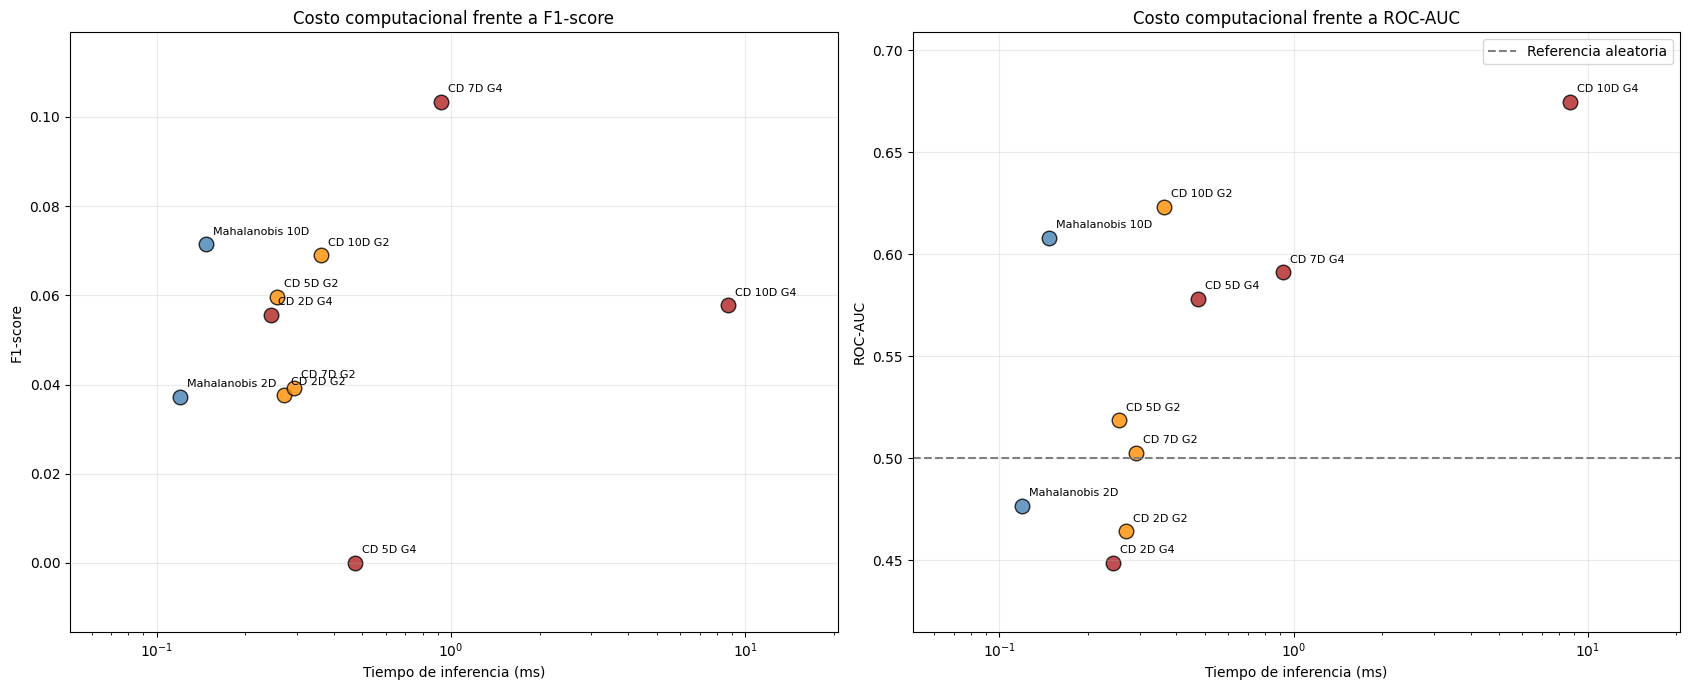

In [249]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7)
)

metricas = {
    "f1_score": "F1-score",
    "roc_auc": "ROC-AUC"
}

for ax, (metrica, titulo) in zip(
    axes,
    metricas.items()
):

    for _, fila in df_rendimiento_integral.iterrows():

        if fila["metodo"] == "Mahalanobis":
            color = "steelblue"

        elif fila["grado"] == 2:
            color = "darkorange"

        else:
            color = "firebrick"

        ax.scatter(
            fila["tiempo_inferencia_ms"],
            fila[metrica],
            s=110,
            color=color,
            edgecolor="black",
            alpha=0.8
        )

        ax.annotate(
            fila["configuracion"],
            (
                fila["tiempo_inferencia_ms"],
                fila[metrica]
            ),
            xytext=(5, 7),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_xscale("log")

    ax.set_xlabel(
        "Tiempo de inferencia (ms)"
    )

    ax.set_ylabel(titulo)

    ax.set_title(
        f"Costo computacional frente a {titulo}"
    )

    ax.margins(x=0.20, y=0.15)
    ax.grid(alpha=0.25)

axes[1].axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Referencia aleatoria"
)

axes[1].legend()

plt.tight_layout()

fig_costo_desempeno = fig

plt.show()

In [250]:
def calcular_frontera_pareto(
    df,
    columna_costo,
    columna_beneficio
):

    resultados = df.copy()

    costos = resultados[columna_costo].to_numpy()
    beneficios = resultados[columna_beneficio].to_numpy()

    no_dominadas = []

    for i in range(len(resultados)):

        domina = (
            (costos <= costos[i])
            & (beneficios >= beneficios[i])
            & (
                (costos < costos[i])
                | (beneficios > beneficios[i])
            )
        )

        no_dominadas.append(
            not np.any(domina)
        )

    resultados["pareto"] = no_dominadas

    return resultados

In [251]:
for metrica in [
    "f1_score",
    "roc_auc",
    "balanced_accuracy"
]:

    df_pareto = calcular_frontera_pareto(
        df_rendimiento_integral,
        columna_costo="tiempo_inferencia_ms",
        columna_beneficio=metrica
    )

    print(f"\nFrontera de Pareto — {metrica}")

    display(
        df_pareto.loc[
            df_pareto["pareto"],
            [
                "configuracion",
                "tiempo_inferencia_ms",
                metrica
            ]
        ]
        .sort_values("tiempo_inferencia_ms")
        .round(6)
    )


Frontera de Pareto — f1_score


,configuracion,tiempo_inferencia_ms,f1_score
0,Mahalanobis 2D,0.11955,0.037209
1,Mahalanobis 10D,0.14725,0.071429
7,CD 7D G4,0.92115,0.103448



Frontera de Pareto — roc_auc


,configuracion,tiempo_inferencia_ms,roc_auc
0,Mahalanobis 2D,0.11955,0.476800
1,Mahalanobis 10D,0.14725,0.608000
8,CD 10D G2,0.36185,0.623200
9,CD 10D G4,8.72770,0.674933



Frontera de Pareto — balanced_accuracy


,configuracion,tiempo_inferencia_ms,balanced_accuracy
0,Mahalanobis 2D,0.11955,0.432000
1,Mahalanobis 10D,0.14725,0.611333


In [253]:
ruta_resultados = Path("../reports/figures")

ruta_resultados.mkdir(
    parents=True,
    exist_ok=True
)

ruta_figuras = ruta_resultados / "figuras"

ruta_figuras.mkdir(
    parents=True,
    exist_ok=True
)

df_benchmark.to_csv(
    ruta_resultados / "benchmark_computacional.csv",
    index=False
)

df_rendimiento_integral.to_csv(
    ruta_resultados / "comparacion_integral.csv",
    index=False
)

fig_benchmark_tiempos.savefig(
    ruta_figuras / "benchmark_tiempos.png",
    dpi=300,
    bbox_inches="tight"
)

fig_costo_desempeno.savefig(
    ruta_figuras / "costo_desempeno.png",
    dpi=300,
    bbox_inches="tight"
)

print("Resultados exportados correctamente.")

Resultados exportados correctamente.


#### 7.7. Conclusiones generales